
# Earthquake Damage Prediction
## PRCP-1015 | Data Science Capstone Project

### 1. Project Introduction

Earthquakes are natural disasters that can cause severe
structural damage to buildings, resulting in loss of life,
property destruction, and economic disruption.

This project focuses on predicting building damage severity
using data collected following the 2015 Gorkha earthquake
in Nepal.

The dataset contains information about building characteristics,
including geographic location, building age, number of floors,
construction materials, foundation type, and structural features.

The objective is to develop a machine learning classification
model that predicts the damage grade of buildings.

### 2. Target Variable

The target variable is `damage_grade`, which represents
three levels of earthquake-related building damage:

- **Grade 1:** Low damage
- **Grade 2:** Medium damage
- **Grade 3:** Almost complete destruction

### 3. Project Objectives

1. Perform comprehensive Exploratory Data Analysis (EDA).
2. Identify factors associated with building damage severity.
3. Clean and preprocess the dataset.
4. Develop and compare multiple machine learning models.
5. Optimize model performance using appropriate techniques.
6. Evaluate models using reliable classification metrics.
7. Explain important features influencing predictions.
8. Provide evidence-based recommendations for reducing
   earthquake-related building damage.

### 4. Dataset Information

The project uses two training datasets:

- `train_values.csv`: Building characteristics (features).
- `train_labels.csv`: Actual building damage grades (target).

The datasets are connected using `building_id`.

### 5. Project Approach

This project follows a supervised machine learning approach
to multiclass ordinal classification.

The workflow includes data inspection, EDA, preprocessing,
feature engineering, model development, hyperparameter
optimization, validation, explainability, and final reporting.


In [5]:
import pandas as pd
import numpy as np
print("Pandas version:", pd.__version__)
print("NumPy version:", np.__version__)
print("Libraries imported successfully!")


Pandas version: 3.0.3
NumPy version: 2.4.2
Libraries imported successfully!


In [2]:
train_values = pd.read_csv("train_values.csv")
train_labels = pd.read_csv("train_labels.csv")
print("Training Features Shape:", train_values.shape)
print("Training Labels Shape:", train_labels.shape)
print("\nFirst 5 rows of Training Features:")
display(train_values.head())
print("\nFirst 5 rows of Training Labels:")
display(train_labels.head())


Training Features Shape: (260601, 39)
Training Labels Shape: (260601, 2)

First 5 rows of Training Features:


,building_id,geo_level_1_id,geo_level_2_id,geo_level_3_id,count_floors_pre_eq,age,area_percentage,height_percentage,land_surface_condition,foundation_type,...,has_secondary_use_agriculture,has_secondary_use_hotel,has_secondary_use_rental,has_secondary_use_institution,has_secondary_use_school,has_secondary_use_industry,has_secondary_use_health_post,has_secondary_use_gov_office,has_secondary_use_use_police,has_secondary_use_other
0,802906,6,487,12198,2,30,6,5,t,r,...,0,0,0,0,0,0,0,0,0,0
1,28830,8,900,2812,2,10,8,7,o,r,...,0,0,0,0,0,0,0,0,0,0
2,94947,21,363,8973,2,10,5,5,t,r,...,0,0,0,0,0,0,0,0,0,0
3,590882,22,418,10694,2,10,6,5,t,r,...,0,0,0,0,0,0,0,0,0,0
4,201944,11,131,1488,3,30,8,9,t,r,...,0,0,0,0,0,0,0,0,0,0



First 5 rows of Training Labels:


,building_id,damage_grade
0,802906,3
1,28830,2
2,94947,3
3,590882,2
4,201944,3


In [4]:
print("TRAINING FEATURES INFORMATION")
print("=" * 50)
train_values.info()
print("\nTRAINING LABELS INFORMATION")
print("=" * 50)
train_labels.info()


TRAINING FEATURES INFORMATION
<class 'pandas.DataFrame'>
RangeIndex: 260601 entries, 0 to 260600
Data columns (total 39 columns):
 #   Column                                  Non-Null Count   Dtype
---  ------                                  --------------   -----
 0   building_id                             260601 non-null  int64
 1   geo_level_1_id                          260601 non-null  int64
 2   geo_level_2_id                          260601 non-null  int64
 3   geo_level_3_id                          260601 non-null  int64
 4   count_floors_pre_eq                     260601 non-null  int64
 5   age                                     260601 non-null  int64
 6   area_percentage                         260601 non-null  int64
 7   height_percentage                       260601 non-null  int64
 8   land_surface_condition                  260601 non-null  str  
 9   foundation_type                         260601 non-null  str  
 10  roof_type                               260601 no

In [6]:


print("Missing values in training features:",
      train_values.isnull().sum().sum())

print("Missing values in training labels:",
      train_labels.isnull().sum().sum())



print("\nDuplicate IDs in training features:",
      train_values["building_id"].duplicated().sum())

print("Duplicate IDs in training labels:",
      train_labels["building_id"].duplicated().sum())



feature_ids = set(train_values["building_id"])
label_ids = set(train_labels["building_id"])

print("\nBuildings missing labels:",
      len(feature_ids - label_ids))

print("Labels without matching buildings:",
      len(label_ids - feature_ids))


Missing values in training features: 0
Missing values in training labels: 0

Duplicate IDs in training features: 0
Duplicate IDs in training labels: 0

Buildings missing labels: 0
Labels without matching buildings: 0


In [7]:

# Merge training features and labels using building_id

df = pd.merge(
    train_values,
    train_labels,
    on="building_id",
    how="inner",
    validate="one_to_one"
)

# Display merged dataset information
print("Merged Dataset Shape:", df.shape)

print("\nFirst 5 rows of Merged Dataset:")
display(df.head())

# Verify that no records were lost
print("\nOriginal Building Count:", len(train_values))
print("Merged Building Count:", len(df))


Merged Dataset Shape: (260601, 40)

First 5 rows of Merged Dataset:


,building_id,geo_level_1_id,geo_level_2_id,geo_level_3_id,count_floors_pre_eq,age,area_percentage,height_percentage,land_surface_condition,foundation_type,...,has_secondary_use_hotel,has_secondary_use_rental,has_secondary_use_institution,has_secondary_use_school,has_secondary_use_industry,has_secondary_use_health_post,has_secondary_use_gov_office,has_secondary_use_use_police,has_secondary_use_other,damage_grade
0,802906,6,487,12198,2,30,6,5,t,r,...,0,0,0,0,0,0,0,0,0,3
1,28830,8,900,2812,2,10,8,7,o,r,...,0,0,0,0,0,0,0,0,0,2
2,94947,21,363,8973,2,10,5,5,t,r,...,0,0,0,0,0,0,0,0,0,3
3,590882,22,418,10694,2,10,6,5,t,r,...,0,0,0,0,0,0,0,0,0,2
4,201944,11,131,1488,3,30,8,9,t,r,...,0,0,0,0,0,0,0,0,0,3



Original Building Count: 260601
Merged Building Count: 260601


In [8]:
numerical_features = [
    "count_floors_pre_eq",
    "age",
    "area_percentage",
    "height_percentage",
    "count_families"
]
summary_stats = df[numerical_features].describe().T
print("DESCRIPTIVE STATISTICS")
print("=" * 60)
display(summary_stats)


DESCRIPTIVE STATISTICS


,count,mean,std,min,25%,50%,75%,max
count_floors_pre_eq,260601.0,2.129723,0.727665,1.0,2.0,2.0,2.0,9.0
age,260601.0,26.535029,73.565937,0.0,10.0,15.0,30.0,995.0
area_percentage,260601.0,8.018051,4.392231,1.0,5.0,7.0,9.0,100.0
height_percentage,260601.0,5.434365,1.918418,2.0,4.0,5.0,6.0,32.0
count_families,260601.0,0.983949,0.418389,0.0,1.0,1.0,1.0,9.0


In [9]:

# Investigate building age distribution

print("TOP 10 MOST COMMON BUILDING AGES")
print("=" * 50)

display(df["age"].value_counts().head(10))


# Check potentially unusual age values

age_checks = pd.DataFrame({
    "Condition": [
        "Age = 0",
        "Age >= 100",
        "Age >= 200",
        "Age = 995"
    ],
    "Number of Buildings": [
        (df["age"] == 0).sum(),
        (df["age"] >= 100).sum(),
        (df["age"] >= 200).sum(),
        (df["age"] == 995).sum()
    ]
})

# Calculate percentages
age_checks["Percentage (%)"] = (
    age_checks["Number of Buildings"] / len(df) * 100
).round(2)

print("\nUNUSUAL AGE VALUE ANALYSIS")
print("=" * 50)

display(age_checks)


TOP 10 MOST COMMON BUILDING AGES


age
10    38896
15    36010
5     33697
20    32182
0     26041
25    24366
30    18028
35    10710
40    10559
50     7257
Name: count, dtype: int64


UNUSUAL AGE VALUE ANALYSIS


,Condition,Number of Buildings,Percentage (%)
0,Age = 0,26041,9.99
1,Age >= 100,3488,1.34
2,Age >= 200,1496,0.57
3,Age = 995,1390,0.53


In [10]:

# Investigate older building ages
print("MOST COMMON AGES >= 100")
print("=" * 50)

older_buildings = df.loc[df["age"] >= 100, "age"]

display(older_buildings.value_counts().head(20))


# Investigate rounding patterns in building ages
print("\nAGE ROUNDING ANALYSIS")
print("=" * 50)

age_remainders = df["age"] % 5

display(age_remainders.value_counts().sort_index())

# Percentage of ages divisible by 5
rounded_percentage = (age_remainders == 0).mean() * 100

print("\nPercentage of ages divisible by 5:",
      round(rounded_percentage, 2), "%")


MOST COMMON AGES >= 100


age
995    1390
100    1364
120     180
150     142
200     106
110     100
105      89
125      37
115      21
130       9
140       9
180       7
160       6
170       6
175       5
135       5
190       3
145       3
195       2
165       2
Name: count, dtype: int64


AGE ROUNDING ANALYSIS


age
0    260601
Name: count, dtype: int64


Percentage of ages divisible by 5: 100.0 %


In [11]:

# Identify categorical columns

categorical_features = df.select_dtypes(
    include=["str", "object", "category"]
).columns.tolist()

print("Number of categorical features:",
      len(categorical_features))

print("\nCATEGORICAL FEATURE ANALYSIS")
print("=" * 60)

# Inspect unique categories in each column
for column in categorical_features:

    print("\nFeature:", column)

    print("Number of unique categories:",
          df[column].nunique())

    print("Categories:",
          sorted(df[column].unique().tolist()))

    print("-" * 50)


Number of categorical features: 8

CATEGORICAL FEATURE ANALYSIS

Feature: land_surface_condition
Number of unique categories: 3
Categories: ['n', 'o', 't']
--------------------------------------------------

Feature: foundation_type
Number of unique categories: 5
Categories: ['h', 'i', 'r', 'u', 'w']
--------------------------------------------------

Feature: roof_type
Number of unique categories: 3
Categories: ['n', 'q', 'x']
--------------------------------------------------

Feature: ground_floor_type
Number of unique categories: 5
Categories: ['f', 'm', 'v', 'x', 'z']
--------------------------------------------------

Feature: other_floor_type
Number of unique categories: 4
Categories: ['j', 'q', 's', 'x']
--------------------------------------------------

Feature: position
Number of unique categories: 4
Categories: ['j', 'o', 's', 't']
--------------------------------------------------

Feature: plan_configuration
Number of unique categories: 10
Categories: ['a', 'c', 'd', 'f',

In [12]:

# Identify binary indicator columns

binary_features = [
    col for col in df.columns
    if col.startswith(("has_superstructure_", "has_secondary_use"))
]

print("Number of binary features:", len(binary_features))

# Check whether each feature contains only 0 and 1
binary_validation = pd.DataFrame({
    "Zero_Count": df[binary_features].eq(0).sum(),
    "One_Count": df[binary_features].eq(1).sum(),
    "Invalid_Count": (
        ~df[binary_features].isin([0, 1])
    ).sum()
})

# Calculate percentage of buildings with value 1
binary_validation["One_Percentage"] = (
    df[binary_features].eq(1).mean() * 100
).round(2)

print("\nBINARY FEATURE VALIDATION")
print("=" * 60)

display(binary_validation)

# Check overall validity
print("\nAll binary features valid:",
      (binary_validation["Invalid_Count"] == 0).all())


Number of binary features: 22

BINARY FEATURE VALIDATION


,Zero_Count,One_Count,Invalid_Count,One_Percentage
has_superstructure_adobe_mud,237500,23101,0,8.86
has_superstructure_mud_mortar_stone,62040,198561,0,76.19
has_superstructure_stone_flag,251654,8947,0,3.43
has_superstructure_cement_mortar_stone,255849,4752,0,1.82
has_superstructure_mud_mortar_brick,242840,17761,0,6.82
has_superstructure_cement_mortar_brick,240986,19615,0,7.53
has_superstructure_timber,194151,66450,0,25.50
has_superstructure_bamboo,238447,22154,0,8.50
has_superstructure_rc_non_engineered,249502,11099,0,4.26
has_superstructure_rc_engineered,256468,4133,0,1.59



All binary features valid: True


In [13]:

# Select geographic identifier columns

geo_features = [
    "geo_level_1_id",
    "geo_level_2_id",
    "geo_level_3_id"
]

# Analyze geographic identifier ranges and diversity
geo_summary = pd.DataFrame({
    "Unique Regions": df[geo_features].nunique(),
    "Minimum ID": df[geo_features].min(),
    "Maximum ID": df[geo_features].max()
})

print("GEOGRAPHIC FEATURE SUMMARY")
print("=" * 60)

display(geo_summary)


# Find the 10 most frequently represented Level 1 regions

print("\nTOP 10 GEOGRAPHIC LEVEL 1 REGIONS")
print("=" * 60)

top_regions = (
    df["geo_level_1_id"]
    .value_counts()
    .head(10)
)

display(top_regions)


GEOGRAPHIC FEATURE SUMMARY


,Unique Regions,Minimum ID,Maximum ID
geo_level_1_id,31,0,30
geo_level_2_id,1414,0,1427
geo_level_3_id,11595,0,12567



TOP 10 GEOGRAPHIC LEVEL 1 REGIONS


geo_level_1_id
6     24381
26    22615
10    22079
17    21813
8     19080
7     18994
20    17216
21    14889
4     14568
27    12532
Name: count, dtype: int64

In [14]:

# Analyze the distribution of earthquake damage grades

# Count buildings in each damage grade
grade_counts = df["damage_grade"].value_counts().sort_index()

# Calculate the percentage of each damage grade
grade_percentages = (
    df["damage_grade"]
    .value_counts(normalize=True)
    .sort_index() * 100
)

# Create a summary table
grade_summary = pd.DataFrame({
    "Number of Buildings": grade_counts,
    "Percentage (%)": grade_percentages.round(2)
})

grade_summary.index.name = "Damage Grade"

print("DAMAGE GRADE DISTRIBUTION")
print("=" * 60)

display(grade_summary)

# Verify the expected target classes
print("\nUnique damage grades:",
      sorted(df["damage_grade"].unique()))

print("Most common damage grade:",
      grade_counts.idxmax())


DAMAGE GRADE DISTRIBUTION


,Number of Buildings,Percentage (%)
Damage Grade,,
1,25124,9.64
2,148259,56.89
3,87218,33.47



Unique damage grades: [np.int64(1), np.int64(2), np.int64(3)]
Most common damage grade: 2


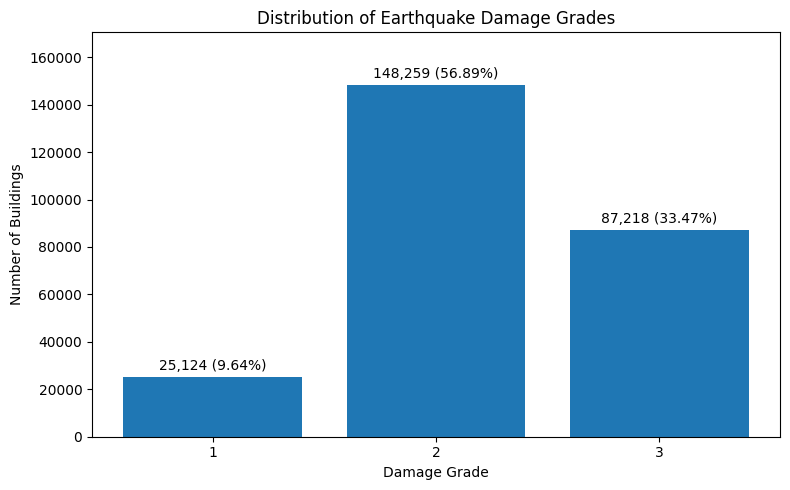

In [15]:

# Import visualization library
import matplotlib.pyplot as plt

# Create the figure
fig, ax = plt.subplots(figsize=(8, 5))

# Create the bar chart
bars = ax.bar(
    grade_counts.index.astype(str),
    grade_counts.values
)

# Add counts and percentages above the bars
labels = [
    f"{count:,} ({pct:.2f}%)"
    for count, pct in zip(
        grade_counts.values,
        grade_percentages.values
    )
]

ax.bar_label(bars, labels=labels, padding=3)

# Add chart titles and labels
ax.set_title("Distribution of Earthquake Damage Grades")
ax.set_xlabel("Damage Grade")
ax.set_ylabel("Number of Buildings")

# Add space above the bars
ax.set_ylim(0, grade_counts.max() * 1.15)

# Display the chart
plt.tight_layout()
plt.show()


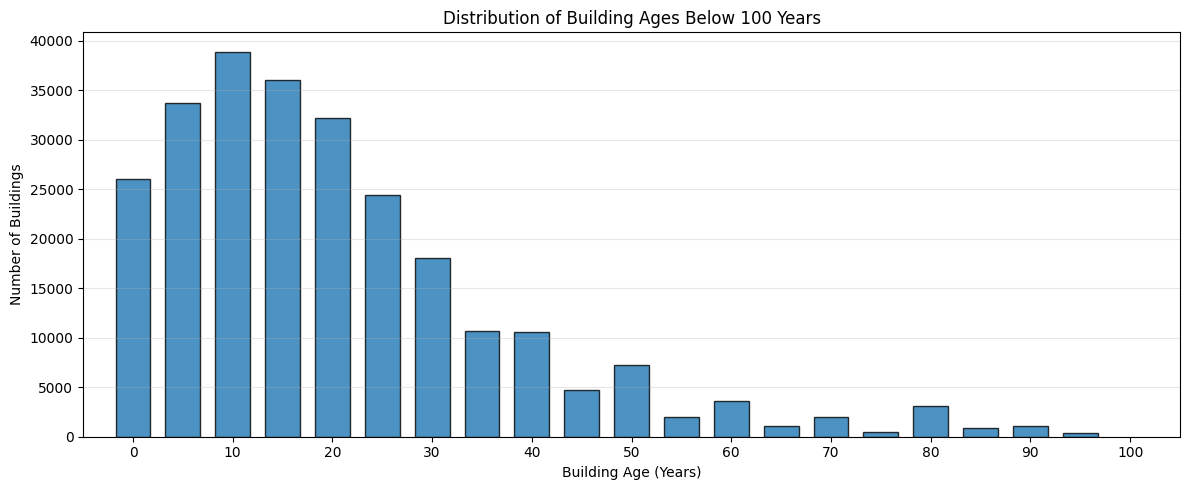

In [16]:

# Analyze building age distribution

# Select buildings younger than 100 years
age_data = df.loc[df["age"] < 100, "age"]

# Count buildings for each recorded age
age_counts = age_data.value_counts().sort_index()

# Create the visualization
plt.figure(figsize=(12, 5))

plt.bar(
    age_counts.index,
    age_counts.values,
    width=3.5,
    edgecolor="black",
    alpha=0.8
)

# Add titles and labels
plt.title("Distribution of Building Ages Below 100 Years")
plt.xlabel("Building Age (Years)")
plt.ylabel("Number of Buildings")

# Configure the horizontal axis
plt.xticks(range(0, 101, 10))
plt.xlim(-5, 105)

# Add horizontal grid lines
plt.grid(axis="y", alpha=0.3)

# Display the chart
plt.tight_layout()
plt.show()


BUILDINGS IN EACH AGE GROUP


age
0           26041
5-20       140785
25-40       63663
45-60       17613
65-95        9011
100-994      2098
995          1390
Name: count, dtype: int64


DAMAGE GRADE PERCENTAGES BY AGE GROUP


damage_grade,1,2,3
age,,,
0,27.70,48.85,23.45
5-20,10.50,57.37,32.13
25-40,3.78,57.88,38.34
45-60,2.33,58.41,39.26
65-95,1.25,60.38,38.36
100-994,0.95,65.11,33.94
995,12.88,59.14,27.99


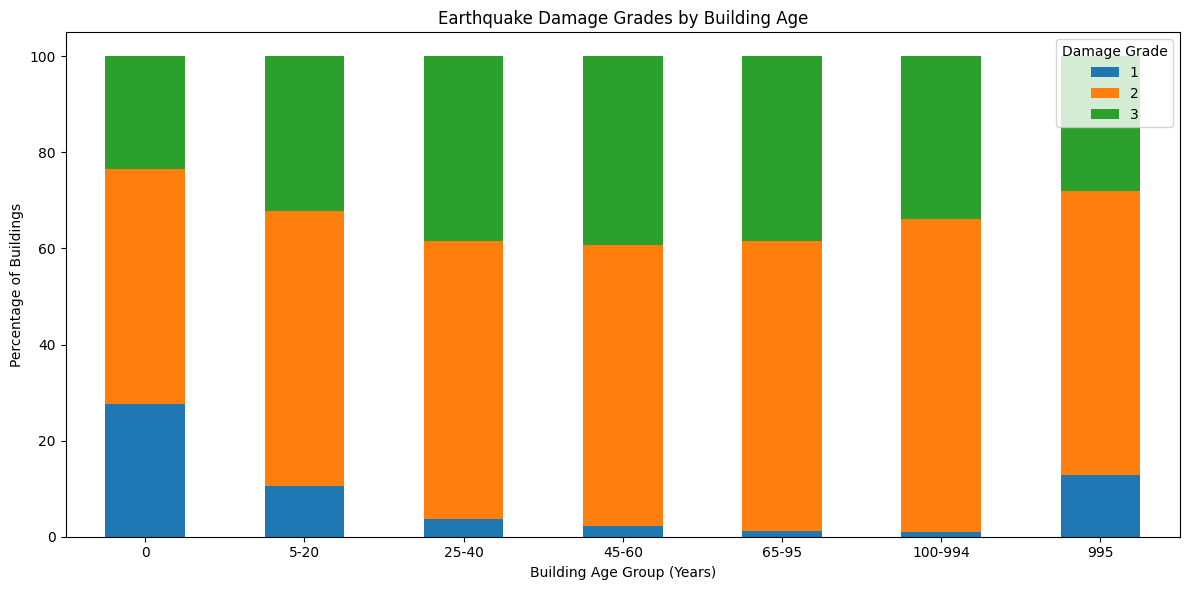

In [17]:

# Create building age groups

age_groups = pd.cut(
    df["age"],
    bins=[-1, 0, 20, 40, 60, 95, 994, 995],
    labels=[
        "0",
        "5-20",
        "25-40",
        "45-60",
        "65-95",
        "100-994",
        "995"
    ]
)

# Count the buildings in each age group
age_group_counts = age_groups.value_counts(sort=False)

# Calculate damage grade percentages within age groups
age_damage = pd.crosstab(
    age_groups,
    df["damage_grade"],
    normalize="index"
) * 100

print("BUILDINGS IN EACH AGE GROUP")
display(age_group_counts)

print("\nDAMAGE GRADE PERCENTAGES BY AGE GROUP")
display(age_damage.round(2))

# Visualize the relationship
ax = age_damage.plot(
    kind="bar",
    stacked=True,
    figsize=(12, 6)
)

ax.set_title("Earthquake Damage Grades by Building Age")
ax.set_xlabel("Building Age Group (Years)")
ax.set_ylabel("Percentage of Buildings")
ax.legend(title="Damage Grade")
ax.tick_params(axis="x", rotation=0)

plt.tight_layout()
plt.show()


In [18]:

# Select building superstructure material features

material_features = [
    col for col in df.columns
    if col.startswith("has_superstructure_")
]

# Store analysis results
material_results = []

# Analyze each material
for material in material_features:

    # Buildings with this material
    with_material = df[material] == 1

    # Buildings without this material
    without_material = df[material] == 0

    # Calculate severe-damage percentages
    severe_with = (
        df.loc[with_material, "damage_grade"]
        .eq(3).mean() * 100
    )

    severe_without = (
        df.loc[without_material, "damage_grade"]
        .eq(3).mean() * 100
    )

    material_results.append({
        "Material": material.replace("has_superstructure_", ""),
        "Building Count": with_material.sum(),
        "Grade 3 With (%)": round(severe_with, 2),
        "Grade 3 Without (%)": round(severe_without, 2),
        "Difference (pp)": round(
            severe_with - severe_without, 2
        )
    })

# Create results table
material_analysis = pd.DataFrame(material_results)

# Sort by difference in severe-damage percentage
material_analysis = material_analysis.sort_values(
    "Difference (pp)",
    ascending=False
)

print("CONSTRUCTION MATERIAL DAMAGE ANALYSIS")
print("=" * 60)

display(material_analysis)


CONSTRUCTION MATERIAL DAMAGE ANALYSIS


,Material,Building Count,Grade 3 With (%),Grade 3 Without (%),Difference (pp)
1,mud_mortar_stone,198561,38.20,18.32,19.88
2,stone_flag,8947,47.29,32.98,14.31
0,adobe_mud,23101,37.25,33.10,4.15
4,mud_mortar_brick,17761,30.63,33.68,-3.05
6,timber,66450,28.02,35.33,-7.31
10,other,3905,25.63,33.59,-7.95
7,bamboo,22154,23.99,34.35,-10.36
3,cement_mortar_stone,4752,14.20,33.83,-19.62
8,rc_non_engineered,11099,12.70,34.39,-21.69
5,cement_mortar_brick,19615,5.55,35.74,-30.19


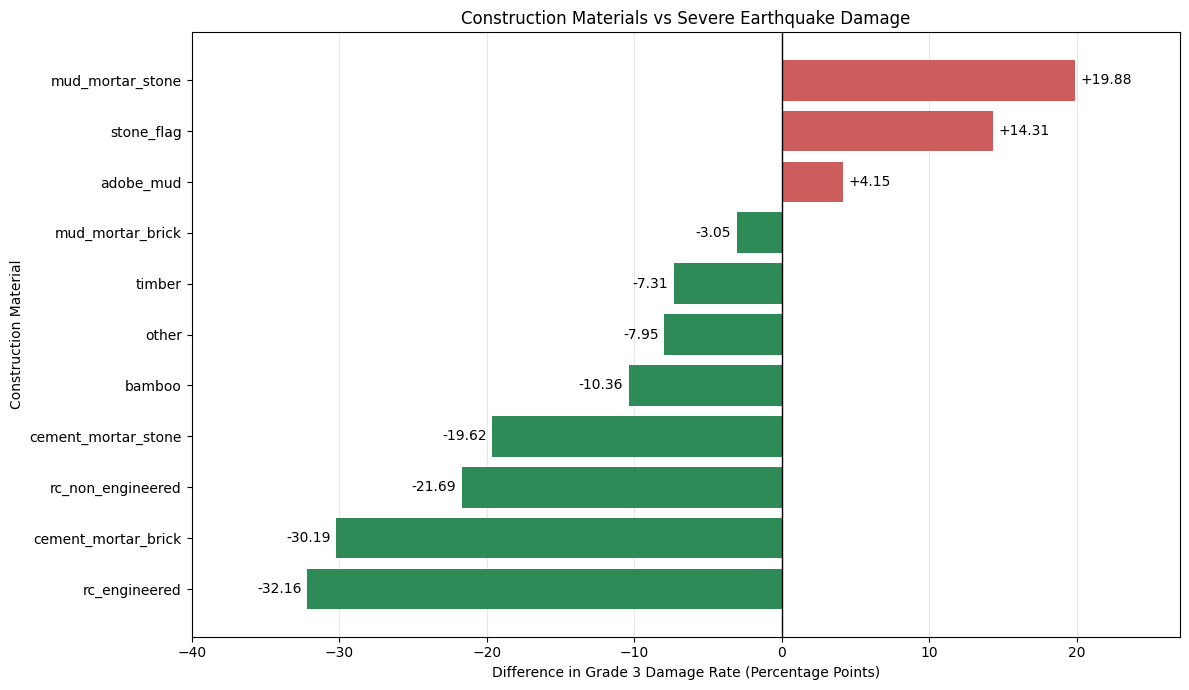

In [19]:

# Sort construction materials by damage difference
plot_data = material_analysis.sort_values(
    "Difference (pp)"
)

# Assign colors based on the direction of difference
colors = [
    "seagreen" if value < 0 else "indianred"
    for value in plot_data["Difference (pp)"]
]

# Create the figure
fig, ax = plt.subplots(figsize=(12, 7))

# Create horizontal bars
bars = ax.barh(
    plot_data["Material"],
    plot_data["Difference (pp)"],
    color=colors
)

# Add a reference line at zero
ax.axvline(0, color="black", linewidth=1)

# Add percentage-point labels to the bars
ax.bar_label(
    bars,
    fmt="%+.2f",
    padding=4
)

# Add titles and axis labels
ax.set_title(
    "Construction Materials vs Severe Earthquake Damage"
)
ax.set_xlabel(
    "Difference in Grade 3 Damage Rate (Percentage Points)"
)
ax.set_ylabel("Construction Material")

# Add space for labels
ax.set_xlim(-40, 27)

# Add a light grid
ax.grid(axis="x", alpha=0.3)
ax.set_axisbelow(True)

# Display the chart
plt.tight_layout()
plt.show()


FOUNDATION TYPE DAMAGE ANALYSIS


damage_grade,Building Count,1,2,3
foundation_type,,,,
r,219196,4.89,57.26,37.85
h,1448,24.72,39.99,35.29
u,14260,25.87,59.89,14.24
w,15118,28.79,61.32,9.89
i,10579,56.75,41.16,2.09


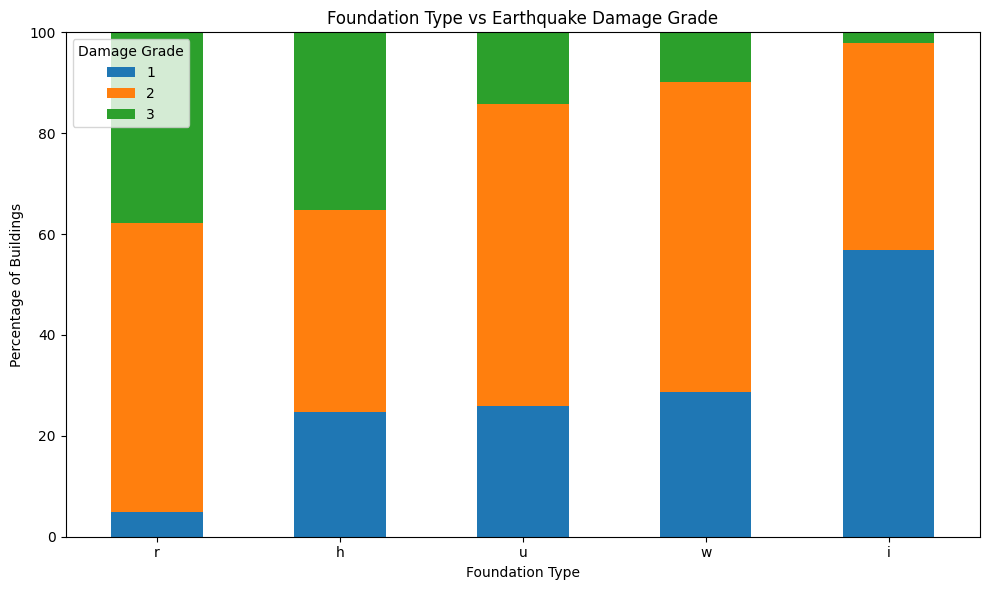

In [20]:

# Analyze foundation type vs earthquake damage

# Step 1: Count buildings by foundation type
foundation_counts = df["foundation_type"].value_counts()

# Step 2: Calculate damage percentages by foundation
foundation_damage = pd.crosstab(
    df["foundation_type"],
    df["damage_grade"],
    normalize="index"
) * 100

# Step 3: Create a summary table
foundation_summary = foundation_damage.round(2).copy()

foundation_summary.insert(
    0,
    "Building Count",
    foundation_counts.reindex(foundation_summary.index)
)

# Step 4: Sort by severe damage percentage
foundation_summary = foundation_summary.sort_values(
    by=3,
    ascending=False
)

print("FOUNDATION TYPE DAMAGE ANALYSIS")
print("=" * 60)

display(foundation_summary)

# Step 5: Visualize damage percentages
ax = foundation_summary[[1, 2, 3]].plot(
    kind="bar",
    stacked=True,
    figsize=(10, 6)
)

ax.set_title("Foundation Type vs Earthquake Damage Grade")
ax.set_xlabel("Foundation Type")
ax.set_ylabel("Percentage of Buildings")

ax.set_ylim(0, 100)
ax.legend(title="Damage Grade")
ax.tick_params(axis="x", rotation=0)

plt.tight_layout()
plt.show()


ROOF TYPE DAMAGE ANALYSIS


damage_grade,Building Count,1,2,3
roof_type,,,,
q,61576,6.38,55.23,38.39
n,182842,7.41,58.22,34.37
x,16183,47.28,48.22,4.50


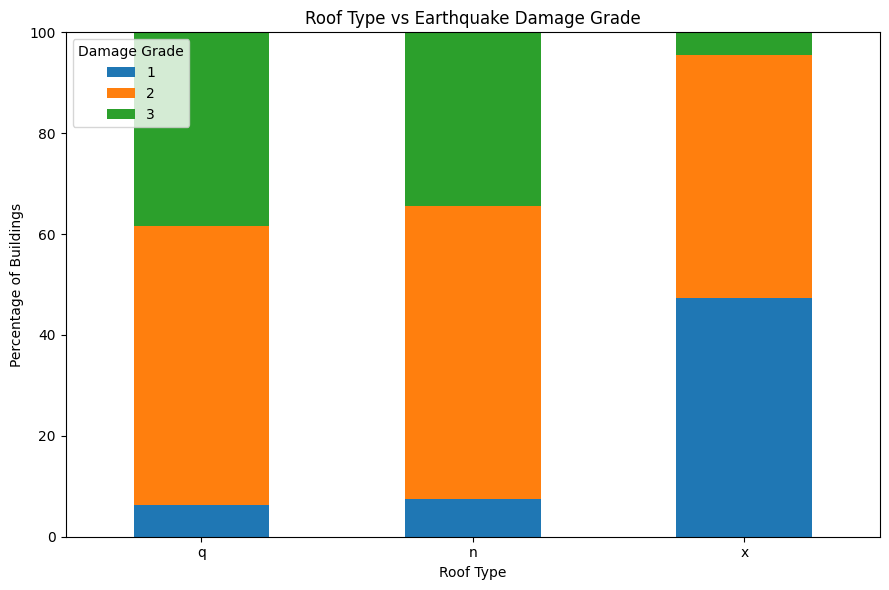

In [21]:

# Analyze roof type vs earthquake damage

# Step 1: Count buildings by roof type
roof_counts = df["roof_type"].value_counts()

# Step 2: Calculate damage grade percentages
roof_damage = pd.crosstab(
    df["roof_type"],
    df["damage_grade"],
    normalize="index"
) * 100

# Step 3: Create a summary table
roof_summary = roof_damage.round(2).copy()

roof_summary.insert(
    0,
    "Building Count",
    roof_counts.reindex(roof_summary.index)
)

# Step 4: Sort by severe damage percentage
roof_summary = roof_summary.sort_values(
    by=3,
    ascending=False
)

print("ROOF TYPE DAMAGE ANALYSIS")
print("=" * 60)

display(roof_summary)

# Step 5: Visualize damage distribution
ax = roof_summary[[1, 2, 3]].plot(
    kind="bar",
    stacked=True,
    figsize=(9, 6)
)

ax.set_title("Roof Type vs Earthquake Damage Grade")
ax.set_xlabel("Roof Type")
ax.set_ylabel("Percentage of Buildings")

ax.set_ylim(0, 100)
ax.legend(title="Damage Grade")
ax.tick_params(axis="x", rotation=0)

plt.tight_layout()
plt.show()


NUMBER OF FLOORS VS DAMAGE GRADE


damage_grade,Building Count,1,2,3
count_floors_pre_eq,,,,
1,40441,22.18,51.43,26.39
2,156623,8.04,60.00,31.96
3,55617,4.56,51.21,44.23
4,5424,13.03,62.21,24.76
5,2246,11.31,65.94,22.75
6,209,25.36,63.64,11.00
7,39,25.64,64.10,10.26
8,1,0.00,100.00,0.00
9,1,100.00,0.00,0.00


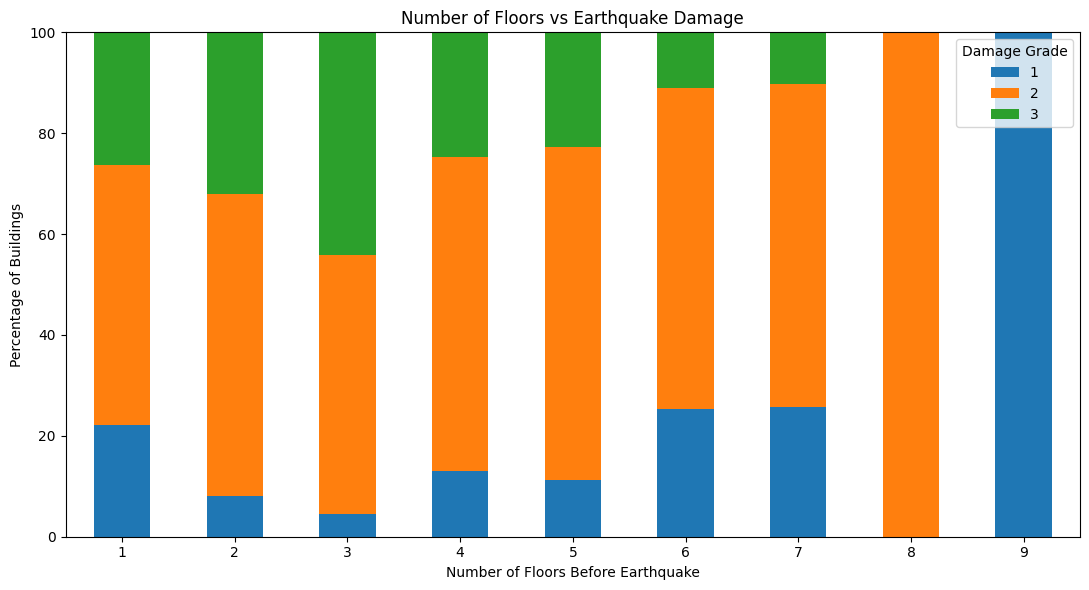

In [22]:

# Analyze number of floors vs earthquake damage

# Step 1: Count buildings by number of floors
floor_counts = (
    df["count_floors_pre_eq"]
    .value_counts()
    .sort_index()
)

# Step 2: Calculate damage percentages for each floor count
floor_damage = pd.crosstab(
    df["count_floors_pre_eq"],
    df["damage_grade"],
    normalize="index"
) * 100

# Step 3: Create a summary table
floor_summary = floor_damage.round(2).copy()

floor_summary.insert(
    0,
    "Building Count",
    floor_counts.reindex(floor_summary.index)
)

print("NUMBER OF FLOORS VS DAMAGE GRADE")
print("=" * 60)

display(floor_summary)

# Step 4: Visualize damage grade distribution
ax = floor_damage.plot(
    kind="bar",
    stacked=True,
    figsize=(11, 6)
)

ax.set_title("Number of Floors vs Earthquake Damage")
ax.set_xlabel("Number of Floors Before Earthquake")
ax.set_ylabel("Percentage of Buildings")

ax.set_ylim(0, 100)
ax.legend(title="Damage Grade")
ax.tick_params(axis="x", rotation=0)

plt.tight_layout()
plt.show()


GEOGRAPHIC DAMAGE ANALYSIS


damage_grade,Building Count,Grade 1 (%),Grade 2 (%),Grade 3 (%)
geo_level_1_id,,,,
17,21813,1.31,17.94,80.75
18,3189,2.26,24.65,73.10
21,14889,2.16,39.34,58.50
8,19080,3.43,44.62,51.95
27,12532,3.71,47.93,48.36
28,265,0.00,59.25,40.75
10,22079,5.48,54.83,39.68
11,8220,4.70,56.84,38.47
3,7540,3.25,60.34,36.41


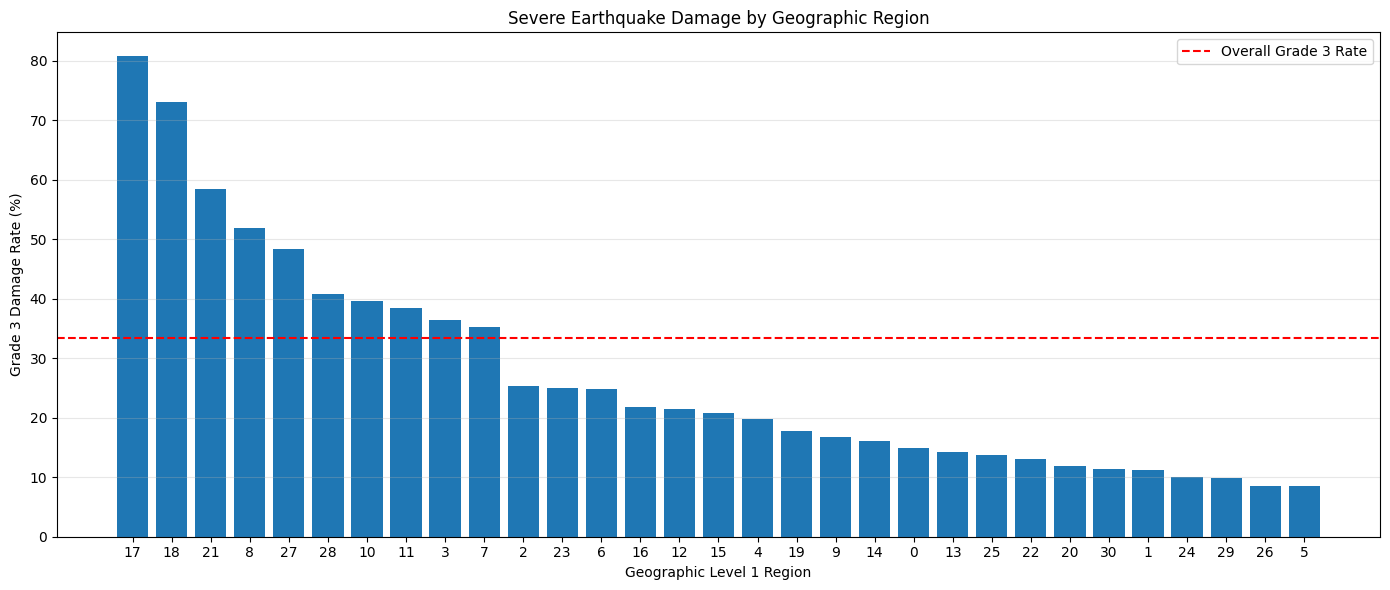

In [23]:

# Analyze geographic regions vs earthquake damage

# Step 1: Count buildings in each geographic region
geo_counts = df["geo_level_1_id"].value_counts()

# Step 2: Calculate damage percentages within each region
geo_damage = pd.crosstab(
    df["geo_level_1_id"],
    df["damage_grade"],
    normalize="index"
) * 100

# Step 3: Create a summary table
geo_summary = geo_damage.rename(
    columns={
        1: "Grade 1 (%)",
        2: "Grade 2 (%)",
        3: "Grade 3 (%)"
    }
).round(2).copy()

# Step 4: Add the building count
geo_summary.insert(
    0,
    "Building Count",
    geo_counts.reindex(geo_summary.index)
)

# Step 5: Sort by severe damage percentage
geo_summary = geo_summary.sort_values(
    by="Grade 3 (%)",
    ascending=False
)

print("GEOGRAPHIC DAMAGE ANALYSIS")
print("=" * 60)

display(geo_summary)

# Step 6: Calculate overall severe damage rate
overall_severe_rate = (
    df["damage_grade"].eq(3).mean() * 100
)

# Step 7: Visualize geographic damage percentages
plt.figure(figsize=(14, 6))

plt.bar(
    geo_summary.index.astype(str),
    geo_summary["Grade 3 (%)"]
)

# Add overall severe damage reference line
plt.axhline(
    overall_severe_rate,
    color="red",
    linestyle="--",
    label="Overall Grade 3 Rate"
)

plt.title("Severe Earthquake Damage by Geographic Region")
plt.xlabel("Geographic Level 1 Region")
plt.ylabel("Grade 3 Damage Rate (%)")

plt.legend()
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()


LAND SURFACE CONDITION VS DAMAGE GRADE


damage_grade,Building Count,1,2,3
land_surface_condition,,,,
o,8316,7.24,56.61,36.15
t,216757,10.13,56.32,33.55
n,35528,7.19,60.47,32.34


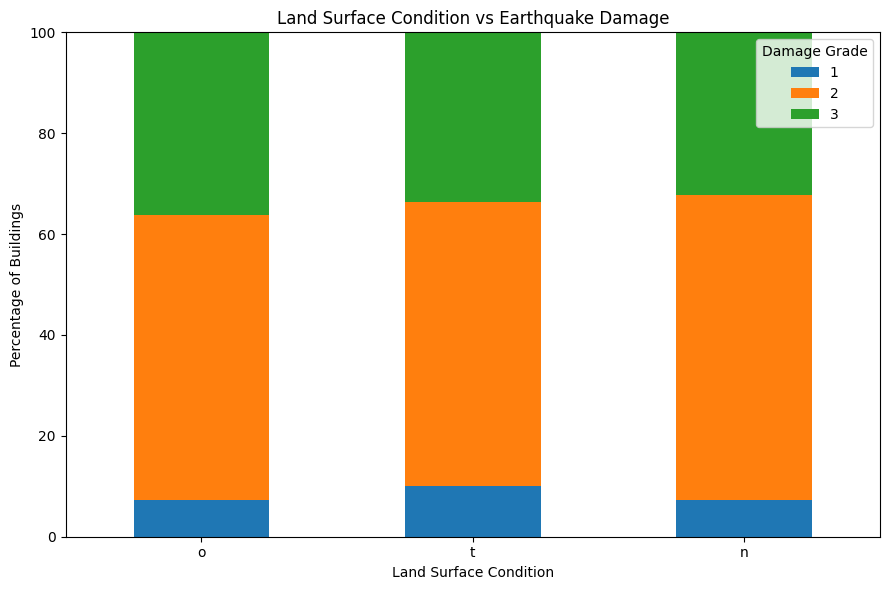

In [24]:

# Analyze land surface condition vs damage grade

# Count buildings in each land surface category
land_counts = df["land_surface_condition"].value_counts()

# Calculate damage grade percentages
land_damage = pd.crosstab(
    df["land_surface_condition"],
    df["damage_grade"],
    normalize="index"
) * 100

# Create the summary table
land_summary = land_damage.round(2).copy()

land_summary.insert(
    0,
    "Building Count",
    land_counts.reindex(land_summary.index)
)

# Sort by Grade 3 damage percentage
land_summary = land_summary.sort_values(
    by=3,
    ascending=False
)

print("LAND SURFACE CONDITION VS DAMAGE GRADE")
print("=" * 60)

display(land_summary)

# Visualize damage distribution
ax = land_summary[[1, 2, 3]].plot(
    kind="bar",
    stacked=True,
    figsize=(9, 6)
)

ax.set_title(
    "Land Surface Condition vs Earthquake Damage"
)
ax.set_xlabel("Land Surface Condition")
ax.set_ylabel("Percentage of Buildings")

ax.set_ylim(0, 100)
ax.legend(title="Damage Grade")
ax.tick_params(axis="x", rotation=0)

plt.tight_layout()
plt.show()


BUILDING AREA VS DAMAGE GRADE


,Building_Count,Mean,Median,Minimum,Maximum,Q1,Q3
damage_grade,,,,,,,
1,25124,9.72,8.0,1,96,6.0,12.0
2,148259,8.03,7.0,1,100,6.0,9.0
3,87218,7.50,7.0,1,96,5.0,9.0


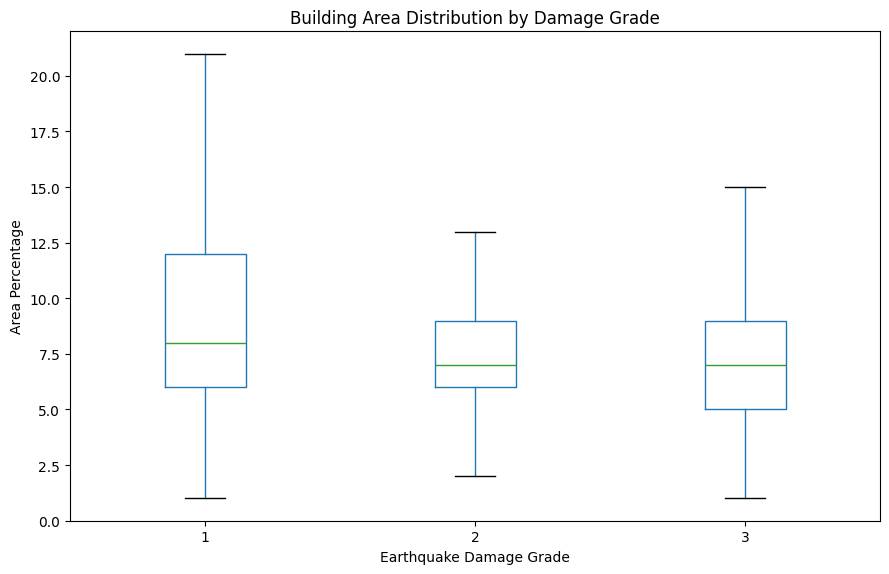

In [25]:

# Analyze building area vs earthquake damage

# Step 1: Calculate area statistics for each damage grade
area_summary = df.groupby(
    "damage_grade"
)["area_percentage"].agg(
    Building_Count="count",
    Mean="mean",
    Median="median",
    Minimum="min",
    Maximum="max"
)

# Step 2: Calculate the first and third quartiles
area_summary["Q1"] = df.groupby(
    "damage_grade"
)["area_percentage"].quantile(0.25)

area_summary["Q3"] = df.groupby(
    "damage_grade"
)["area_percentage"].quantile(0.75)

# Step 3: Display the statistics
print("BUILDING AREA VS DAMAGE GRADE")
print("=" * 60)

display(area_summary.round(2))

# Step 4: Create box plots
ax = df.boxplot(
    column="area_percentage",
    by="damage_grade",
    figsize=(9, 6),
    showfliers=False,
    grid=False
)

# Step 5: Customize the visualization
ax.set_title("Building Area Distribution by Damage Grade")
ax.set_xlabel("Earthquake Damage Grade")
ax.set_ylabel("Area Percentage")

plt.suptitle("")
plt.tight_layout()
plt.show()


BUILDING HEIGHT VS DAMAGE GRADE


,Building_Count,Mean,Median,Minimum,Maximum,Q1,Q3
damage_grade,,,,,,,
1,25124,5.15,5.0,2,24,3.0,6.0
2,148259,5.43,5.0,2,32,4.0,6.0
3,87218,5.52,5.0,2,32,5.0,7.0


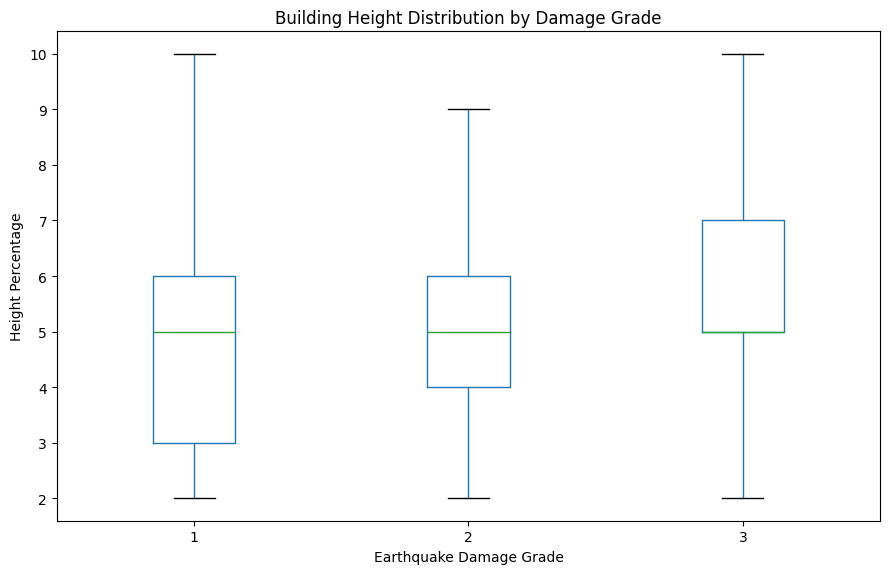

In [26]:

# Analyze building height vs earthquake damage

# Step 1: Calculate height statistics for each damage grade
height_summary = df.groupby(
    "damage_grade"
)["height_percentage"].agg(
    Building_Count="count",
    Mean="mean",
    Median="median",
    Minimum="min",
    Maximum="max",
    Q1=lambda x: x.quantile(0.25),
    Q3=lambda x: x.quantile(0.75)
)

# Step 2: Display the summary table
print("BUILDING HEIGHT VS DAMAGE GRADE")
print("=" * 60)

display(height_summary.round(2))

# Step 3: Create the box plot
fig, ax = plt.subplots(figsize=(9, 6))

df.boxplot(
    column="height_percentage",
    by="damage_grade",
    ax=ax,
    showfliers=False,
    grid=False
)

# Step 4: Customize the chart
ax.set_title(
    "Building Height Distribution by Damage Grade"
)
ax.set_xlabel("Earthquake Damage Grade")
ax.set_ylabel("Height Percentage")

fig.suptitle("")
plt.tight_layout()
plt.show()


BUILDING HEIGHT VS DAMAGE GRADE


,Building_Count,Mean,Median,Minimum,Maximum,Q1,Q3
damage_grade,,,,,,,
1,25124,5.15,5.0,2,24,3.0,6.0
2,148259,5.43,5.0,2,32,4.0,6.0
3,87218,5.52,5.0,2,32,5.0,7.0


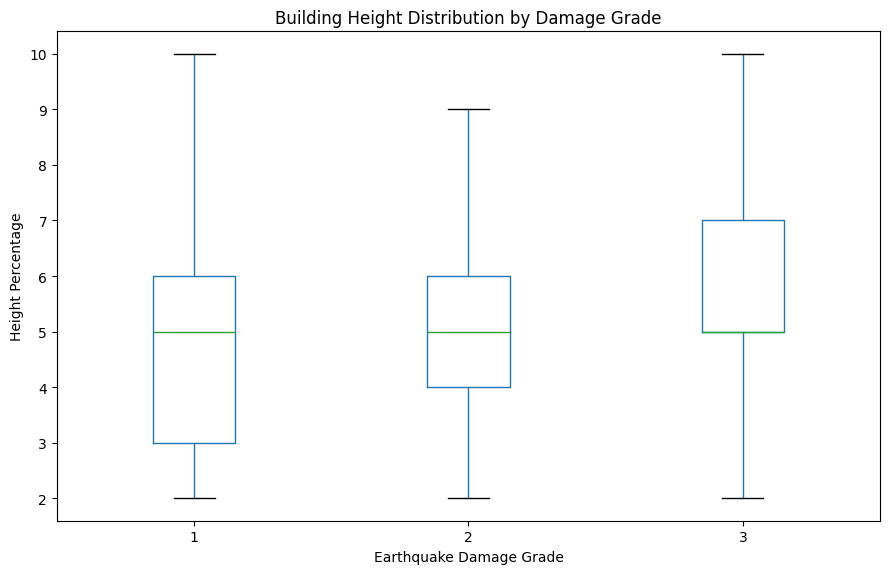

In [28]:

# Analyze building height vs earthquake damage

# Step 1: Calculate height statistics for each damage grade
height_summary = df.groupby(
    "damage_grade"
)["height_percentage"].agg(
    Building_Count="count",
    Mean="mean",
    Median="median",
    Minimum="min",
    Maximum="max",
    Q1=lambda x: x.quantile(0.25),
    Q3=lambda x: x.quantile(0.75)
)

# Step 2: Display the summary table
print("BUILDING HEIGHT VS DAMAGE GRADE")
print("=" * 60)

display(height_summary.round(2))

# Step 3: Create the box plot
fig, ax = plt.subplots(figsize=(9, 6))

df.boxplot(
    column="height_percentage",
    by="damage_grade",
    ax=ax,
    showfliers=False,
    grid=False
)

# Step 4: Customize the chart
ax.set_title(
    "Building Height Distribution by Damage Grade"
)
ax.set_xlabel("Earthquake Damage Grade")
ax.set_ylabel("Height Percentage")

fig.suptitle("")
plt.tight_layout()
plt.show()


GROUND FLOOR TYPE VS DAMAGE GRADE


damage_grade,Building Count,Grade 1 (%),Grade 2 (%),Grade 3 (%)
ground_floor_type,,,,
f,209619,5.95,57.19,36.86
x,24877,8.25,58.43,33.32
z,1004,19.82,52.99,27.19
m,508,17.72,67.52,14.76
v,24593,41.92,52.74,5.34


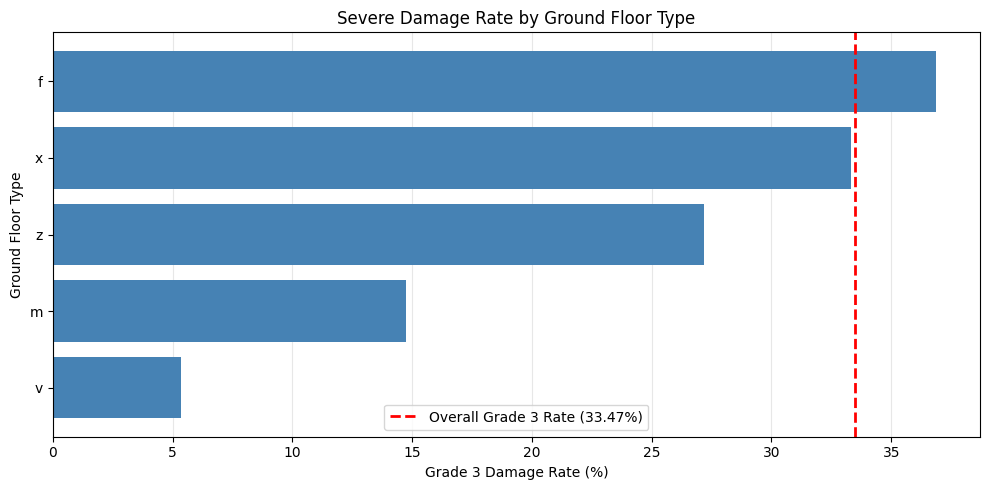

In [29]:

# Analyze ground floor type vs earthquake damage

# Step 1: Count buildings in each category
ground_floor_counts = (
    df["ground_floor_type"].value_counts()
)

# Step 2: Calculate damage grade percentages
ground_floor_damage = pd.crosstab(
    df["ground_floor_type"],
    df["damage_grade"],
    normalize="index"
) * 100

# Step 3: Create the summary table
ground_floor_summary = ground_floor_damage.rename(
    columns={
        1: "Grade 1 (%)",
        2: "Grade 2 (%)",
        3: "Grade 3 (%)"
    }
).round(2).copy()

# Step 4: Add the building counts
ground_floor_summary.insert(
    0,
    "Building Count",
    ground_floor_counts.reindex(
        ground_floor_summary.index
    )
)

# Step 5: Sort by Grade 3 damage rate
ground_floor_summary = ground_floor_summary.sort_values(
    "Grade 3 (%)",
    ascending=False
)

print("GROUND FLOOR TYPE VS DAMAGE GRADE")
print("=" * 60)

display(ground_floor_summary)

# Step 6: Calculate overall Grade 3 damage rate
overall_grade3 = df["damage_grade"].eq(3).mean() * 100

# Step 7: Create a horizontal bar chart
plot_data = ground_floor_summary.sort_values(
    "Grade 3 (%)"
)

fig, ax = plt.subplots(figsize=(10, 5))

ax.barh(
    plot_data.index.astype(str),
    plot_data["Grade 3 (%)"],
    color="steelblue"
)

# Step 8: Add the overall rate as a reference line
ax.axvline(
    overall_grade3,
    color="red",
    linestyle="--",
    linewidth=2,
    label=f"Overall Grade 3 Rate ({overall_grade3:.2f}%)"
)

# Step 9: Customize the chart
ax.set_title("Severe Damage Rate by Ground Floor Type")
ax.set_xlabel("Grade 3 Damage Rate (%)")
ax.set_ylabel("Ground Floor Type")

ax.legend()
ax.grid(axis="x", alpha=0.3)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()


OTHER FLOOR TYPE VS DAMAGE GRADE


damage_grade,Building Count,Grade 1 (%),Grade 2 (%),Grade 3 (%)
other_floor_type,,,,
x,43448,7.89,54.49,37.62
q,165282,4.47,59.49,36.04
j,39843,22.30,51.11,26.59
s,12028,45.09,49.09,5.83


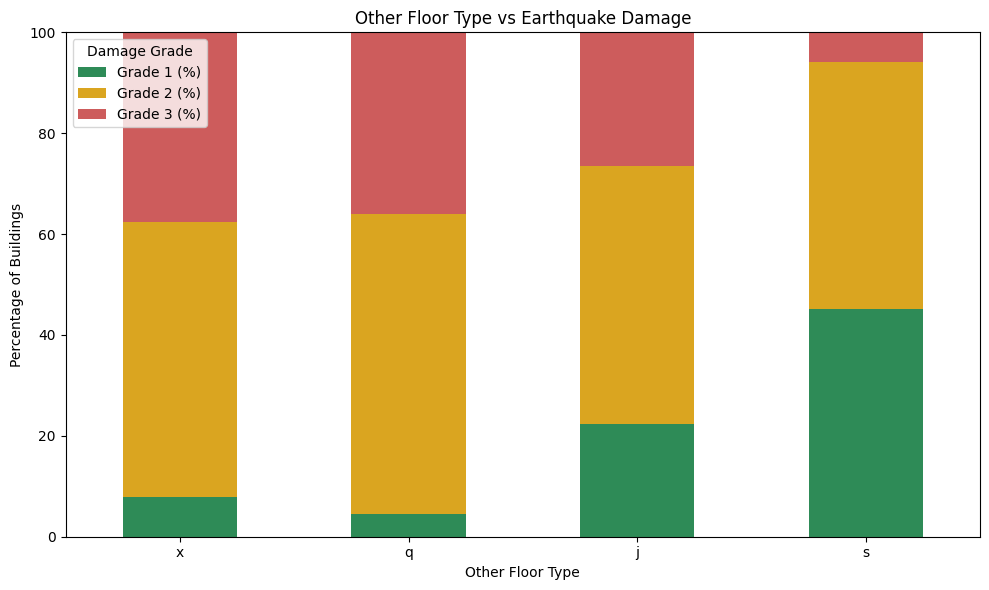

In [30]:

# Analyze other floor type vs earthquake damage

# Step 1: Count buildings in each category
other_floor_counts = (
    df["other_floor_type"].value_counts()
)

# Step 2: Calculate damage percentages
other_floor_damage = pd.crosstab(
    df["other_floor_type"],
    df["damage_grade"],
    normalize="index"
) * 100

# Step 3: Create the summary table
other_floor_summary = other_floor_damage.rename(
    columns={
        1: "Grade 1 (%)",
        2: "Grade 2 (%)",
        3: "Grade 3 (%)"
    }
).round(2).copy()

# Step 4: Include building counts
other_floor_summary.insert(
    0,
    "Building Count",
    other_floor_counts.reindex(
        other_floor_summary.index
    )
)

# Step 5: Sort by severe damage rate
other_floor_summary = other_floor_summary.sort_values(
    "Grade 3 (%)",
    ascending=False
)

print("OTHER FLOOR TYPE VS DAMAGE GRADE")
print("=" * 60)

display(other_floor_summary)

# Step 6: Visualize damage distribution
ax = other_floor_summary[
    ["Grade 1 (%)", "Grade 2 (%)", "Grade 3 (%)"]
].plot(
    kind="bar",
    stacked=True,
    figsize=(10, 6),
    color=["seagreen", "goldenrod", "indianred"]
)

ax.set_title("Other Floor Type vs Earthquake Damage")
ax.set_xlabel("Other Floor Type")
ax.set_ylabel("Percentage of Buildings")

ax.set_ylim(0, 100)
ax.legend(title="Damage Grade")
ax.tick_params(axis="x", rotation=0)

plt.tight_layout()
plt.show()


BUILDING POSITION VS DAMAGE GRADE


damage_grade,Building Count,Grade 1 (%),Grade 2 (%),Grade 3 (%),Difference from Overall (pp)
position,,,,,
t,42896,8.07,52.92,39.01,5.54
s,202090,9.83,57.43,32.74,-0.73
j,13282,12.61,59.47,27.92,-5.55
o,2333,5.14,68.97,25.89,-7.58


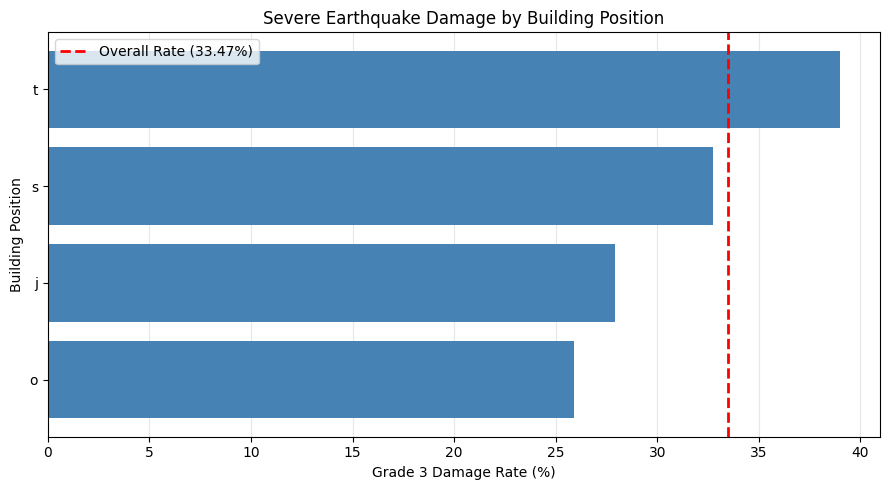

In [31]:

# Analyze building position vs earthquake damage

# Step 1: Count buildings in each position
position_counts = df["position"].value_counts()

# Step 2: Calculate damage-grade percentages
position_damage = pd.crosstab(
    df["position"],
    df["damage_grade"],
    normalize="index"
) * 100

# Step 3: Create a readable summary table
position_summary = position_damage.rename(
    columns={
        1: "Grade 1 (%)",
        2: "Grade 2 (%)",
        3: "Grade 3 (%)"
    }
).round(2).copy()

# Step 4: Add building counts
position_summary.insert(
    0,
    "Building Count",
    position_counts.reindex(position_summary.index)
)

# Step 5: Calculate overall severe-damage rate
overall_grade3_rate = (
    df["damage_grade"].eq(3).mean() * 100
)

# Step 6: Compare each position with the overall rate
position_summary["Difference from Overall (pp)"] = (
    position_summary["Grade 3 (%)"] - overall_grade3_rate
).round(2)

# Step 7: Sort by Grade 3 percentage
position_summary = position_summary.sort_values(
    "Grade 3 (%)",
    ascending=False
)

print("BUILDING POSITION VS DAMAGE GRADE")
print("=" * 60)

display(position_summary)

# Step 8: Visualize Grade 3 damage rates
plot_data = position_summary.sort_values("Grade 3 (%)")

fig, ax = plt.subplots(figsize=(9, 5))

ax.barh(
    plot_data.index.astype(str),
    plot_data["Grade 3 (%)"],
    color="steelblue"
)

# Add overall dataset reference line
ax.axvline(
    overall_grade3_rate,
    color="red",
    linestyle="--",
    linewidth=2,
    label=f"Overall Rate ({overall_grade3_rate:.2f}%)"
)

# Step 9: Customize the chart
ax.set_title("Severe Earthquake Damage by Building Position")
ax.set_xlabel("Grade 3 Damage Rate (%)")
ax.set_ylabel("Building Position")

ax.legend()
ax.grid(axis="x", alpha=0.3)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()


PLAN CONFIGURATION VS DAMAGE GRADE


damage_grade,Building Count,Grade 1 (%),Grade 2 (%),Grade 3 (%),Difference from Overall (pp)
plan_configuration,,,,,
q,5692,13.72,45.41,40.86,7.39
d,250072,9.32,56.99,33.69,0.22
n,38,15.79,52.63,31.58,-1.89
f,22,0.00,72.73,27.27,-6.20
s,346,15.32,64.45,20.23,-13.24
o,159,25.16,60.38,14.47,-19.00
u,3649,21.21,65.74,13.04,-20.43
a,252,26.19,62.30,11.51,-21.96
c,325,26.46,63.38,10.15,-23.32


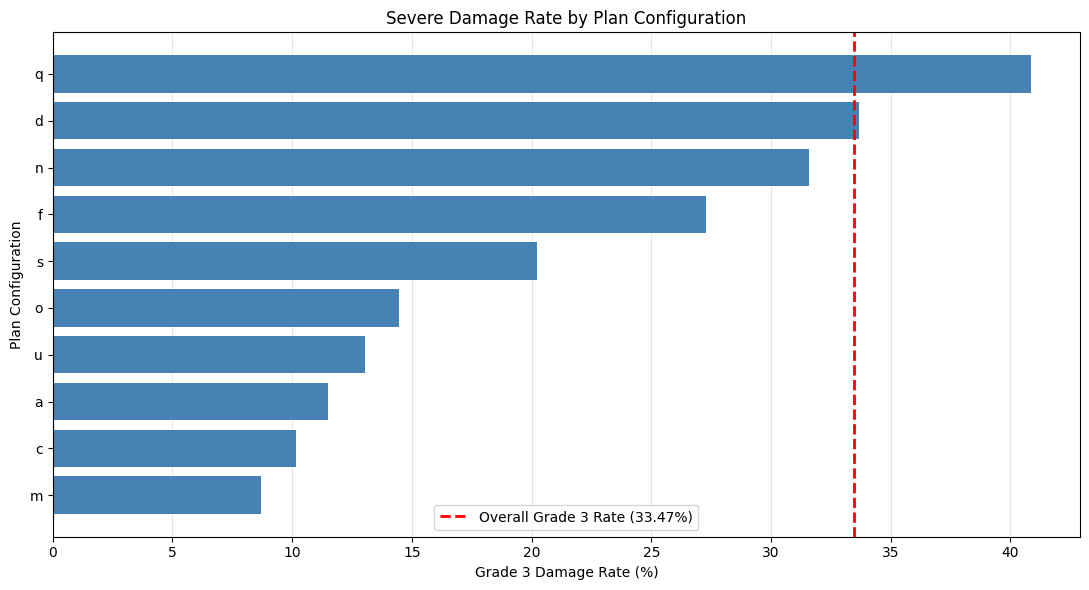

In [32]:

# Analyze plan configuration vs earthquake damage

# Step 1: Count buildings in each plan configuration
plan_counts = df["plan_configuration"].value_counts()

# Step 2: Calculate damage-grade percentages
plan_damage = pd.crosstab(
    df["plan_configuration"],
    df["damage_grade"],
    normalize="index"
) * 100

# Step 3: Create a readable summary table
plan_summary = plan_damage.rename(
    columns={
        1: "Grade 1 (%)",
        2: "Grade 2 (%)",
        3: "Grade 3 (%)"
    }
).round(2).copy()

# Step 4: Add building counts
plan_summary.insert(
    0,
    "Building Count",
    plan_counts.reindex(plan_summary.index)
)

# Step 5: Compare with overall Grade 3 rate
overall_grade3_rate = df["damage_grade"].eq(3).mean() * 100

plan_summary["Difference from Overall (pp)"] = (
    plan_summary["Grade 3 (%)"] - overall_grade3_rate
).round(2)

# Step 6: Sort by severe-damage percentage
plan_summary = plan_summary.sort_values(
    "Grade 3 (%)",
    ascending=False
)

print("PLAN CONFIGURATION VS DAMAGE GRADE")
print("=" * 60)

display(plan_summary)

# Step 7: Visualize Grade 3 damage rates
plot_data = plan_summary.sort_values("Grade 3 (%)")

fig, ax = plt.subplots(figsize=(11, 6))

ax.barh(
    plot_data.index.astype(str),
    plot_data["Grade 3 (%)"],
    color="steelblue"
)

# Step 8: Add overall Grade 3 reference line
ax.axvline(
    overall_grade3_rate,
    color="red",
    linestyle="--",
    linewidth=2,
    label=f"Overall Grade 3 Rate ({overall_grade3_rate:.2f}%)"
)

# Step 9: Customize the chart
ax.set_title("Severe Damage Rate by Plan Configuration")
ax.set_xlabel("Grade 3 Damage Rate (%)")
ax.set_ylabel("Plan Configuration")

ax.legend()
ax.grid(axis="x", alpha=0.3)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()


LEGAL OWNERSHIP STATUS VS DAMAGE GRADE


damage_grade,Building Count,Grade 1 (%),Grade 2 (%),Grade 3 (%),Difference from Overall (pp)
legal_ownership_status,,,,,
w,2677,4.86,48.71,46.43,12.96
r,1473,14.46,49.36,36.18,2.72
v,250939,9.27,57.05,33.68,0.21
a,5512,27.41,55.77,16.82,-16.65


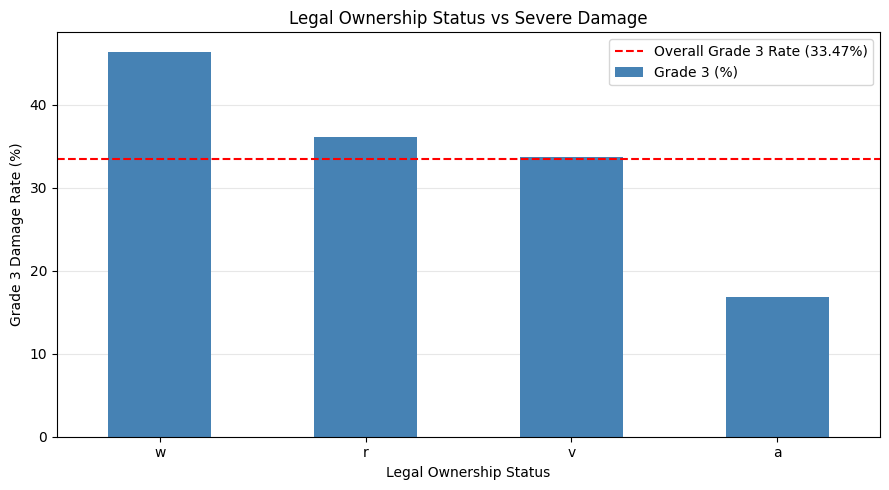

In [33]:

# Define a reusable function for categorical EDA

def damage_by_category(data, feature):

    # Count buildings in each category
    counts = data[feature].value_counts()

    # Calculate damage-grade percentages
    rates = pd.crosstab(
        data[feature],
        data["damage_grade"],
        normalize="index"
    ) * 100

    # Rename columns for readability
    summary = rates.rename(
        columns={
            1: "Grade 1 (%)",
            2: "Grade 2 (%)",
            3: "Grade 3 (%)"
        }
    ).copy()

    # Add building counts
    summary.insert(
        0,
        "Building Count",
        counts.reindex(summary.index)
    )

    # Calculate overall severe damage rate
    overall_rate = (
        data["damage_grade"].eq(3).mean() * 100
    )

    # Calculate difference from overall rate
    summary["Difference from Overall (pp)"] = (
        summary["Grade 3 (%)"] - overall_rate
    )

    # Return sorted and rounded results
    return summary.sort_values(
        "Grade 3 (%)",
        ascending=False
    ).round(2)


# Apply the function to legal ownership status
ownership_summary = damage_by_category(
    df,
    "legal_ownership_status"
)

print("LEGAL OWNERSHIP STATUS VS DAMAGE GRADE")
print("=" * 60)

display(ownership_summary)


# Visualize severe damage rates
ax = ownership_summary["Grade 3 (%)"].plot(
    kind="bar",
    figsize=(9, 5),
    color="steelblue"
)

# Add overall Grade 3 reference line
overall_rate = df["damage_grade"].eq(3).mean() * 100

ax.axhline(
    overall_rate,
    color="red",
    linestyle="--",
    label=f"Overall Grade 3 Rate ({overall_rate:.2f}%)"
)

ax.set_title("Legal Ownership Status vs Severe Damage")
ax.set_xlabel("Legal Ownership Status")
ax.set_ylabel("Grade 3 Damage Rate (%)")
ax.tick_params(axis="x", rotation=0)

ax.legend()
ax.grid(axis="y", alpha=0.3)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()


ORIGINAL FAMILY COUNT DISTRIBUTION


count_families
0     20862
1    226115
2     11294
3      1802
4       389
5       104
6        22
7         7
8         2
9         4
Name: count, dtype: int64


FAMILY COUNT VS DAMAGE GRADE


damage_grade,Building Count,1,2,3
count_families,,,,
0,20862,17.56,54.46,27.98
1,226115,8.99,57.37,33.64
2,11294,7.34,53.31,39.35
3+,2330,12.58,49.61,37.81


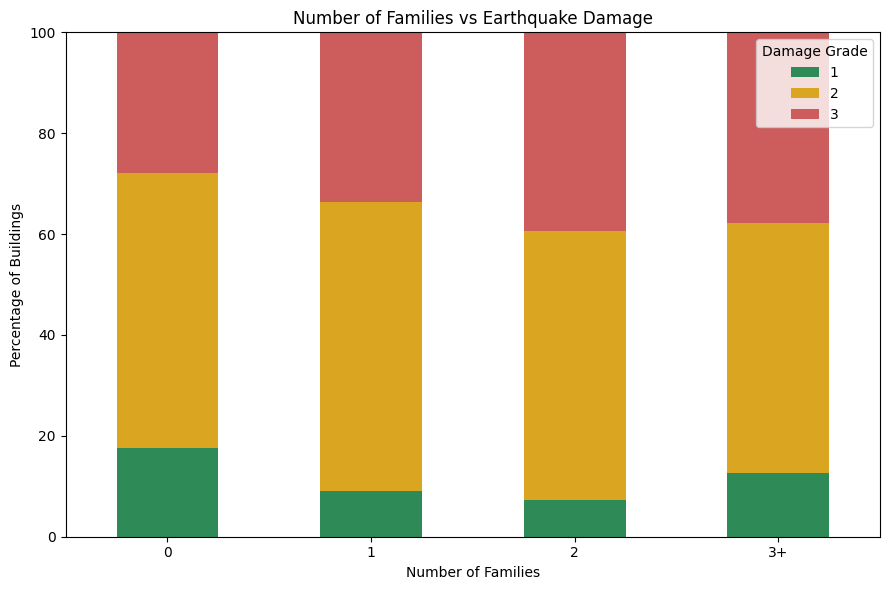

In [34]:

# Analyze number of families vs earthquake damage

# Step 1: Examine the original family counts
family_counts = (
    df["count_families"]
    .value_counts()
    .sort_index()
)

print("ORIGINAL FAMILY COUNT DISTRIBUTION")
print("=" * 60)
display(family_counts)


# Step 2: Create family-count groups for EDA
family_groups = pd.cut(
    df["count_families"],
    bins=[-1, 0, 1, 2, np.inf],
    labels=["0", "1", "2", "3+"]
)

# Step 3: Count buildings in each group
group_counts = family_groups.value_counts(sort=False)

# Step 4: Calculate damage percentages
family_damage = pd.crosstab(
    family_groups,
    df["damage_grade"],
    normalize="index"
) * 100

# Step 5: Create a summary table
family_summary = family_damage.round(2).copy()

family_summary.insert(
    0,
    "Building Count",
    group_counts.reindex(family_summary.index)
)

print("\nFAMILY COUNT VS DAMAGE GRADE")
print("=" * 60)
display(family_summary)


# Step 6: Visualize damage distributions
ax = family_damage.plot(
    kind="bar",
    stacked=True,
    figsize=(9, 6),
    color=["seagreen", "goldenrod", "indianred"]
)

ax.set_title("Number of Families vs Earthquake Damage")
ax.set_xlabel("Number of Families")
ax.set_ylabel("Percentage of Buildings")

ax.set_ylim(0, 100)
ax.legend(title="Damage Grade")
ax.tick_params(axis="x", rotation=0)

plt.tight_layout()
plt.show()


SECONDARY USE VS DAMAGE GRADE


damage_grade,Building Count,Grade 1 (%),Grade 2 (%),Grade 3 (%),Difference from Overall (pp)
has_secondary_use,,,,,
0,231445,9.02,56.40,34.58,1.11
1,29156,14.57,60.76,24.67,-8.80



DAMAGE RATES BY SECONDARY-USE CATEGORY


,Secondary Use,Building Count,Grade 3 (%)
0,agriculture,16777,31.41
1,hotel,8763,16.99
2,rental,2111,8.67
9,other,1334,23.01
5,industry,279,24.37
3,institution,245,6.94
4,school,94,18.09
6,health_post,49,10.20
7,gov_office,38,10.53
8,use_police,23,30.43


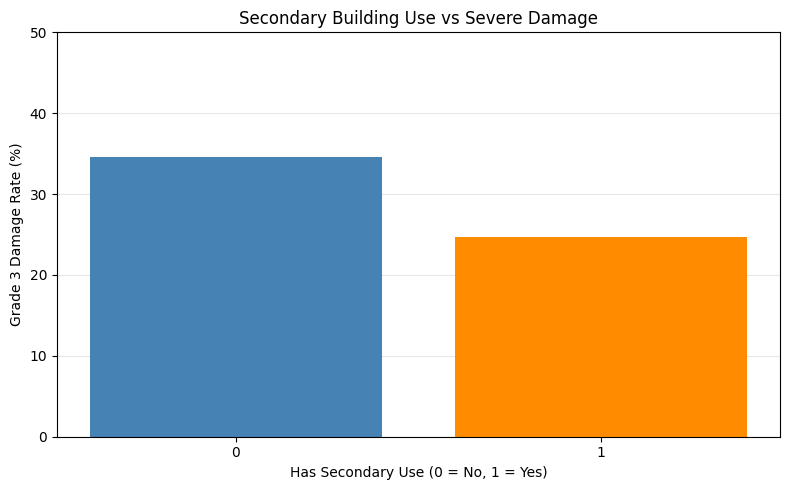

In [35]:

# Analyze secondary building use vs earthquake damage

# Step 1: Compare buildings with and without secondary use
secondary_summary = damage_by_category(
    df,
    "has_secondary_use"
)

print("SECONDARY USE VS DAMAGE GRADE")
print("=" * 60)

display(secondary_summary)


# Step 2: Select specific secondary-use indicators
secondary_features = [
    col for col in df.columns
    if col.startswith("has_secondary_use_")
]

# Step 3: Analyze each secondary-use category
secondary_results = []

for feature in secondary_features:

    # Select buildings with this secondary use
    selected = df[feature] == 1

    # Count buildings
    building_count = selected.sum()

    # Calculate Grade 3 percentage
    severe_rate = (
        df.loc[selected, "damage_grade"]
        .eq(3).mean() * 100
        if building_count > 0 else np.nan
    )

    secondary_results.append({
        "Secondary Use": feature.replace(
            "has_secondary_use_", ""
        ),
        "Building Count": building_count,
        "Grade 3 (%)": severe_rate
    })

# Step 4: Create a summary table
secondary_type_summary = pd.DataFrame(
    secondary_results
).sort_values(
    "Building Count",
    ascending=False
)

print("\nDAMAGE RATES BY SECONDARY-USE CATEGORY")
print("=" * 60)

display(secondary_type_summary.round(2))


# Step 5: Visualize the overall secondary-use comparison
fig, ax = plt.subplots(figsize=(8, 5))

ax.bar(
    secondary_summary.index.astype(str),
    secondary_summary["Grade 3 (%)"],
    color=["steelblue", "darkorange"]
)

ax.set_title("Secondary Building Use vs Severe Damage")
ax.set_xlabel("Has Secondary Use (0 = No, 1 = Yes)")
ax.set_ylabel("Grade 3 Damage Rate (%)")

ax.set_ylim(0, 50)

ax.grid(axis="y", alpha=0.3)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()


NUMERICAL FEATURE CORRELATION MATRIX


,count_floors_pre_eq,age,area_percentage,height_percentage,count_families
count_floors_pre_eq,1.00,0.26,0.13,0.76,0.08
age,0.26,1.00,-0.02,0.20,0.05
area_percentage,0.13,-0.02,1.00,0.21,0.08
height_percentage,0.76,0.20,0.21,1.00,0.06
count_families,0.08,0.05,0.08,0.06,1.00


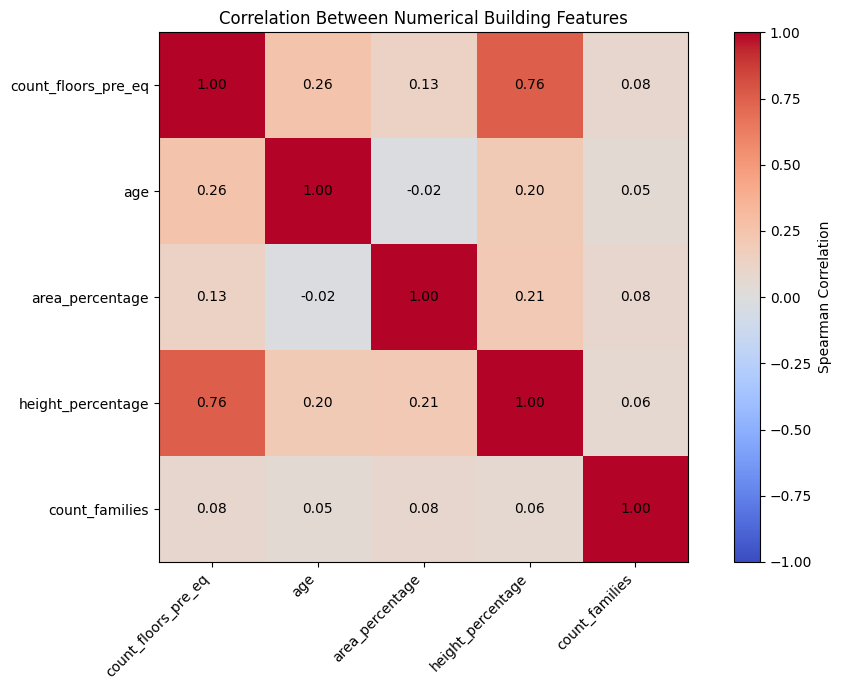

In [36]:

# Analyze correlations between numerical building features

# Step 1: Select meaningful numerical measurements
numeric_features = [
    "count_floors_pre_eq",
    "age",
    "area_percentage",
    "height_percentage",
    "count_families"
]

# Step 2: Calculate Spearman correlations
correlation_matrix = df[numeric_features].corr(
    method="spearman"
)

print("NUMERICAL FEATURE CORRELATION MATRIX")
print("=" * 60)

display(correlation_matrix.round(2))

# Step 3: Create the heatmap
fig, ax = plt.subplots(figsize=(10, 7))

heatmap = ax.imshow(
    correlation_matrix,
    cmap="coolwarm",
    vmin=-1,
    vmax=1
)

# Step 4: Set feature labels
ax.set_xticks(range(len(numeric_features)))
ax.set_yticks(range(len(numeric_features)))

ax.set_xticklabels(numeric_features, rotation=45, ha="right")
ax.set_yticklabels(numeric_features)

# Step 5: Display correlation values in each cell
for i in range(len(numeric_features)):
    for j in range(len(numeric_features)):
        value = correlation_matrix.iloc[i, j]

        ax.text(
            j, i,
            f"{value:.2f}",
            ha="center",
            va="center",
            fontsize=10
        )

# Step 6: Add color scale and title
fig.colorbar(
    heatmap,
    ax=ax,
    label="Spearman Correlation"
)

ax.set_title("Correlation Between Numerical Building Features")

plt.tight_layout()
plt.show()


In [37]:

# Check consistency of secondary-use indicators

# Step 1: Select specific secondary-use columns
specific_secondary_cols = [
    col for col in df.columns
    if col.startswith("has_secondary_use_")
]

# Step 2: Count enabled secondary-use indicators per building
specific_use_count = df[
    specific_secondary_cols
].sum(axis=1)

# Step 3: Display the distribution
print("NUMBER OF SECONDARY-USE TYPES PER BUILDING")
print("=" * 60)

display(
    specific_use_count
    .value_counts()
    .sort_index()
    .rename_axis("Number of Specific Uses")
    .to_frame("Building Count")
)

# Step 4: Check buildings with multiple secondary uses
multiple_uses = (specific_use_count > 1).sum()

# Step 5: Check flag consistency
flag_yes_but_none = (
    (df["has_secondary_use"] == 1) &
    (specific_use_count == 0)
).sum()

flag_no_but_some = (
    (df["has_secondary_use"] == 0) &
    (specific_use_count > 0)
).sum()

# Step 6: Display findings
print("\nSECONDARY-USE CONSISTENCY CHECK")
print("=" * 60)

print(
    "Buildings with multiple specific secondary uses:",
    multiple_uses
)

print(
    "Overall flag = 1, but no specific use:",
    flag_yes_but_none
)

print(
    "Overall flag = 0, but specific use exists:",
    flag_no_but_some
)

print(
    "Total enabled specific-use indicators:",
    int(specific_use_count.sum())
)

print(
    "Buildings with at least one specific use:",
    int((specific_use_count > 0).sum())
)


NUMBER OF SECONDARY-USE TYPES PER BUILDING


,Building Count
Number of Specific Uses,
0,231445
1,28599
2,557



SECONDARY-USE CONSISTENCY CHECK
Buildings with multiple specific secondary uses: 557
Overall flag = 1, but no specific use: 0
Overall flag = 0, but specific use exists: 0
Total enabled specific-use indicators: 29713
Buildings with at least one specific use: 29156



## Exploratory Data Analysis — Key Findings

### 1. Target Variable
The dataset contains 260,601 buildings with three damage grades:
- Grade 1 (Low): 9.64%
- Grade 2 (Medium): 56.89%
- Grade 3 (Severe): 33.47%

The target is imbalanced, so model evaluation should include
macro F1-score, class-wise precision, recall, and confusion matrices.

### 2. Building Age
Damage distributions differ across building age groups.
Buildings aged 45–60 show a Grade 3 rate of 39.26%,
compared with 32.13% for buildings aged 5–20.

The unusual recorded age of 995 requires further investigation
during preprocessing.

### 3. Construction Materials
Material indicators show substantial differences in observed damage.
Buildings with mud-mortar stone have a Grade 3 rate of 38.20%,
while those with engineered reinforced concrete have a rate
of 1.81%.

These associations do not prove causal effects.

### 4. Structural Features
Foundation type, roof type, ground-floor type, and other-floor
type show considerable differences in damage distribution.

Among well-represented floor-count groups, three-storey
buildings have the highest Grade 3 rate at 44.23%.

### 5. Geographic Location
Damage varies substantially across geographic regions.
Geo Level 1 Region 17 has a Grade 3 rate of 80.75%,
compared with 8.59% for Region 26.

Geographic generalization should be considered during
model validation.

### 6. Numerical Features
Area and height distributions overlap across damage grades.

The Spearman correlation between floor count and recorded
height percentage is 0.76, indicating a strong positive
monotonic relationship.

### 7. Additional Categorical Features
Land surface condition, building position, plan configuration,
legal ownership, family count, and secondary-use indicators
show varying associations with damage severity.

Some categories are rare and require careful interpretation.

### 8. Data Quality
- No missing values were found in the original input files.
- Building IDs were unique and matched across both files.
- All 260,601 buildings were retained after merging.
- Secondary-use indicators are consistent.
- Exactly 557 buildings have two specific secondary uses.
- Some numerical values and rare categories need special attention.

### 9. Conclusion
Geographic and structural features appear promising for
predicting earthquake damage.

The observed relationships are descriptive associations,
not evidence of causation.

The next phase will prepare the data for machine learning
using a leakage-safe train-validation split, categorical
encoding, and appropriate preprocessing pipelines.


In [38]:

# Phase 4: Data Preprocessing
# Cell 36 - Train-Validation Split

from sklearn.model_selection import train_test_split

# Step 1: Separate input features and target
X = df.drop(columns=["building_id", "damage_grade"])
y = df["damage_grade"]

# Step 2: Split data into training and validation sets
X_train, X_val, y_train, y_val = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Step 3: Check dataset shapes
print("DATASET SPLIT SUMMARY")
print("=" * 60)

print("Original feature shape:", X.shape)
print("Original target shape:", y.shape)

print("\nTraining feature shape:", X_train.shape)
print("Validation feature shape:", X_val.shape)

print("\nTraining target shape:", y_train.shape)
print("Validation target shape:", y_val.shape)

# Step 4: Compare target distributions
distribution_check = pd.DataFrame({
    "Original (%)": y.value_counts(normalize=True) * 100,
    "Training (%)": y_train.value_counts(normalize=True) * 100,
    "Validation (%)": y_val.value_counts(normalize=True) * 100
}).sort_index()

print("\nDAMAGE GRADE DISTRIBUTION AFTER SPLITTING")
print("=" * 60)

display(distribution_check.round(2))

# Step 5: Confirm there is no row overlap
overlap = X_train.index.intersection(X_val.index)

print("\nOverlapping rows:", len(overlap))


DATASET SPLIT SUMMARY
Original feature shape: (260601, 38)
Original target shape: (260601,)

Training feature shape: (208480, 38)
Validation feature shape: (52121, 38)

Training target shape: (208480,)
Validation target shape: (52121,)

DAMAGE GRADE DISTRIBUTION AFTER SPLITTING


,Original (%),Training (%),Validation (%)
damage_grade,,,
1,9.64,9.64,9.64
2,56.89,56.89,56.89
3,33.47,33.47,33.47



Overlapping rows: 0


In [39]:

# Cell 37 - Identify feature types for preprocessing

# Step 1: Numerical measurements
numerical_features = [
    "count_floors_pre_eq",
    "age",
    "area_percentage",
    "height_percentage",
    "count_families"
]

# Step 2: Categorical text features
categorical_features = [
    "land_surface_condition",
    "foundation_type",
    "roof_type",
    "ground_floor_type",
    "other_floor_type",
    "position",
    "plan_configuration",
    "legal_ownership_status"
]

# Step 3: Geographic identifiers
geographic_features = [
    "geo_level_1_id",
    "geo_level_2_id",
    "geo_level_3_id"
]

# Step 4: Binary indicator features
binary_features = [
    col for col in X_train.columns
    if col.startswith(
        ("has_superstructure_", "has_secondary_use")
    )
]

# Step 5: Combine all feature groups
all_grouped_features = (
    numerical_features
    + categorical_features
    + geographic_features
    + binary_features
)

# Step 6: Check for missing or duplicated assignments
missing_features = set(X_train.columns) - set(
    all_grouped_features
)

unexpected_features = set(all_grouped_features) - set(
    X_train.columns
)

duplicate_count = (
    len(all_grouped_features)
    - len(set(all_grouped_features))
)

# Step 7: Display feature group summary
feature_group_summary = pd.DataFrame({
    "Feature Type": [
        "Numerical",
        "Categorical Text",
        "Geographic",
        "Binary"
    ],
    "Number of Features": [
        len(numerical_features),
        len(categorical_features),
        len(geographic_features),
        len(binary_features)
    ]
})

print("FEATURE TYPE SUMMARY")
print("=" * 60)

display(feature_group_summary)

print("\nTotal input features:", X_train.shape[1])
print("Total grouped features:", len(all_grouped_features))

print("\nMissing features:", missing_features)
print("Unexpected features:", unexpected_features)
print("Duplicate assignments:", duplicate_count)

# Step 8: Verify feature grouping
assert len(missing_features) == 0
assert len(unexpected_features) == 0
assert duplicate_count == 0

print("\nFeature grouping verification: PASSED")


FEATURE TYPE SUMMARY


,Feature Type,Number of Features
0,Numerical,5
1,Categorical Text,8
2,Geographic,3
3,Binary,22



Total input features: 38
Total grouped features: 38

Missing features: set()
Unexpected features: set()
Duplicate assignments: 0

Feature grouping verification: PASSED


In [40]:

# Cell 38 - Inspect categorical cardinality and rare categories

# Step 1: Combine categorical and geographic feature names
category_columns = (
    categorical_features + geographic_features
)

# Step 2: Store the analysis results
category_profiles = []

# Step 3: Analyze each categorical feature
for feature in category_columns:

    # Count each category using training data only
    counts = X_train[feature].value_counts()

    # Identify categories with fewer than 20 buildings
    rare_counts = counts[counts < 20]

    category_profiles.append({
        "Feature": feature,
        "Unique Categories": counts.size,
        "Smallest Category Count": counts.min(),
        "Largest Category (%)": round(
            counts.max() / len(X_train) * 100, 2
        ),
        "Categories with <20 Buildings": len(rare_counts),
        "Buildings in Rare Categories": rare_counts.sum()
    })

# Step 4: Convert results into a DataFrame
category_profile_df = pd.DataFrame(category_profiles)

# Step 5: Sort by number of unique categories
category_profile_df = category_profile_df.sort_values(
    "Unique Categories",
    ascending=False
)

print("CATEGORICAL FEATURE CARDINALITY ANALYSIS")
print("=" * 60)

display(category_profile_df)

# Step 6: Examine rare plan configurations
print("\nPLAN CONFIGURATION COUNTS - TRAINING DATA")
print("=" * 60)

display(
    X_train["plan_configuration"]
    .value_counts()
    .sort_values()
    .to_frame("Building Count")
)


CATEGORICAL FEATURE CARDINALITY ANALYSIS


,Feature,Unique Categories,Smallest Category Count,Largest Category (%),Categories with <20 Buildings,Buildings in Rare Categories
10,geo_level_3_id,11380,1,0.25,7679,58172
9,geo_level_2_id,1409,1,1.54,323,2744
8,geo_level_1_id,31,221,9.36,0,0
6,plan_configuration,10,16,95.95,1,16
3,ground_floor_type,5,403,80.37,0,0
1,foundation_type,5,1149,84.14,0,0
4,other_floor_type,4,9663,63.34,0,0
5,position,4,1878,77.54,0,0
7,legal_ownership_status,4,1193,96.27,0,0
2,roof_type,3,12920,70.18,0,0



PLAN CONFIGURATION COUNTS - TRAINING DATA


,Building Count
plan_configuration,
f,16
n,27
m,37
o,132
a,189
c,268
s,287
u,2920
q,4571


In [41]:

# Cell 39 - Investigate unusual numerical values
# Use training data only

# Step 1: Summarize numerical feature distributions
numeric_summary = X_train[
    numerical_features
].describe(
    percentiles=[0.01, 0.25, 0.50, 0.75, 0.99]
).T

print("TRAINING NUMERICAL FEATURE SUMMARY")
print("=" * 60)

display(numeric_summary.round(2))


# Step 2: Investigate special building age values
train_age = X_train["age"]

age_checks = {
    "Age equals 0": (train_age == 0).sum(),
    "Age 5 to 95": train_age.between(5, 95).sum(),
    "Age 100 to 994": train_age.between(100, 994).sum(),
    "Age equals 995": (train_age == 995).sum()
}

age_check_df = pd.DataFrame(
    age_checks.items(),
    columns=["Age Group", "Building Count"]
)

age_check_df["Percentage (%)"] = (
    age_check_df["Building Count"]
    / len(X_train) * 100
).round(2)

print("\nSPECIAL AGE VALUE ANALYSIS")
print("=" * 60)

display(age_check_df)


# Step 3: Check recorded age values
print("\nAGE VALUE CHECKS")
print("=" * 60)

print(
    "All ages divisible by 5:",
    bool((train_age % 5 == 0).all())
)

print(
    "Highest age below 995:",
    train_age[train_age < 995].max()
)

print(
    "Missing numerical values:",
    int(X_train[numerical_features].isna().sum().sum())
)


TRAINING NUMERICAL FEATURE SUMMARY


,count,mean,std,min,1%,25%,50%,75%,99%,max
count_floors_pre_eq,208480.0,2.13,0.73,1.0,1.0,2.0,2.0,2.0,4.0,9.0
age,208480.0,26.54,73.51,0.0,0.0,10.0,15.0,30.0,100.0,995.0
area_percentage,208480.0,8.02,4.40,1.0,2.0,5.0,7.0,9.0,24.0,100.0
height_percentage,208480.0,5.43,1.91,2.0,2.0,4.0,5.0,6.0,11.0,32.0
count_families,208480.0,0.98,0.42,0.0,0.0,1.0,1.0,1.0,2.0,9.0



SPECIAL AGE VALUE ANALYSIS


,Age Group,Building Count,Percentage (%)
0,Age equals 0,20907,10.03
1,Age 5 to 95,184771,88.63
2,Age 100 to 994,1692,0.81
3,Age equals 995,1110,0.53



AGE VALUE CHECKS
All ages divisible by 5: True
Highest age below 995: 200
Missing numerical values: 0


In [42]:

# Cell 40 - Build preprocessing pipeline

# Step 1: Import preprocessing tools
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer

# Step 2: Create numerical preprocessing pipeline
numerical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Step 3: Combine text and geographic categorical features
all_categorical_features = (
    categorical_features + geographic_features
)

# Step 4: Build the full preprocessing transformer
preprocessor = ColumnTransformer(
    transformers=[
        (
            "numerical",
            numerical_pipeline,
            numerical_features
        ),
        (
            "categorical",
            OneHotEncoder(handle_unknown="ignore"),
            all_categorical_features
        ),
        (
            "binary",
            "passthrough",
            binary_features
        )
    ],
    remainder="drop",
    sparse_threshold=1.0
)

# Step 5: Display the pipeline
print("PREPROCESSING PIPELINE CREATED")
print("=" * 60)

print("Numerical features:", len(numerical_features))
print("Categorical features:", len(all_categorical_features))
print("Binary features:", len(binary_features))

print("\nTotal input features:", X_train.shape[1])

print("\nPreprocessor fitted yet: No")

display(preprocessor)


PREPROCESSING PIPELINE CREATED
Numerical features: 5
Categorical features: 11
Binary features: 22

Total input features: 38

Preprocessor fitted yet: No


,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numerical', ...), ('categorical', ...), ...]"
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",1.0
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` a

In [43]:

# Cell 41 - Train and evaluate the first ML model

from sklearn.linear_model import SGDClassifier
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# Step 1: Create the complete ML pipeline
baseline_model = Pipeline(steps=[
    ("preprocessing", preprocessor),
    ("classifier", SGDClassifier(
        loss="log_loss",
        max_iter=1000,
        tol=1e-3,
        random_state=42
    ))
])

# Step 2: Train using training data only
baseline_model.fit(X_train, y_train)

# Step 3: Predict validation damage grades
y_val_pred = baseline_model.predict(X_val)

# Step 4: Calculate evaluation metrics
baseline_accuracy = accuracy_score(y_val, y_val_pred)

baseline_macro_f1 = f1_score(
    y_val,
    y_val_pred,
    average="macro"
)

baseline_micro_f1 = f1_score(
    y_val,
    y_val_pred,
    average="micro"
)

# Step 5: Display evaluation results
print("FIRST MODEL - SGD CLASSIFIER")
print("=" * 60)

print(f"Validation Accuracy: {baseline_accuracy:.4f}")
print(f"Validation Macro F1: {baseline_macro_f1:.4f}")
print(f"Validation Micro F1: {baseline_micro_f1:.4f}")

print("\nCLASSIFICATION REPORT")
print("=" * 60)

print(classification_report(
    y_val,
    y_val_pred,
    labels=[1, 2, 3],
    zero_division=0
))

print("\nCONFUSION MATRIX")
print("=" * 60)

cm = confusion_matrix(
    y_val,
    y_val_pred,
    labels=[1, 2, 3]
)

display(pd.DataFrame(
    cm,
    index=["Actual 1", "Actual 2", "Actual 3"],
    columns=["Predicted 1", "Predicted 2", "Predicted 3"]
))


FIRST MODEL - SGD CLASSIFIER
Validation Accuracy: 0.7277
Validation Macro F1: 0.6396
Validation Micro F1: 0.7277

CLASSIFICATION REPORT
              precision    recall  f1-score   support

           1       0.69      0.36      0.48      5025
           2       0.71      0.89      0.79     29652
           3       0.79      0.56      0.65     17444

    accuracy                           0.73     52121
   macro avg       0.73      0.60      0.64     52121
weighted avg       0.73      0.73      0.71     52121


CONFUSION MATRIX


,Predicted 1,Predicted 2,Predicted 3
Actual 1,1820,3135,70
Actual 2,758,26356,2538
Actual 3,58,7634,9752


In [44]:

# Cell 42 - Majority-class baseline comparison

# Step 1: Identify the majority training class
majority_grade = y_train.value_counts().idxmax()

# Step 2: Predict the majority class for every validation building
majority_predictions = np.full(
    len(y_val),
    majority_grade
)

# Step 3: Calculate baseline metrics
majority_accuracy = accuracy_score(
    y_val,
    majority_predictions
)

majority_macro_f1 = f1_score(
    y_val,
    majority_predictions,
    average="macro",
    labels=[1, 2, 3],
    zero_division=0
)

# Step 4: Compare both models
model_results = pd.DataFrame({
    "Model": [
        "Majority Class Baseline",
        "SGD Classifier"
    ],
    "Accuracy": [
        majority_accuracy,
        baseline_accuracy
    ],
    "Macro F1": [
        majority_macro_f1,
        baseline_macro_f1
    ]
})

print("MODEL PERFORMANCE COMPARISON")
print("=" * 60)

print("Majority training class:", majority_grade)

display(model_results.round(4))

# Step 5: Calculate improvement
accuracy_gain = (
    baseline_accuracy - majority_accuracy
) * 100

macro_f1_gain = (
    baseline_macro_f1 - majority_macro_f1
)

print("\nSGD IMPROVEMENT OVER MAJORITY BASELINE")
print("=" * 60)

print(f"Accuracy improvement: {accuracy_gain:.2f} percentage points")
print(f"Macro F1 improvement: {macro_f1_gain:.4f}")

# Step 6: Show majority-class classification report
print("\nMAJORITY-CLASS BASELINE REPORT")
print("=" * 60)

print(classification_report(
    y_val,
    majority_predictions,
    labels=[1, 2, 3],
    zero_division=0
))


MODEL PERFORMANCE COMPARISON
Majority training class: 2


,Model,Accuracy,Macro F1
0,Majority Class Baseline,0.5689,0.2417
1,SGD Classifier,0.7277,0.6396



SGD IMPROVEMENT OVER MAJORITY BASELINE
Accuracy improvement: 15.88 percentage points
Macro F1 improvement: 0.3979

MAJORITY-CLASS BASELINE REPORT
              precision    recall  f1-score   support

           1       0.00      0.00      0.00      5025
           2       0.57      1.00      0.73     29652
           3       0.00      0.00      0.00     17444

    accuracy                           0.57     52121
   macro avg       0.19      0.33      0.24     52121
weighted avg       0.32      0.57      0.41     52121



In [45]:

# Cell 43 - Random Forest Classifier

from sklearn.ensemble import RandomForestClassifier
from sklearn.base import clone

# Step 1: Create Random Forest pipeline
rf_model = Pipeline(steps=[
    ("preprocessing", clone(preprocessor)),
    ("classifier", RandomForestClassifier(
        n_estimators=60,
        max_depth=20,
        min_samples_leaf=3,
        max_features="sqrt",
        random_state=42,
        n_jobs=2
    ))
])

# Step 2: Train the model
rf_model.fit(X_train, y_train)

# Step 3: Predict validation damage grades
rf_val_pred = rf_model.predict(X_val)

# Step 4: Evaluate Random Forest
rf_accuracy = accuracy_score(y_val, rf_val_pred)

rf_macro_f1 = f1_score(
    y_val,
    rf_val_pred,
    average="macro"
)

print("RANDOM FOREST MODEL RESULTS")
print("=" * 60)

print(f"Validation Accuracy: {rf_accuracy:.4f}")
print(f"Validation Macro F1: {rf_macro_f1:.4f}")

# Step 5: Classification report
print("\nCLASSIFICATION REPORT")
print("=" * 60)

print(classification_report(
    y_val,
    rf_val_pred,
    labels=[1, 2, 3],
    zero_division=0
))

# Step 6: Confusion matrix
print("\nCONFUSION MATRIX")
print("=" * 60)

rf_cm = confusion_matrix(
    y_val,
    rf_val_pred,
    labels=[1, 2, 3]
)

display(pd.DataFrame(
    rf_cm,
    index=["Actual 1", "Actual 2", "Actual 3"],
    columns=["Predicted 1", "Predicted 2", "Predicted 3"]
))

# Step 7: Compare all models
rf_comparison = pd.concat([
    model_results,
    pd.DataFrame([{
        "Model": "Random Forest",
        "Accuracy": rf_accuracy,
        "Macro F1": rf_macro_f1
    }])
], ignore_index=True)

print("\nMODEL PERFORMANCE COMPARISON")
print("=" * 60)

display(rf_comparison.round(4))


RANDOM FOREST MODEL RESULTS
Validation Accuracy: 0.6045
Validation Macro F1: 0.3359

CLASSIFICATION REPORT
              precision    recall  f1-score   support

           1       0.87      0.04      0.08      5025
           2       0.59      0.99      0.74     29652
           3       0.93      0.10      0.19     17444

    accuracy                           0.60     52121
   macro avg       0.80      0.38      0.34     52121
weighted avg       0.73      0.60      0.49     52121


CONFUSION MATRIX


,Predicted 1,Predicted 2,Predicted 3
Actual 1,213,4810,2
Actual 2,32,29493,127
Actual 3,0,15643,1801



MODEL PERFORMANCE COMPARISON


,Model,Accuracy,Macro F1
0,Majority Class Baseline,0.5689,0.2417
1,SGD Classifier,0.7277,0.6396
2,Random Forest,0.6045,0.3359


In [46]:

# Cell 44 - Diagnose Random Forest performance

# Step 1: Predict on training data
rf_train_pred = rf_model.predict(X_train)

# Step 2: Calculate training metrics
rf_train_accuracy = accuracy_score(
    y_train, rf_train_pred
)

rf_train_macro_f1 = f1_score(
    y_train,
    rf_train_pred,
    average="macro"
)

# Step 3: Compare training and validation performance
rf_diagnostics = pd.DataFrame({
    "Dataset": ["Training", "Validation"],
    "Accuracy": [
        rf_train_accuracy,
        rf_accuracy
    ],
    "Macro F1": [
        rf_train_macro_f1,
        rf_macro_f1
    ]
})

print("RANDOM FOREST - TRAIN VS VALIDATION")
print("=" * 60)

display(rf_diagnostics.round(4))

# Step 4: Calculate performance gaps
accuracy_gap = rf_train_accuracy - rf_accuracy

macro_f1_gap = rf_train_macro_f1 - rf_macro_f1

print("\nPERFORMANCE GAPS")
print("=" * 60)

print(f"Accuracy gap: {accuracy_gap:.4f}")
print(f"Macro F1 gap: {macro_f1_gap:.4f}")

# Step 5: Compare actual and predicted class distributions
prediction_distribution = pd.DataFrame({
    "Actual Validation (%)": (
        y_val.value_counts(normalize=True) * 100
    ),
    "RF Predicted (%)": (
        pd.Series(rf_val_pred)
        .value_counts(normalize=True) * 100
    )
}).reindex([1, 2, 3]).fillna(0)

print("\nACTUAL VS PREDICTED CLASS DISTRIBUTION")
print("=" * 60)

display(prediction_distribution.round(2))


RANDOM FOREST - TRAIN VS VALIDATION


,Dataset,Accuracy,Macro F1
0,Training,0.6067,0.3420
1,Validation,0.6045,0.3359



PERFORMANCE GAPS
Accuracy gap: 0.0022
Macro F1 gap: 0.0061

ACTUAL VS PREDICTED CLASS DISTRIBUTION


,Actual Validation (%),RF Predicted (%)
1,9.64,0.47
2,56.89,95.83
3,33.47,3.70


In [48]:
%pip install catboost
# Cell 45 - CatBoost Classifier

from catboost import CatBoostClassifier

# Step 1: Prepare categorical column names
cat_cols = categorical_features + geographic_features

# Step 2: Create copies of the original feature sets
X_train_cb = X_train.copy()
X_val_cb = X_val.copy()

# Step 3: Convert categorical values to strings
for col in cat_cols:
    X_train_cb[col] = X_train_cb[col].astype(str).astype(object)
    X_val_cb[col] = X_val_cb[col].astype(str).astype(object)

# Step 4: Create the CatBoost classifier
cb_model = CatBoostClassifier(
    iterations=350,
    depth=6,
    learning_rate=0.07,
    loss_function="MultiClass",
    random_seed=42,
    thread_count=2,
    verbose=False,
    allow_writing_files=False
)

# Step 5: Train on training data only
cb_model.fit(
    X_train_cb,
    y_train,
    cat_features=cat_cols
)

# Step 6: Predict validation damage grades
cb_val_pred = (
    cb_model.predict(X_val_cb)
    .ravel()
    .astype(int)
)

# Step 7: Evaluate performance
cb_accuracy = accuracy_score(y_val, cb_val_pred)
cb_macro_f1 = f1_score(
    y_val,
    cb_val_pred,
    average="macro"
)

print("CATBOOST MODEL RESULTS")
print("=" * 60)
print(f"Validation Accuracy: {cb_accuracy:.4f}")
print(f"Validation Macro F1: {cb_macro_f1:.4f}")

print("\nCLASSIFICATION REPORT")
print("=" * 60)
print(classification_report(
    y_val,
    cb_val_pred,
    labels=[1, 2, 3],
    zero_division=0
))

# Step 8: Display confusion matrix
print("\nCONFUSION MATRIX")
print("=" * 60)

cb_cm = confusion_matrix(
    y_val,
    cb_val_pred,
    labels=[1, 2, 3]
)

display(pd.DataFrame(
    cb_cm,
    index=["Actual 1", "Actual 2", "Actual 3"],
    columns=["Predicted 1", "Predicted 2", "Predicted 3"]
))

# Step 9: Compare all models
cb_comparison = pd.concat([
    rf_comparison,
    pd.DataFrame([{
        "Model": "CatBoost",
        "Accuracy": cb_accuracy,
        "Macro F1": cb_macro_f1
    }])
], ignore_index=True)

print("\nMODEL PERFORMANCE COMPARISON")
print("=" * 60)
display(cb_comparison.round(4))


Defaulting to user installation because normal site-packages is not writeable
   ---------------------------------------- 0.0/101.7 MB ? eta -:--:--
    --------------------------------------- 1.8/101.7 MB 11.8 MB/s eta 0:00:09
   - -------------------------------------- 4.2/101.7 MB 11.7 MB/s eta 0:00:09
   -- ------------------------------------- 5.8/101.7 MB 10.1 MB/s eta 0:00:10
   --- ------------------------------------ 8.4/101.7 MB 10.6 MB/s eta 0:00:09
   ---- ----------------------------------- 11.0/101.7 MB 10.9 MB/s eta 0:00:09
   ----- ---------------------------------- 13.4/101.7 MB 11.0 MB/s eta 0:00:08
   ------ --------------------------------- 16.0/101.7 MB 11.2 MB/s eta 0:00:08
   ------- -------------------------------- 18.4/101.7 MB 11.2 MB/s eta 0:00:08
   -------- ------------------------------- 20.7/101.7 MB 11.3 MB/s eta 0:00:08
   --------- ------------------------------ 23.3/101.7 MB 11.4 MB/s eta 0:00:07
   --------- ------------------------------ 25.4/101.7 

  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.


CATBOOST MODEL RESULTS
Validation Accuracy: 0.7487
Validation Macro F1: 0.6975

CLASSIFICATION REPORT
              precision    recall  f1-score   support

           1       0.69      0.53      0.60      5025
           2       0.75      0.85      0.80     29652
           3       0.77      0.64      0.70     17444

    accuracy                           0.75     52121
   macro avg       0.74      0.67      0.70     52121
weighted avg       0.75      0.75      0.74     52121


CONFUSION MATRIX


,Predicted 1,Predicted 2,Predicted 3
Actual 1,2673,2293,59
Actual 2,1096,25270,3286
Actual 3,101,6265,11078



MODEL PERFORMANCE COMPARISON


,Model,Accuracy,Macro F1
0,Majority Class Baseline,0.5689,0.2417
1,SGD Classifier,0.7277,0.6396
2,Random Forest,0.6045,0.3359
3,CatBoost,0.7487,0.6975


TOP 15 CATBOOST FEATURE IMPORTANCES


,Feature,Importance
0,geo_level_2_id,27.32
1,geo_level_3_id,20.35
2,age,8.93
3,foundation_type,8.72
4,geo_level_1_id,7.26
5,other_floor_type,4.45
6,ground_floor_type,4.00
7,roof_type,2.82
8,has_superstructure_mud_mortar_stone,2.48
9,area_percentage,2.26


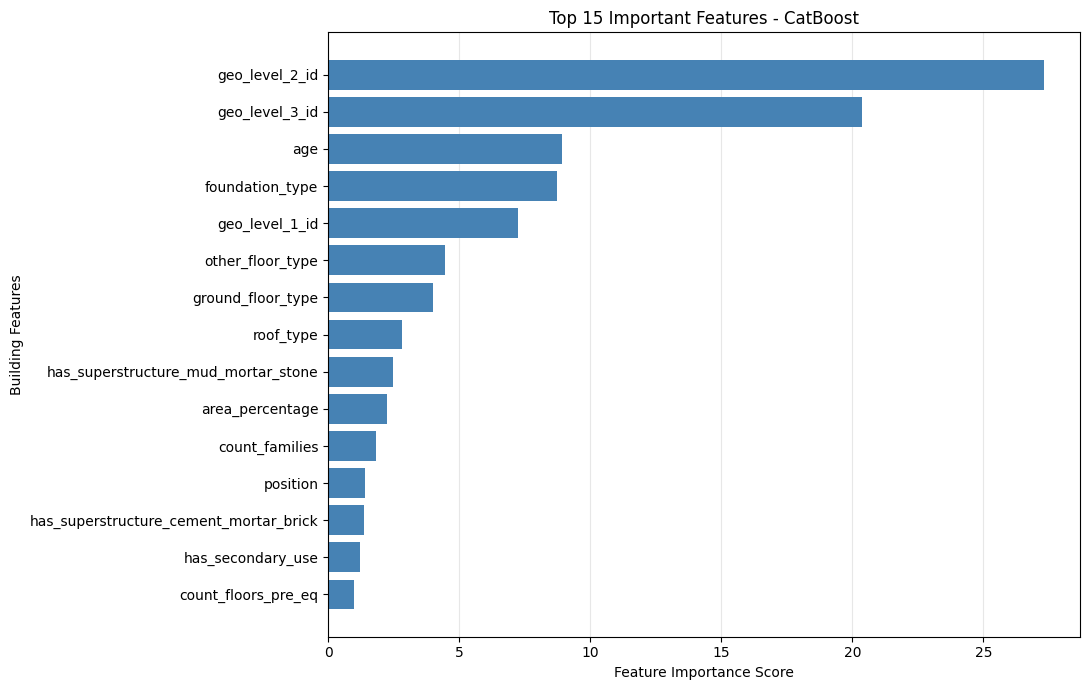


TOTAL FEATURE IMPORTANCE
Sum of all importance scores: 100.00


In [49]:

# Cell 46 - CatBoost Feature Importance Analysis

# Step 1: Extract feature importance scores
importance_scores = cb_model.get_feature_importance()

# Step 2: Create a feature importance DataFrame
feature_importance_df = pd.DataFrame({
    "Feature": X_train_cb.columns,
    "Importance": importance_scores
})

# Step 3: Sort features by importance
feature_importance_df = feature_importance_df.sort_values(
    by="Importance",
    ascending=False
).reset_index(drop=True)

# Step 4: Display the top 15 important features
print("TOP 15 CATBOOST FEATURE IMPORTANCES")
print("=" * 60)

display(
    feature_importance_df.head(15).round(2)
)

# Step 5: Visualize the top 15 features
top_features = feature_importance_df.head(15).sort_values(
    "Importance",
    ascending=True
)

fig, ax = plt.subplots(figsize=(11, 7))

ax.barh(
    top_features["Feature"],
    top_features["Importance"],
    color="steelblue"
)

# Step 6: Customize the chart
ax.set_title("Top 15 Important Features - CatBoost")
ax.set_xlabel("Feature Importance Score")
ax.set_ylabel("Building Features")

ax.grid(axis="x", alpha=0.3)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

# Step 7: Check total feature importance
print("\nTOTAL FEATURE IMPORTANCE")
print("=" * 60)

print(
    f"Sum of all importance scores: "
    f"{feature_importance_df['Importance'].sum():.2f}"
)


In [50]:

# Cell 47 - Create an internal development split
# For CatBoost hyperparameter tuning

from sklearn.model_selection import train_test_split

# Step 1: Split existing training data
X_dev_train, X_dev_val, y_dev_train, y_dev_val = (
    train_test_split(
        X_train_cb,
        y_train,
        test_size=0.20,
        random_state=123,
        stratify=y_train
    )
)

# Step 2: Display dataset shapes
print("DEVELOPMENT DATASET SPLIT")
print("=" * 60)

print("Development training:", X_dev_train.shape)
print("Development validation:", X_dev_val.shape)

print("\nDevelopment training labels:", y_dev_train.shape)
print("Development validation labels:", y_dev_val.shape)

# Step 3: Verify class distributions
dev_distribution = pd.DataFrame({
    "Development Train (%)": (
        y_dev_train.value_counts(normalize=True) * 100
    ),
    "Development Validation (%)": (
        y_dev_val.value_counts(normalize=True) * 100
    )
}).sort_index()

print("\nDAMAGE GRADE DISTRIBUTION")
print("=" * 60)

display(dev_distribution.round(2))

# Step 4: Check for overlapping records
dev_overlap = X_dev_train.index.intersection(
    X_dev_val.index
)

print("\nOverlapping rows:", len(dev_overlap))

# Step 5: Confirm the full original training set is represented
print(
    "Total development records:",
    len(X_dev_train) + len(X_dev_val)
)

assert len(dev_overlap) == 0
assert len(X_dev_train) + len(X_dev_val) == len(X_train_cb)

print("\nDevelopment split verification: PASSED")


DEVELOPMENT DATASET SPLIT
Development training: (166784, 38)
Development validation: (41696, 38)

Development training labels: (166784,)
Development validation labels: (41696,)

DAMAGE GRADE DISTRIBUTION


,Development Train (%),Development Validation (%)
damage_grade,,
1,9.64,9.64
2,56.89,56.89
3,33.47,33.47



Overlapping rows: 0
Total development records: 208480

Development split verification: PASSED


In [51]:

# Cell 48 - CatBoost development baseline with early stopping

from catboost import CatBoostClassifier
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    recall_score
)

# Step 1: Create the development baseline
dev_cb_model = CatBoostClassifier(
    iterations=350,
    depth=6,
    learning_rate=0.07,
    loss_function="MultiClass",
    eval_metric="TotalF1:average=Macro",
    random_seed=42,
    thread_count=2,
    verbose=False,
    allow_writing_files=False
)

# Step 2: Train with early stopping
dev_cb_model.fit(
    X_dev_train,
    y_dev_train,
    cat_features=cat_cols,
    eval_set=(X_dev_val, y_dev_val),
    early_stopping_rounds=60,
    use_best_model=True
)

# Step 3: Predict development-validation labels
dev_cb_pred = (
    dev_cb_model.predict(X_dev_val)
    .ravel()
    .astype(int)
)

# Step 4: Calculate performance metrics
dev_cb_accuracy = accuracy_score(
    y_dev_val, dev_cb_pred
)

dev_cb_macro_f1 = f1_score(
    y_dev_val,
    dev_cb_pred,
    average="macro"
)

dev_cb_recall = recall_score(
    y_dev_val,
    dev_cb_pred,
    labels=[1, 2, 3],
    average=None
)

# Step 5: Display results
print("CATBOOST DEVELOPMENT BASELINE")
print("=" * 60)

print(f"Accuracy: {dev_cb_accuracy:.4f}")
print(f"Macro F1: {dev_cb_macro_f1:.4f}")

print("\nCLASS-WISE RECALL")
print("=" * 60)

for grade, recall in zip([1, 2, 3], dev_cb_recall):
    print(f"Grade {grade} Recall: {recall:.4f}")

# Step 6: Inspect early stopping
print("\nEARLY STOPPING RESULTS")
print("=" * 60)

print("Maximum allowed iterations: 350")
print("Best iteration:", dev_cb_model.get_best_iteration())
print("Trees retained:", dev_cb_model.tree_count_)

# Step 7: Store development results for later comparison
tuning_results = pd.DataFrame([{
    "Configuration": "Baseline - Depth 6",
    "Depth": 6,
    "Learning Rate": 0.07,
    "Trees Retained": dev_cb_model.tree_count_,
    "Accuracy": dev_cb_accuracy,
    "Macro F1": dev_cb_macro_f1,
    "Grade 3 Recall": dev_cb_recall[2]
}])

print("\nHYPERPARAMETER TUNING RESULTS")
print("=" * 60)

display(tuning_results.round(4))


CATBOOST DEVELOPMENT BASELINE
Accuracy: 0.7445
Macro F1: 0.6916

CLASS-WISE RECALL
Grade 1 Recall: 0.5117
Grade 2 Recall: 0.8545
Grade 3 Recall: 0.6246

EARLY STOPPING RESULTS
Maximum allowed iterations: 350
Best iteration: 327
Trees retained: 328

HYPERPARAMETER TUNING RESULTS


,Configuration,Depth,Learning Rate,Trees Retained,Accuracy,Macro F1,Grade 3 Recall
0,Baseline - Depth 6,6,0.07,328,0.7445,0.6916,0.6246


In [52]:

# Cell 49 - CatBoost Hyperparameter Tuning
# Experiment 1: Increase iterations from 350 to 700

# Step 1: Create the experimental model
cb_exp1 = CatBoostClassifier(
    iterations=700,
    depth=6,
    learning_rate=0.07,
    loss_function="MultiClass",
    eval_metric="TotalF1:average=Macro",
    random_seed=42,
    thread_count=2,
    verbose=False,
    allow_writing_files=False
)

# Step 2: Train using the development split
cb_exp1.fit(
    X_dev_train,
    y_dev_train,
    cat_features=cat_cols,
    eval_set=(X_dev_val, y_dev_val),
    early_stopping_rounds=60,
    use_best_model=True
)

# Step 3: Predict development-validation labels
cb_exp1_pred = (
    cb_exp1.predict(X_dev_val)
    .ravel()
    .astype(int)
)

# Step 4: Calculate evaluation metrics
cb_exp1_accuracy = accuracy_score(
    y_dev_val,
    cb_exp1_pred
)

cb_exp1_macro_f1 = f1_score(
    y_dev_val,
    cb_exp1_pred,
    average="macro"
)

cb_exp1_recall = recall_score(
    y_dev_val,
    cb_exp1_pred,
    labels=[1, 2, 3],
    average=None
)

# Step 5: Display experimental results
print("CATBOOST EXPERIMENT 1 - 700 ITERATIONS")
print("=" * 60)

print(f"Accuracy: {cb_exp1_accuracy:.4f}")
print(f"Macro F1: {cb_exp1_macro_f1:.4f}")

print("\nCLASS-WISE RECALL")
print("=" * 60)

for grade, recall in zip([1, 2, 3], cb_exp1_recall):
    print(f"Grade {grade} Recall: {recall:.4f}")

# Step 6: Examine the selected iteration
print("\nTRAINING RESULTS")
print("=" * 60)

print("Maximum allowed iterations: 700")
print("Best iteration:", cb_exp1.get_best_iteration())
print("Trees retained:", cb_exp1.tree_count_)

# Step 7: Add experiment to the tuning table
exp1_result = pd.DataFrame([{
    "Configuration": "Experiment 1 - 700 Iterations",
    "Depth": 6,
    "Learning Rate": 0.07,
    "Trees Retained": cb_exp1.tree_count_,
    "Accuracy": cb_exp1_accuracy,
    "Macro F1": cb_exp1_macro_f1,
    "Grade 3 Recall": cb_exp1_recall[2]
}])

tuning_results = pd.concat(
    [tuning_results, exp1_result],
    ignore_index=True
)

print("\nHYPERPARAMETER TUNING COMPARISON")
print("=" * 60)

display(tuning_results.round(4))

# Step 8: Calculate improvement over development baseline
f1_improvement = (
    cb_exp1_macro_f1 - dev_cb_macro_f1
)

print("\nMACRO F1 IMPROVEMENT OVER BASELINE")
print("=" * 60)

print(f"Macro F1 difference: {f1_improvement:+.4f}")


CATBOOST EXPERIMENT 1 - 700 ITERATIONS
Accuracy: 0.7458
Macro F1: 0.6939

CLASS-WISE RECALL
Grade 1 Recall: 0.5182
Grade 2 Recall: 0.8561
Grade 3 Recall: 0.6239

TRAINING RESULTS
Maximum allowed iterations: 700
Best iteration: 457
Trees retained: 458

HYPERPARAMETER TUNING COMPARISON


,Configuration,Depth,Learning Rate,Trees Retained,Accuracy,Macro F1,Grade 3 Recall
0,Baseline - Depth 6,6,0.07,328,0.7445,0.6916,0.6246
1,Experiment 1 - 700 Iterations,6,0.07,458,0.7458,0.6939,0.6239



MACRO F1 IMPROVEMENT OVER BASELINE
Macro F1 difference: +0.0023


In [53]:

# Cell 50 - CatBoost Hyperparameter Tuning
# Experiment 2: Increase tree depth from 6 to 8

# Step 1: Create the experimental model
cb_exp2 = CatBoostClassifier(
    iterations=700,
    depth=8,
    learning_rate=0.07,
    loss_function="MultiClass",
    eval_metric="TotalF1:average=Macro",
    random_seed=42,
    thread_count=2,
    verbose=False,
    allow_writing_files=False
)

# Step 2: Train using development data only
cb_exp2.fit(
    X_dev_train,
    y_dev_train,
    cat_features=cat_cols,
    eval_set=(X_dev_val, y_dev_val),
    early_stopping_rounds=60,
    use_best_model=True
)

# Step 3: Predict development-validation labels
cb_exp2_pred = (
    cb_exp2.predict(X_dev_val)
    .ravel()
    .astype(int)
)

# Step 4: Calculate evaluation metrics
cb_exp2_accuracy = accuracy_score(
    y_dev_val,
    cb_exp2_pred
)

cb_exp2_macro_f1 = f1_score(
    y_dev_val,
    cb_exp2_pred,
    average="macro"
)

cb_exp2_recall = recall_score(
    y_dev_val,
    cb_exp2_pred,
    labels=[1, 2, 3],
    average=None
)

# Step 5: Display model performance
print("CATBOOST EXPERIMENT 2 - DEPTH 8")
print("=" * 60)

print(f"Accuracy: {cb_exp2_accuracy:.4f}")
print(f"Macro F1: {cb_exp2_macro_f1:.4f}")

print("\nCLASS-WISE RECALL")
print("=" * 60)

for grade, recall in zip([1, 2, 3], cb_exp2_recall):
    print(f"Grade {grade} Recall: {recall:.4f}")

# Step 6: Inspect early stopping
print("\nTRAINING RESULTS")
print("=" * 60)

print("Maximum allowed iterations: 700")
print("Best iteration:", cb_exp2.get_best_iteration())
print("Trees retained:", cb_exp2.tree_count_)

# Step 7: Store experiment results
exp2_result = pd.DataFrame([{
    "Configuration": "Experiment 2 - Depth 8",
    "Depth": 8,
    "Learning Rate": 0.07,
    "Trees Retained": cb_exp2.tree_count_,
    "Accuracy": cb_exp2_accuracy,
    "Macro F1": cb_exp2_macro_f1,
    "Grade 3 Recall": cb_exp2_recall[2]
}])

tuning_results = pd.concat(
    [tuning_results, exp2_result],
    ignore_index=True
)

print("\nHYPERPARAMETER TUNING COMPARISON")
print("=" * 60)

display(
    tuning_results.sort_values(
        "Macro F1",
        ascending=False
    ).round(4)
)

# Step 8: Compare directly with Experiment 1
print("\nEXPERIMENT 2 VS EXPERIMENT 1")
print("=" * 60)

print(
    f"Macro F1 difference: "
    f"{cb_exp2_macro_f1 - cb_exp1_macro_f1:+.4f}"
)

print(
    f"Grade 3 recall difference: "
    f"{cb_exp2_recall[2] - cb_exp1_recall[2]:+.4f}"
)


CATBOOST EXPERIMENT 2 - DEPTH 8
Accuracy: 0.7475
Macro F1: 0.6969

CLASS-WISE RECALL
Grade 1 Recall: 0.5254
Grade 2 Recall: 0.8563
Grade 3 Recall: 0.6264

TRAINING RESULTS
Maximum allowed iterations: 700
Best iteration: 548
Trees retained: 549

HYPERPARAMETER TUNING COMPARISON


,Configuration,Depth,Learning Rate,Trees Retained,Accuracy,Macro F1,Grade 3 Recall
2,Experiment 2 - Depth 8,8,0.07,549,0.7475,0.6969,0.6264
1,Experiment 1 - 700 Iterations,6,0.07,458,0.7458,0.6939,0.6239
0,Baseline - Depth 6,6,0.07,328,0.7445,0.6916,0.6246



EXPERIMENT 2 VS EXPERIMENT 1
Macro F1 difference: +0.0031
Grade 3 recall difference: +0.0024


In [54]:

# Cell 51 - CatBoost Hyperparameter Tuning
# Experiment 3: Increase learning rate from 0.07 to 0.10

# Step 1: Create the experimental model
cb_exp3 = CatBoostClassifier(
    iterations=700,
    depth=8,
    learning_rate=0.10,
    loss_function="MultiClass",
    eval_metric="TotalF1:average=Macro",
    random_seed=42,
    thread_count=2,
    verbose=False,
    allow_writing_files=False
)

# Step 2: Train using development data only
cb_exp3.fit(
    X_dev_train,
    y_dev_train,
    cat_features=cat_cols,
    eval_set=(X_dev_val, y_dev_val),
    early_stopping_rounds=60,
    use_best_model=True
)

# Step 3: Predict development-validation labels
cb_exp3_pred = (
    cb_exp3.predict(X_dev_val)
    .ravel()
    .astype(int)
)

# Step 4: Calculate evaluation metrics
cb_exp3_accuracy = accuracy_score(
    y_dev_val,
    cb_exp3_pred
)

cb_exp3_macro_f1 = f1_score(
    y_dev_val,
    cb_exp3_pred,
    average="macro"
)

cb_exp3_recall = recall_score(
    y_dev_val,
    cb_exp3_pred,
    labels=[1, 2, 3],
    average=None
)

# Step 5: Display performance
print("CATBOOST EXPERIMENT 3 - LEARNING RATE 0.10")
print("=" * 60)

print(f"Accuracy: {cb_exp3_accuracy:.4f}")
print(f"Macro F1: {cb_exp3_macro_f1:.4f}")

print("\nCLASS-WISE RECALL")
print("=" * 60)

for grade, recall in zip([1, 2, 3], cb_exp3_recall):
    print(f"Grade {grade} Recall: {recall:.4f}")

# Step 6: Examine early stopping
print("\nTRAINING RESULTS")
print("=" * 60)

print("Maximum allowed iterations: 700")
print("Best iteration:", cb_exp3.get_best_iteration())
print("Trees retained:", cb_exp3.tree_count_)

# Step 7: Store the experiment
exp3_result = pd.DataFrame([{
    "Configuration": "Experiment 3 - Learning Rate 0.10",
    "Depth": 8,
    "Learning Rate": 0.10,
    "Trees Retained": cb_exp3.tree_count_,
    "Accuracy": cb_exp3_accuracy,
    "Macro F1": cb_exp3_macro_f1,
    "Grade 3 Recall": cb_exp3_recall[2]
}])

tuning_results = pd.concat(
    [tuning_results, exp3_result],
    ignore_index=True
)

# Step 8: Compare all configurations
print("\nHYPERPARAMETER TUNING COMPARISON")
print("=" * 60)

display(
    tuning_results.sort_values(
        "Macro F1",
        ascending=False
    ).round(4)
)

# Step 9: Compare Experiment 3 with Experiment 2
print("\nEXPERIMENT 3 VS EXPERIMENT 2")
print("=" * 60)

print(
    f"Macro F1 difference: "
    f"{cb_exp3_macro_f1 - cb_exp2_macro_f1:+.4f}"
)

print(
    f"Accuracy difference: "
    f"{cb_exp3_accuracy - cb_exp2_accuracy:+.4f}"
)

print(
    f"Grade 3 recall difference: "
    f"{cb_exp3_recall[2] - cb_exp2_recall[2]:+.4f}"
)


CATBOOST EXPERIMENT 3 - LEARNING RATE 0.10
Accuracy: 0.7453
Macro F1: 0.6948

CLASS-WISE RECALL
Grade 1 Recall: 0.5229
Grade 2 Recall: 0.8536
Grade 3 Recall: 0.6252

TRAINING RESULTS
Maximum allowed iterations: 700
Best iteration: 340
Trees retained: 341

HYPERPARAMETER TUNING COMPARISON


,Configuration,Depth,Learning Rate,Trees Retained,Accuracy,Macro F1,Grade 3 Recall
2,Experiment 2 - Depth 8,8,0.07,549,0.7475,0.6969,0.6264
3,Experiment 3 - Learning Rate 0.10,8,0.10,341,0.7453,0.6948,0.6252
1,Experiment 1 - 700 Iterations,6,0.07,458,0.7458,0.6939,0.6239
0,Baseline - Depth 6,6,0.07,328,0.7445,0.6916,0.6246



EXPERIMENT 3 VS EXPERIMENT 2
Macro F1 difference: -0.0021
Accuracy difference: -0.0022
Grade 3 recall difference: -0.0011


In [55]:

# Cell 52 - Train selected CatBoost configuration
# Using all 208,480 original training buildings

# Step 1: Create the selected CatBoost model
cb_tuned_model = CatBoostClassifier(
    iterations=549,
    depth=8,
    learning_rate=0.07,
    loss_function="MultiClass",
    random_seed=42,
    thread_count=2,
    verbose=False,
    allow_writing_files=False
)

# Step 2: Train on the full training partition
cb_tuned_model.fit(
    X_train_cb,
    y_train,
    cat_features=cat_cols
)

# Step 3: Predict on the original validation partition
cb_tuned_pred = (
    cb_tuned_model.predict(X_val_cb)
    .ravel()
    .astype(int)
)

# Step 4: Calculate evaluation metrics
cb_tuned_accuracy = accuracy_score(
    y_val,
    cb_tuned_pred
)

cb_tuned_macro_f1 = f1_score(
    y_val,
    cb_tuned_pred,
    average="macro"
)

cb_tuned_recall = recall_score(
    y_val,
    cb_tuned_pred,
    labels=[1, 2, 3],
    average=None
)

# Step 5: Display results
print("TUNED CATBOOST - VALIDATION RESULTS")
print("=" * 60)

print(f"Accuracy: {cb_tuned_accuracy:.4f}")
print(f"Macro F1: {cb_tuned_macro_f1:.4f}")

print("\nCLASS-WISE RECALL")
print("=" * 60)

for grade, recall in zip([1, 2, 3], cb_tuned_recall):
    print(f"Grade {grade} Recall: {recall:.4f}")

# Step 6: Detailed classification report
print("\nCLASSIFICATION REPORT")
print("=" * 60)

print(classification_report(
    y_val,
    cb_tuned_pred,
    labels=[1, 2, 3],
    zero_division=0
))

# Step 7: Confusion matrix
print("\nCONFUSION MATRIX")
print("=" * 60)

cb_tuned_cm = confusion_matrix(
    y_val,
    cb_tuned_pred,
    labels=[1, 2, 3]
)

display(pd.DataFrame(
    cb_tuned_cm,
    index=["Actual 1", "Actual 2", "Actual 3"],
    columns=["Predicted 1", "Predicted 2", "Predicted 3"]
))

# Step 8: Compare initial and tuned CatBoost
catboost_comparison = pd.DataFrame({
    "Model": [
        "Initial CatBoost",
        "Tuned CatBoost"
    ],
    "Accuracy": [
        cb_accuracy,
        cb_tuned_accuracy
    ],
    "Macro F1": [
        cb_macro_f1,
        cb_tuned_macro_f1
    ]
})

print("\nINITIAL VS TUNED CATBOOST")
print("=" * 60)

display(catboost_comparison.round(4))

# Step 9: Calculate improvements
print("\nPERFORMANCE DIFFERENCES")
print("=" * 60)

print(
    f"Accuracy difference: "
    f"{cb_tuned_accuracy - cb_accuracy:+.4f}"
)

print(
    f"Macro F1 difference: "
    f"{cb_tuned_macro_f1 - cb_macro_f1:+.4f}"
)


TUNED CATBOOST - VALIDATION RESULTS
Accuracy: 0.7505
Macro F1: 0.7015

CLASS-WISE RECALL
Grade 1 Recall: 0.5439
Grade 2 Recall: 0.8510
Grade 3 Recall: 0.6393

CLASSIFICATION REPORT
              precision    recall  f1-score   support

           1       0.69      0.54      0.61      5025
           2       0.75      0.85      0.80     29652
           3       0.77      0.64      0.70     17444

    accuracy                           0.75     52121
   macro avg       0.74      0.68      0.70     52121
weighted avg       0.75      0.75      0.75     52121


CONFUSION MATRIX


,Predicted 1,Predicted 2,Predicted 3
Actual 1,2733,2231,61
Actual 2,1111,25234,3307
Actual 3,99,6193,11152



INITIAL VS TUNED CATBOOST


,Model,Accuracy,Macro F1
0,Initial CatBoost,0.7487,0.6975
1,Tuned CatBoost,0.7505,0.7015



PERFORMANCE DIFFERENCES
Accuracy difference: +0.0019
Macro F1 difference: +0.0040


In [56]:

# Cell 53 - Geographic error analysis
# Evaluate tuned CatBoost performance by geo_level_1_id

# Step 1: Build a validation analysis DataFrame
regional_eval = pd.DataFrame({
    "geo_level_1_id": (
        X_val_cb["geo_level_1_id"].astype(str).to_numpy()
    ),
    "actual": y_val.to_numpy(),
    "predicted": cb_tuned_pred
})

# Step 2: Identify correct predictions and Grade 3 cases
regional_eval["correct"] = (
    regional_eval["actual"] == regional_eval["predicted"]
).astype(int)

regional_eval["actual_grade_3"] = (
    regional_eval["actual"] == 3
).astype(int)

regional_eval["correct_grade_3"] = (
    (regional_eval["actual"] == 3) &
    (regional_eval["predicted"] == 3)
).astype(int)

# Step 3: Calculate regional performance
regional_results = regional_eval.groupby(
    "geo_level_1_id",
    as_index=False
).agg(
    Buildings=("actual", "size"),
    Actual_Grade_3=("actual_grade_3", "sum"),
    Correct_Grade_3=("correct_grade_3", "sum"),
    Total_Correct=("correct", "sum")
)

# Step 4: Calculate accuracy and Grade 3 recall
regional_results["Accuracy"] = (
    regional_results["Total_Correct"] /
    regional_results["Buildings"]
)

regional_results["Grade_3_Recall"] = (
    regional_results["Correct_Grade_3"] /
    regional_results["Actual_Grade_3"].replace(0, np.nan)
)

# Step 5: Keep regions with sufficient Grade 3 examples
reliable_regions = regional_results[
    regional_results["Actual_Grade_3"] >= 100
].copy()

print("GEOGRAPHIC PERFORMANCE SUMMARY")
print("=" * 60)

print("Total geo_level_1 regions:", len(regional_results))
print("Regions with at least 100 Grade 3 buildings:",
      len(reliable_regions))

print("\nOVERALL GRADE 3 RECALL")
print("=" * 60)
print(f"{cb_tuned_recall[2]:.4f}")

# Step 6: Display regions with lowest Grade 3 recall
print("\n10 REGIONS WITH LOWEST GRADE 3 RECALL")
print("=" * 60)

display(
    reliable_regions.sort_values(
        "Grade_3_Recall",
        ascending=True
    )[[
        "geo_level_1_id",
        "Buildings",
        "Actual_Grade_3",
        "Correct_Grade_3",
        "Accuracy",
        "Grade_3_Recall"
    ]].head(10).round(4)
)

# Step 7: Display regions with highest Grade 3 recall
print("\n10 REGIONS WITH HIGHEST GRADE 3 RECALL")
print("=" * 60)

display(
    reliable_regions.sort_values(
        "Grade_3_Recall",
        ascending=False
    )[[
        "geo_level_1_id",
        "Buildings",
        "Actual_Grade_3",
        "Correct_Grade_3",
        "Accuracy",
        "Grade_3_Recall"
    ]].head(10).round(4)
)

# Step 8: Summarize performance variation
print("\nREGIONAL RECALL VARIATION")
print("=" * 60)

print(
    "Lowest regional Grade 3 recall:",
    round(reliable_regions["Grade_3_Recall"].min(), 4)
)

print(
    "Highest regional Grade 3 recall:",
    round(reliable_regions["Grade_3_Recall"].max(), 4)
)


GEOGRAPHIC PERFORMANCE SUMMARY
Total geo_level_1 regions: 31
Regions with at least 100 Grade 3 buildings: 20

OVERALL GRADE 3 RECALL
0.6393

10 REGIONS WITH LOWEST GRADE 3 RECALL


,geo_level_1_id,Buildings,Actual_Grade_3,Correct_Grade_3,Accuracy,Grade_3_Recall
0,0,801,107,4,0.7828,0.0374
15,22,1243,152,6,0.7788,0.0395
13,20,3515,403,25,0.7536,0.0620
19,26,4589,364,28,0.7019,0.0769
18,25,1105,162,15,0.8018,0.0926
5,13,1863,240,36,0.7424,0.1500
25,4,2858,542,106,0.7908,0.1956
4,12,630,144,29,0.7032,0.2014
30,9,755,138,29,0.7377,0.2101
8,16,896,180,40,0.7891,0.2222



10 REGIONS WITH HIGHEST GRADE 3 RECALL


,geo_level_1_id,Buildings,Actual_Grade_3,Correct_Grade_3,Accuracy,Grade_3_Recall
9,17,4386,3562,3445,0.8564,0.9672
10,18,653,478,441,0.7933,0.9226
14,21,2938,1738,1435,0.7355,0.8257
20,27,2561,1264,938,0.6900,0.7421
29,8,3775,1990,1476,0.6874,0.7417
2,10,4430,1745,1127,0.7334,0.6458
28,7,3811,1386,826,0.7741,0.5960
3,11,1611,635,328,0.6958,0.5165
23,3,1550,566,267,0.6948,0.4717
27,6,4863,1164,501,0.7683,0.4304



REGIONAL RECALL VARIATION
Lowest regional Grade 3 recall: 0.0374
Highest regional Grade 3 recall: 0.9672


SELECTED REGIONS - ACTUAL VS PREDICTED DAMAGE


,geo_level_1_id,Buildings,Actual_Grade_3_Pct,Predicted_Grade_3_Pct,Missed_Grade_3,Grade_3_Recall,Grade_3_Precision
19,26,4589,7.9320,1.1331,336,0.0769,0.5385
13,20,3515,11.4651,1.1949,378,0.0620,0.5952
0,0,801,13.3583,0.9988,103,0.0374,0.5000
14,21,2938,59.1559,63.6147,303,0.8257,0.7678
10,18,653,73.2006,81.4701,37,0.9226,0.8289
9,17,4386,81.2130,89.5121,117,0.9672,0.8775



PREVALENCE VS RECALL
Regions analyzed: 20
Spearman correlation: 0.9594


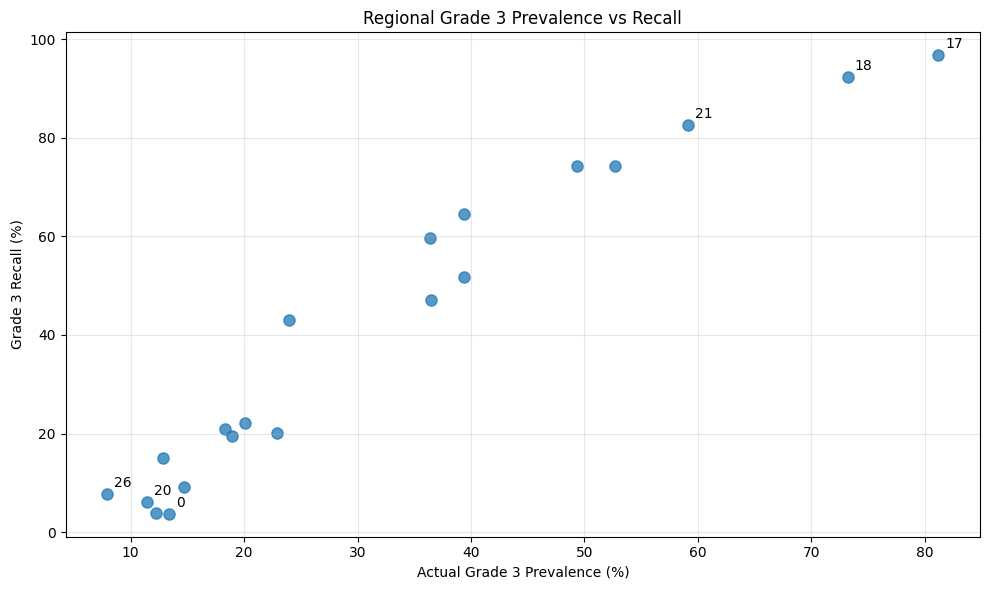

In [57]:

# Cell 54 - Regional class distribution and prediction bias

# Step 1: Identify predicted Grade 3 buildings
regional_eval["predicted_grade_3"] = (
    regional_eval["predicted"] == 3
).astype(int)

# Step 2: Identify missed Grade 3 buildings
regional_eval["missed_grade_3"] = (
    (regional_eval["actual"] == 3) &
    (regional_eval["predicted"] != 3)
).astype(int)

# Step 3: Group statistics by geographic region
regional_bias = regional_eval.groupby(
    "geo_level_1_id",
    as_index=False
).agg(
    Buildings=("actual", "size"),
    Actual_Grade_3=("actual_grade_3", "sum"),
    Predicted_Grade_3=("predicted_grade_3", "sum"),
    Correct_Grade_3=("correct_grade_3", "sum"),
    Missed_Grade_3=("missed_grade_3", "sum")
)

# Step 4: Calculate actual Grade 3 percentage
regional_bias["Actual_Grade_3_Pct"] = (
    regional_bias["Actual_Grade_3"] /
    regional_bias["Buildings"] * 100
)

# Step 5: Calculate predicted Grade 3 percentage
regional_bias["Predicted_Grade_3_Pct"] = (
    regional_bias["Predicted_Grade_3"] /
    regional_bias["Buildings"] * 100
)

# Step 6: Calculate Grade 3 recall
regional_bias["Grade_3_Recall"] = (
    regional_bias["Correct_Grade_3"] /
    regional_bias["Actual_Grade_3"].replace(0, np.nan)
)

# Step 7: Calculate Grade 3 precision
regional_bias["Grade_3_Precision"] = (
    regional_bias["Correct_Grade_3"] /
    regional_bias["Predicted_Grade_3"].replace(0, np.nan)
)

# Step 8: Examine selected regions
selected_regions = ["0", "20", "26", "17", "18", "21"]

selected_bias = regional_bias[
    regional_bias["geo_level_1_id"].isin(selected_regions)
].copy()

print("SELECTED REGIONS - ACTUAL VS PREDICTED DAMAGE")
print("=" * 60)

display(
    selected_bias[[
        "geo_level_1_id",
        "Buildings",
        "Actual_Grade_3_Pct",
        "Predicted_Grade_3_Pct",
        "Missed_Grade_3",
        "Grade_3_Recall",
        "Grade_3_Precision"
    ]].sort_values(
        "Actual_Grade_3_Pct"
    ).round(4)
)

# Step 9: Analyze regional prevalence and recall
eligible_regions = regional_bias[
    regional_bias["Actual_Grade_3"] >= 100
].copy()

spearman_corr = eligible_regions[
    ["Actual_Grade_3_Pct", "Grade_3_Recall"]
].corr(method="spearman").iloc[0, 1]

print("\nPREVALENCE VS RECALL")
print("=" * 60)

print("Regions analyzed:", len(eligible_regions))
print(
    "Spearman correlation:",
    round(spearman_corr, 4)
)

# Step 10: Visualize the relationship
fig, ax = plt.subplots(figsize=(10, 6))

ax.scatter(
    eligible_regions["Actual_Grade_3_Pct"],
    eligible_regions["Grade_3_Recall"] * 100,
    s=65,
    alpha=0.75
)

# Label the selected regions
for _, row in selected_bias.iterrows():
    ax.annotate(
        str(row["geo_level_1_id"]),
        (
            row["Actual_Grade_3_Pct"],
            row["Grade_3_Recall"] * 100
        ),
        xytext=(5, 5),
        textcoords="offset points"
    )

ax.set_title("Regional Grade 3 Prevalence vs Recall")
ax.set_xlabel("Actual Grade 3 Prevalence (%)")
ax.set_ylabel("Grade 3 Recall (%)")
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()


In [58]:

# Cell 55 - Geographic holdout validation
# Keep entire geo_level_1 regions separate

from sklearn.model_selection import GroupShuffleSplit

# Step 1: Use the original full dataset
geo_groups = X["geo_level_1_id"]

# Step 2: Create group-based splitting strategy
geo_splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42
)

# Step 3: Generate training and holdout indices
geo_train_idx, geo_test_idx = next(
    geo_splitter.split(
        X,
        y,
        groups=geo_groups
    )
)

# Step 4: Create geographic training and holdout datasets
X_geo_train = X.iloc[geo_train_idx].copy()
X_geo_test = X.iloc[geo_test_idx].copy()

y_geo_train = y.iloc[geo_train_idx].copy()
y_geo_test = y.iloc[geo_test_idx].copy()

# Step 5: Identify geographic regions
train_regions = set(
    X_geo_train["geo_level_1_id"].unique()
)

test_regions = set(
    X_geo_test["geo_level_1_id"].unique()
)

overlapping_regions = train_regions.intersection(
    test_regions
)

# Step 6: Print dataset sizes
print("GEOGRAPHIC HOLDOUT DATASET SPLIT")
print("=" * 60)

print("Training shape:", X_geo_train.shape)
print("Holdout shape:", X_geo_test.shape)

print("\nTraining regions:", len(train_regions))
print("Holdout regions:", len(test_regions))

print("\nHoldout region IDs:")
print(sorted(test_regions))

print("\nOverlapping geographic regions:",
      len(overlapping_regions))

# Step 7: Compare damage-grade distributions
geo_class_distribution = pd.DataFrame({
    "Geographic Train (%)": (
        y_geo_train.value_counts(normalize=True) * 100
    ),
    "Geographic Holdout (%)": (
        y_geo_test.value_counts(normalize=True) * 100
    )
}).reindex([1, 2, 3]).fillna(0)

print("\nDAMAGE GRADE DISTRIBUTION")
print("=" * 60)

display(geo_class_distribution.round(2))

# Step 8: Verify no geographic overlap
assert len(overlapping_regions) == 0

assert (
    len(X_geo_train) + len(X_geo_test)
    == len(X)
)

assert (
    len(train_regions) + len(test_regions)
    == geo_groups.nunique()
)

print("\nGeographic split verification: PASSED")


GEOGRAPHIC HOLDOUT DATASET SPLIT
Training shape: (199381, 38)
Holdout shape: (61220, 38)

Training regions: 24
Holdout regions: 7

Holdout region IDs:
[np.int64(8), np.int64(9), np.int64(15), np.int64(17), np.int64(23), np.int64(27), np.int64(29)]

Overlapping geographic regions: 0

DAMAGE GRADE DISTRIBUTION


,Geographic Train (%),Geographic Holdout (%)
damage_grade,,
1,11.49,3.61
2,62.34,39.13
3,26.16,57.26



Geographic split verification: PASSED


In [59]:

# Cell 56 - Geographic Holdout Model Evaluation

from catboost import CatBoostClassifier

# Step 1: Prepare categorical features
X_geo_train_cb = X_geo_train.copy()
X_geo_test_cb = X_geo_test.copy()

for col in cat_cols:
    X_geo_train_cb[col] = (
        X_geo_train_cb[col].astype(str).astype(object)
    )
    X_geo_test_cb[col] = (
        X_geo_test_cb[col].astype(str).astype(object)
    )

# Step 2: Create a fresh CatBoost model
geo_cb_model = CatBoostClassifier(
    iterations=549,
    depth=8,
    learning_rate=0.07,
    loss_function="MultiClass",
    random_seed=42,
    thread_count=2,
    verbose=False,
    allow_writing_files=False
)

# Step 3: Train using geographic training regions only
geo_cb_model.fit(
    X_geo_train_cb,
    y_geo_train,
    cat_features=cat_cols
)

# Step 4: Predict unseen geographic regions
geo_cb_pred = (
    geo_cb_model.predict(X_geo_test_cb)
    .ravel()
    .astype(int)
)

# Step 5: Calculate evaluation metrics
geo_accuracy = accuracy_score(
    y_geo_test,
    geo_cb_pred
)

geo_macro_f1 = f1_score(
    y_geo_test,
    geo_cb_pred,
    average="macro"
)

geo_recall = recall_score(
    y_geo_test,
    geo_cb_pred,
    labels=[1, 2, 3],
    average=None
)

# Step 6: Print results
print("CATBOOST - GEOGRAPHIC HOLDOUT RESULTS")
print("=" * 60)

print(f"Accuracy: {geo_accuracy:.4f}")
print(f"Macro F1: {geo_macro_f1:.4f}")

print("\nCLASS-WISE RECALL")
print("=" * 60)

for grade, recall in zip([1, 2, 3], geo_recall):
    print(f"Grade {grade} Recall: {recall:.4f}")

# Step 7: Classification report
print("\nCLASSIFICATION REPORT")
print("=" * 60)

print(classification_report(
    y_geo_test,
    geo_cb_pred,
    labels=[1, 2, 3],
    zero_division=0
))

# Step 8: Confusion matrix
print("\nCONFUSION MATRIX")
print("=" * 60)

geo_cm = confusion_matrix(
    y_geo_test,
    geo_cb_pred,
    labels=[1, 2, 3]
)

display(pd.DataFrame(
    geo_cm,
    index=["Actual 1", "Actual 2", "Actual 3"],
    columns=["Predicted 1", "Predicted 2", "Predicted 3"]
))

# Step 9: Training-majority baseline
majority_geo_grade = (
    y_geo_train.value_counts().idxmax()
)

geo_majority_pred = np.full(
    len(y_geo_test),
    majority_geo_grade
)

geo_majority_accuracy = accuracy_score(
    y_geo_test,
    geo_majority_pred
)

geo_majority_f1 = f1_score(
    y_geo_test,
    geo_majority_pred,
    average="macro",
    zero_division=0
)

print("\nGEOGRAPHIC HOLDOUT BASELINE COMPARISON")
print("=" * 60)

geo_comparison = pd.DataFrame({
    "Model": [
        "Training Majority Baseline",
        "Geographic CatBoost"
    ],
    "Accuracy": [
        geo_majority_accuracy,
        geo_accuracy
    ],
    "Macro F1": [
        geo_majority_f1,
        geo_macro_f1
    ]
})

print("Training majority class:", majority_geo_grade)
display(geo_comparison.round(4))

# Step 10: Compare actual and predicted grades
print("\nACTUAL VS PREDICTED DISTRIBUTION")
print("=" * 60)

geo_prediction_distribution = pd.DataFrame({
    "Actual (%)": (
        y_geo_test.value_counts(normalize=True) * 100
    ),
    "Predicted (%)": (
        pd.Series(geo_cb_pred)
        .value_counts(normalize=True) * 100
    )
}).reindex([1, 2, 3]).fillna(0)

display(geo_prediction_distribution.round(2))


CATBOOST - GEOGRAPHIC HOLDOUT RESULTS
Accuracy: 0.3930
Macro F1: 0.3238

CLASS-WISE RECALL
Grade 1 Recall: 0.3492
Grade 2 Recall: 0.9705
Grade 3 Recall: 0.0011

CLASSIFICATION REPORT
              precision    recall  f1-score   support

           1       0.51      0.35      0.41      2208
           2       0.39      0.97      0.56     23956
           3       0.67      0.00      0.00     35056

    accuracy                           0.39     61220
   macro avg       0.52      0.44      0.32     61220
weighted avg       0.56      0.39      0.23     61220


CONFUSION MATRIX


,Predicted 1,Predicted 2,Predicted 3
Actual 1,771,1436,1
Actual 2,689,23250,17
Actual 3,66,34953,37



GEOGRAPHIC HOLDOUT BASELINE COMPARISON
Training majority class: 2


,Model,Accuracy,Macro F1
0,Training Majority Baseline,0.3913,0.1875
1,Geographic CatBoost,0.3930,0.3238



ACTUAL VS PREDICTED DISTRIBUTION


,Actual (%),Predicted (%)
1,3.61,2.49
2,39.13,97.42
3,57.26,0.09


In [60]:

# Cell 57 - Diagnose geographic generalization failure

# Part 1: Identify unseen geographic categories

geo_coverage_results = []

for col in geographic_features:

    train_categories = set(
        X_geo_train[col].unique()
    )

    test_categories = set(
        X_geo_test[col].unique()
    )

    unseen_categories = (
        test_categories - train_categories
    )

    unseen_row_mask = ~X_geo_test[col].isin(
        train_categories
    )

    geo_coverage_results.append({
        "Feature": col,
        "Train Unique": len(train_categories),
        "Holdout Unique": len(test_categories),
        "Unseen Categories": len(unseen_categories),
        "Unseen Holdout Rows (%)": (
            unseen_row_mask.mean() * 100
        )
    })

geo_coverage_df = pd.DataFrame(
    geo_coverage_results
)

print("GEOGRAPHIC CATEGORY COVERAGE")
print("=" * 60)

display(geo_coverage_df.round(2))


# Part 2: Analyze each geographic holdout region

geo_region_eval = pd.DataFrame({
    "Region": X_geo_test[
        "geo_level_1_id"
    ].to_numpy(),

    "Actual": y_geo_test.to_numpy(),

    "Predicted": geo_cb_pred
})

# Create indicators
geo_region_eval["Actual_Grade_3"] = (
    geo_region_eval["Actual"] == 3
).astype(int)

geo_region_eval["Predicted_Grade_3"] = (
    geo_region_eval["Predicted"] == 3
).astype(int)

geo_region_eval["Correct_Grade_3"] = (
    (geo_region_eval["Actual"] == 3) &
    (geo_region_eval["Predicted"] == 3)
).astype(int)

# Group by region
geo_region_summary = geo_region_eval.groupby(
    "Region",
    as_index=False
).agg(
    Buildings=("Actual", "size"),
    Actual_Grade_3=("Actual_Grade_3", "sum"),
    Predicted_Grade_3=("Predicted_Grade_3", "sum"),
    Correct_Grade_3=("Correct_Grade_3", "sum")
)

# Calculate rates
geo_region_summary["Actual_Grade_3_Pct"] = (
    geo_region_summary["Actual_Grade_3"] /
    geo_region_summary["Buildings"] * 100
)

geo_region_summary["Predicted_Grade_3_Pct"] = (
    geo_region_summary["Predicted_Grade_3"] /
    geo_region_summary["Buildings"] * 100
)

geo_region_summary["Grade_3_Recall"] = (
    geo_region_summary["Correct_Grade_3"] /
    geo_region_summary["Actual_Grade_3"].replace(
        0, np.nan
    )
)

geo_region_summary["Missed_Grade_3"] = (
    geo_region_summary["Actual_Grade_3"] -
    geo_region_summary["Correct_Grade_3"]
)

print("\nHOLDOUT REGION PERFORMANCE")
print("=" * 60)

display(
    geo_region_summary.sort_values(
        "Region"
    ).round(4)
)

# Part 3: Verify total severe-damage errors
print("\nGEOGRAPHIC HOLDOUT ERROR SUMMARY")
print("=" * 60)

print(
    "Total actual Grade 3:",
    geo_region_summary["Actual_Grade_3"].sum()
)

print(
    "Total correctly detected Grade 3:",
    geo_region_summary["Correct_Grade_3"].sum()
)

print(
    "Total missed Grade 3:",
    geo_region_summary["Missed_Grade_3"].sum()
)


GEOGRAPHIC CATEGORY COVERAGE


,Feature,Train Unique,Holdout Unique,Unseen Categories,Unseen Holdout Rows (%)
0,geo_level_1_id,24,7,7,100.0
1,geo_level_2_id,1125,289,289,100.0
2,geo_level_3_id,9117,2478,2478,100.0



HOLDOUT REGION PERFORMANCE


,Region,Buildings,Actual_Grade_3,Predicted_Grade_3,Correct_Grade_3,Actual_Grade_3_Pct,Predicted_Grade_3_Pct,Grade_3_Recall,Missed_Grade_3
0,8,19080,9913,30,24,51.9549,0.1572,0.0024,9889
1,9,3958,664,11,5,16.7761,0.2779,0.0075,659
2,15,2320,484,1,0,20.8621,0.0431,0.0000,484
3,17,21813,17615,9,8,80.7546,0.0413,0.0005,17607
4,23,1121,281,0,0,25.0669,0.0000,0.0000,281
5,27,12532,6060,4,0,48.3562,0.0319,0.0000,6060
6,29,396,39,0,0,9.8485,0.0000,0.0000,39



GEOGRAPHIC HOLDOUT ERROR SUMMARY
Total actual Grade 3: 35056
Total correctly detected Grade 3: 37
Total missed Grade 3: 35019


In [61]:

# Cell 58 - CatBoost without geographic identifiers
# Feature ablation experiment

# Step 1: Remove the three geographic features
X_geo_train_no_geo = X_geo_train_cb.drop(
    columns=geographic_features
).copy()

X_geo_test_no_geo = X_geo_test_cb.drop(
    columns=geographic_features
).copy()

print("FEATURE SHAPES")
print("=" * 60)
print("Training:", X_geo_train_no_geo.shape)
print("Holdout:", X_geo_test_no_geo.shape)

# Step 2: Create a fresh CatBoost classifier
geo_no_geo_model = CatBoostClassifier(
    iterations=549,
    depth=8,
    learning_rate=0.07,
    loss_function="MultiClass",
    random_seed=42,
    thread_count=2,
    verbose=False,
    allow_writing_files=False
)

# Step 3: Train using the same geographic training rows
# Only the 8 non-geographic categorical columns remain
geo_no_geo_model.fit(
    X_geo_train_no_geo,
    y_geo_train,
    cat_features=categorical_features
)

# Step 4: Predict the same geographic holdout rows
geo_no_geo_pred = (
    geo_no_geo_model.predict(X_geo_test_no_geo)
    .ravel()
    .astype(int)
)

# Step 5: Evaluate model performance
geo_no_geo_accuracy = accuracy_score(
    y_geo_test,
    geo_no_geo_pred
)

geo_no_geo_macro_f1 = f1_score(
    y_geo_test,
    geo_no_geo_pred,
    average="macro"
)

geo_no_geo_recall = recall_score(
    y_geo_test,
    geo_no_geo_pred,
    labels=[1, 2, 3],
    average=None
)

print("\nCATBOOST WITHOUT GEOGRAPHIC FEATURES")
print("=" * 60)
print(f"Accuracy: {geo_no_geo_accuracy:.4f}")
print(f"Macro F1: {geo_no_geo_macro_f1:.4f}")

print("\nCLASS-WISE RECALL")
print("=" * 60)

for grade, recall in zip([1, 2, 3], geo_no_geo_recall):
    print(f"Grade {grade} Recall: {recall:.4f}")

# Step 6: Detailed classification report
print("\nCLASSIFICATION REPORT")
print("=" * 60)

print(classification_report(
    y_geo_test,
    geo_no_geo_pred,
    labels=[1, 2, 3],
    zero_division=0
))

# Step 7: Confusion matrix
print("\nCONFUSION MATRIX")
print("=" * 60)

no_geo_cm = confusion_matrix(
    y_geo_test,
    geo_no_geo_pred,
    labels=[1, 2, 3]
)

display(pd.DataFrame(
    no_geo_cm,
    index=["Actual 1", "Actual 2", "Actual 3"],
    columns=["Predicted 1", "Predicted 2", "Predicted 3"]
))

# Step 8: Compare models on the same holdout
ablation_results = pd.DataFrame({
    "Model": [
        "Majority Baseline",
        "CatBoost With Geography",
        "CatBoost Without Geography"
    ],
    "Accuracy": [
        geo_majority_accuracy,
        geo_accuracy,
        geo_no_geo_accuracy
    ],
    "Macro F1": [
        geo_majority_f1,
        geo_macro_f1,
        geo_no_geo_macro_f1
    ],
    "Grade 3 Recall": [
        0.0,
        geo_recall[2],
        geo_no_geo_recall[2]
    ]
})

print("\nGEOGRAPHIC ABLATION COMPARISON")
print("=" * 60)

display(ablation_results.round(4))

# Step 9: Compare prediction distributions
print("\nPREDICTION DISTRIBUTION (%)")
print("=" * 60)

distribution_comparison = pd.DataFrame({
    "Actual": (
        y_geo_test.value_counts(normalize=True) * 100
    ),
    "With Geography": (
        pd.Series(geo_cb_pred)
        .value_counts(normalize=True) * 100
    ),
    "Without Geography": (
        pd.Series(geo_no_geo_pred)
        .value_counts(normalize=True) * 100
    )
}).reindex([1, 2, 3]).fillna(0)

display(distribution_comparison.round(2))


FEATURE SHAPES
Training: (199381, 35)
Holdout: (61220, 35)

CATBOOST WITHOUT GEOGRAPHIC FEATURES
Accuracy: 0.4104
Macro F1: 0.3800

CLASS-WISE RECALL
Grade 1 Recall: 0.5435
Grade 2 Recall: 0.8965
Grade 3 Recall: 0.0699

CLASSIFICATION REPORT
              precision    recall  f1-score   support

           1       0.41      0.54      0.47      2208
           2       0.39      0.90      0.54     23956
           3       0.71      0.07      0.13     35056

    accuracy                           0.41     61220
   macro avg       0.51      0.50      0.38     61220
weighted avg       0.58      0.41      0.30     61220


CONFUSION MATRIX


,Predicted 1,Predicted 2,Predicted 3
Actual 1,1200,988,20
Actual 2,1522,21477,957
Actual 3,201,32405,2450



GEOGRAPHIC ABLATION COMPARISON


,Model,Accuracy,Macro F1,Grade 3 Recall
0,Majority Baseline,0.3913,0.1875,0.0000
1,CatBoost With Geography,0.3930,0.3238,0.0011
2,CatBoost Without Geography,0.4104,0.3800,0.0699



PREDICTION DISTRIBUTION (%)


,Actual,With Geography,Without Geography
1,3.61,2.49,4.77
2,39.13,97.42,89.63
3,57.26,0.09,5.60


In [62]:

# Cell 59 - Stratified Geographic Cross-Validation
# Create and inspect 3 geographically separated folds

from sklearn.model_selection import StratifiedGroupKFold

# Step 1: Define geographic cross-validation
geo_cv = StratifiedGroupKFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

# Step 2: Create folds using the original dataset
geo_cv_splits = list(
    geo_cv.split(
        X,
        y,
        groups=X["geo_level_1_id"]
    )
)

# Step 3: Inspect every fold
fold_summary = []
fold_class_summary = []

for fold, (train_idx, test_idx) in enumerate(
    geo_cv_splits,
    start=1
):

    # Select targets
    y_fold_train = y.iloc[train_idx]
    y_fold_test = y.iloc[test_idx]

    # Get unique geographic regions
    train_regions = set(
        X.iloc[train_idx]["geo_level_1_id"]
    )

    test_regions = set(
        X.iloc[test_idx]["geo_level_1_id"]
    )

    # Verify geographic separation
    assert train_regions.isdisjoint(test_regions)

    # Identify training majority class
    majority_grade = (
        y_fold_train.value_counts().idxmax()
    )

    # Calculate baseline accuracy
    majority_accuracy = (
        y_fold_test == majority_grade
    ).mean()

    # Store fold summary
    fold_summary.append({
        "Fold": fold,
        "Train Buildings": len(train_idx),
        "Holdout Buildings": len(test_idx),
        "Train Regions": len(train_regions),
        "Holdout Regions": len(test_regions),
        "Train Grade 3 (%)": (
            (y_fold_train == 3).mean() * 100
        ),
        "Holdout Grade 3 (%)": (
            (y_fold_test == 3).mean() * 100
        ),
        "Majority Class": majority_grade,
        "Baseline Accuracy": majority_accuracy
    })

    # Store class percentages
    for grade in [1, 2, 3]:
        fold_class_summary.append({
            "Fold": fold,
            "Damage Grade": grade,
            "Training (%)": (
                (y_fold_train == grade).mean() * 100
            ),
            "Holdout (%)": (
                (y_fold_test == grade).mean() * 100
            )
        })

# Step 4: Display fold summary
fold_summary_df = pd.DataFrame(fold_summary)

print("GEOGRAPHIC CROSS-VALIDATION SUMMARY")
print("=" * 60)

display(fold_summary_df.round(4))

# Step 5: Display class distributions
fold_class_df = pd.DataFrame(
    fold_class_summary
)

print("\nDAMAGE-GRADE DISTRIBUTION BY FOLD")
print("=" * 60)

display(fold_class_df.round(2))

# Step 6: Verify all buildings appear in a holdout fold
all_test_indices = np.concatenate([
    test_idx
    for train_idx, test_idx in geo_cv_splits
])

assert len(all_test_indices) == len(X)
assert len(np.unique(all_test_indices)) == len(X)

print("\nTotal folds:", len(geo_cv_splits))
print("Total unique holdout buildings:",
      len(np.unique(all_test_indices)))

print("\nGeographic cross-validation verification: PASSED")


GEOGRAPHIC CROSS-VALIDATION SUMMARY


,Fold,Train Buildings,Holdout Buildings,Train Regions,Holdout Regions,Train Grade 3 (%),Holdout Grade 3 (%),Majority Class,Baseline Accuracy
0,1,188246,72355,24,7,30.2206,41.9169,2,0.4487
1,2,168372,92229,19,12,34.9043,30.8460,2,0.6037
2,3,164584,96017,19,12,35.7131,29.6198,2,0.6261



DAMAGE-GRADE DISTRIBUTION BY FOLD


,Fold,Damage Grade,Training (%),Holdout (%)
0,1,1,8.27,13.22
1,1,2,61.51,44.87
2,1,3,30.22,41.92
3,2,1,10.11,8.78
4,2,2,54.98,60.37
5,2,3,34.90,30.85
6,3,1,10.73,7.77
7,3,2,53.56,62.61
8,3,3,35.71,29.62



Total folds: 3
Total unique holdout buildings: 260601

Geographic cross-validation verification: PASSED


In [63]:

# Cell 60 - Geographic Cross-Validation
# CatBoost WITHOUT geographic identifiers

from sklearn.metrics import precision_score

cv_no_geo_results = []

# Store out-of-fold predictions
cv_no_geo_oof_pred = np.empty(
    len(X),
    dtype=int
)

# Step 1: Train and evaluate each geographic fold
for fold, (train_idx, test_idx) in enumerate(
    geo_cv_splits,
    start=1
):

    print(f"\nTRAINING FOLD {fold}")
    print("=" * 60)

    # Select training and holdout data
    X_fold_train = X.iloc[train_idx].drop(
        columns=geographic_features
    ).copy()

    X_fold_test = X.iloc[test_idx].drop(
        columns=geographic_features
    ).copy()

    y_fold_train = y.iloc[train_idx]
    y_fold_test = y.iloc[test_idx]

    # Convert categorical columns for CatBoost
    for col in categorical_features:
        X_fold_train[col] = (
            X_fold_train[col].astype(str).astype(object)
        )

        X_fold_test[col] = (
            X_fold_test[col].astype(str).astype(object)
        )

    # Step 2: Train a fresh model
    fold_model = CatBoostClassifier(
        iterations=549,
        depth=8,
        learning_rate=0.07,
        loss_function="MultiClass",
        random_seed=42,
        thread_count=2,
        verbose=False,
        allow_writing_files=False
    )

    fold_model.fit(
        X_fold_train,
        y_fold_train,
        cat_features=categorical_features
    )

    # Step 3: Predict the holdout fold
    fold_pred = (
        fold_model.predict(X_fold_test)
        .ravel()
        .astype(int)
    )

    cv_no_geo_oof_pred[test_idx] = fold_pred

    # Step 4: Evaluate metrics
    fold_accuracy = accuracy_score(
        y_fold_test, fold_pred
    )

    fold_macro_f1 = f1_score(
        y_fold_test,
        fold_pred,
        average="macro",
        labels=[1, 2, 3],
        zero_division=0
    )

    fold_grade3_recall = recall_score(
        y_fold_test,
        fold_pred,
        labels=[3],
        average=None,
        zero_division=0
    )[0]

    fold_grade3_precision = precision_score(
        y_fold_test,
        fold_pred,
        labels=[3],
        average=None,
        zero_division=0
    )[0]

    # Step 5: Majority-class baseline for the fold
    majority_grade = (
        y_fold_train.value_counts().idxmax()
    )

    majority_pred = np.full(
        len(y_fold_test),
        majority_grade
    )

    baseline_f1 = f1_score(
        y_fold_test,
        majority_pred,
        average="macro",
        labels=[1, 2, 3],
        zero_division=0
    )

    # Step 6: Store results
    cv_no_geo_results.append({
        "Fold": fold,
        "Buildings": len(test_idx),
        "Accuracy": fold_accuracy,
        "Macro F1": fold_macro_f1,
        "Grade 3 Precision": fold_grade3_precision,
        "Grade 3 Recall": fold_grade3_recall,
        "Predicted Grade 3 (%)": (
            (fold_pred == 3).mean() * 100
        ),
        "Baseline Macro F1": baseline_f1
    })

    print(f"Accuracy: {fold_accuracy:.4f}")
    print(f"Macro F1: {fold_macro_f1:.4f}")
    print(
        f"Grade 3 Recall: "
        f"{fold_grade3_recall:.4f}"
    )

# Step 7: Display fold results
cv_no_geo_df = pd.DataFrame(
    cv_no_geo_results
)

print("\nGEOGRAPHIC CV RESULTS - WITHOUT GEOGRAPHY")
print("=" * 60)

display(cv_no_geo_df.round(4))

# Step 8: Calculate mean and standard deviation
print("\nCROSS-VALIDATION SUMMARY")
print("=" * 60)

for metric in [
    "Accuracy",
    "Macro F1",
    "Grade 3 Precision",
    "Grade 3 Recall"
]:
    print(
        f"{metric}: "
        f"{cv_no_geo_df[metric].mean():.4f} "
        f"+/- {cv_no_geo_df[metric].std():.4f}"
    )

# Step 9: Calculate pooled out-of-fold performance
print("\nPOOLED OUT-OF-FOLD RESULTS")
print("=" * 60)

print(
    "Accuracy:",
    round(
        accuracy_score(y, cv_no_geo_oof_pred),
        4
    )
)

print(
    "Macro F1:",
    round(
        f1_score(
            y,
            cv_no_geo_oof_pred,
            average="macro",
            labels=[1, 2, 3],
            zero_division=0
        ),
        4
    )
)

print(
    "Grade 3 Recall:",
    round(
        recall_score(
            y,
            cv_no_geo_oof_pred,
            labels=[3],
            average=None,
            zero_division=0
        )[0],
        4
    )
)



TRAINING FOLD 1
Accuracy: 0.4745
Macro F1: 0.3517
Grade 3 Recall: 0.0816

TRAINING FOLD 2
Accuracy: 0.5905
Macro F1: 0.4906
Grade 3 Recall: 0.2606

TRAINING FOLD 3
Accuracy: 0.5590
Macro F1: 0.4598
Grade 3 Recall: 0.3544

GEOGRAPHIC CV RESULTS - WITHOUT GEOGRAPHY


,Fold,Buildings,Accuracy,Macro F1,Grade 3 Precision,Grade 3 Recall,Predicted Grade 3 (%),Baseline Macro F1
0,1,72355,0.4745,0.3517,0.6251,0.0816,5.4744,0.2065
1,2,92229,0.5905,0.4906,0.4397,0.2606,18.2806,0.2510
2,3,96017,0.5590,0.4598,0.3628,0.3544,28.9376,0.2567



CROSS-VALIDATION SUMMARY
Accuracy: 0.5413 +/- 0.0600
Macro F1: 0.4340 +/- 0.0729
Grade 3 Precision: 0.4759 +/- 0.1348
Grade 3 Recall: 0.2322 +/- 0.1386

POOLED OUT-OF-FOLD RESULTS
Accuracy: 0.5467
Macro F1: 0.4421
Grade 3 Recall: 0.229


In [64]:

# Cell 61 - Geographic Cross-Validation
# CatBoost WITH all 38 features

cv_with_geo_results = []

# Store out-of-fold predictions
cv_with_geo_oof_pred = np.empty(
    len(X),
    dtype=int
)

# Step 1: Loop through the same three geographic folds
for fold, (train_idx, test_idx) in enumerate(
    geo_cv_splits,
    start=1
):

    print(f"\nTRAINING FOLD {fold} - WITH GEOGRAPHY")
    print("=" * 60)

    # Step 2: Select all 38 original features
    X_fold_train_geo = X.iloc[train_idx].copy()
    X_fold_test_geo = X.iloc[test_idx].copy()

    y_fold_train = y.iloc[train_idx]
    y_fold_test = y.iloc[test_idx]

    # Step 3: Convert all categorical columns
    all_cat_cols = (
        categorical_features + geographic_features
    )

    for col in all_cat_cols:
        X_fold_train_geo[col] = (
            X_fold_train_geo[col].astype(str).astype(object)
        )

        X_fold_test_geo[col] = (
            X_fold_test_geo[col].astype(str).astype(object)
        )

    # Step 4: Train a fresh CatBoost model
    fold_geo_model = CatBoostClassifier(
        iterations=549,
        depth=8,
        learning_rate=0.07,
        loss_function="MultiClass",
        random_seed=42,
        thread_count=2,
        verbose=False,
        allow_writing_files=False
    )

    fold_geo_model.fit(
        X_fold_train_geo,
        y_fold_train,
        cat_features=all_cat_cols
    )

    # Step 5: Predict unseen geographic regions
    fold_geo_pred = (
        fold_geo_model.predict(X_fold_test_geo)
        .ravel()
        .astype(int)
    )

    # Store out-of-fold predictions
    cv_with_geo_oof_pred[test_idx] = fold_geo_pred

    # Step 6: Calculate evaluation metrics
    fold_accuracy = accuracy_score(
        y_fold_test,
        fold_geo_pred
    )

    fold_macro_f1 = f1_score(
        y_fold_test,
        fold_geo_pred,
        average="macro",
        labels=[1, 2, 3],
        zero_division=0
    )

    fold_grade3_recall = recall_score(
        y_fold_test,
        fold_geo_pred,
        labels=[3],
        average=None,
        zero_division=0
    )[0]

    fold_grade3_precision = precision_score(
        y_fold_test,
        fold_geo_pred,
        labels=[3],
        average=None,
        zero_division=0
    )[0]

    # Step 7: Store fold results
    cv_with_geo_results.append({
        "Fold": fold,
        "Buildings": len(test_idx),
        "Accuracy": fold_accuracy,
        "Macro F1": fold_macro_f1,
        "Grade 3 Precision": fold_grade3_precision,
        "Grade 3 Recall": fold_grade3_recall,
        "Predicted Grade 3 (%)": (
            (fold_geo_pred == 3).mean() * 100
        )
    })

    print(f"Accuracy: {fold_accuracy:.4f}")
    print(f"Macro F1: {fold_macro_f1:.4f}")
    print(
        f"Grade 3 Recall: "
        f"{fold_grade3_recall:.4f}"
    )

# Step 8: Create results table
cv_with_geo_df = pd.DataFrame(
    cv_with_geo_results
)

print("\nGEOGRAPHIC CV RESULTS - WITH GEOGRAPHY")
print("=" * 60)

display(cv_with_geo_df.round(4))

# Step 9: Summarize performance
print("\nCROSS-VALIDATION SUMMARY")
print("=" * 60)

for metric in [
    "Accuracy",
    "Macro F1",
    "Grade 3 Precision",
    "Grade 3 Recall"
]:
    print(
        f"{metric}: "
        f"{cv_with_geo_df[metric].mean():.4f} "
        f"+/- {cv_with_geo_df[metric].std():.4f}"
    )

# Step 10: Compare both models fold by fold
paired_cv_comparison = pd.DataFrame({
    "Fold": cv_no_geo_df["Fold"],
    "Macro F1 Without Geo": cv_no_geo_df["Macro F1"],
    "Macro F1 With Geo": cv_with_geo_df["Macro F1"],
    "Grade 3 Recall Without Geo": (
        cv_no_geo_df["Grade 3 Recall"]
    ),
    "Grade 3 Recall With Geo": (
        cv_with_geo_df["Grade 3 Recall"]
    )
})

paired_cv_comparison["Macro F1 Difference"] = (
    paired_cv_comparison["Macro F1 With Geo"] -
    paired_cv_comparison["Macro F1 Without Geo"]
)

paired_cv_comparison["Grade 3 Recall Difference"] = (
    paired_cv_comparison["Grade 3 Recall With Geo"] -
    paired_cv_comparison["Grade 3 Recall Without Geo"]
)

print("\nPAIRED FEATURE ABLATION COMPARISON")
print("=" * 60)

display(paired_cv_comparison.round(4))

# Step 11: Calculate pooled out-of-fold metrics
print("\nPOOLED OUT-OF-FOLD COMPARISON")
print("=" * 60)

pooled_comparison = pd.DataFrame({
    "Model": [
        "Without Geography",
        "With Geography"
    ],
    "Accuracy": [
        accuracy_score(y, cv_no_geo_oof_pred),
        accuracy_score(y, cv_with_geo_oof_pred)
    ],
    "Macro F1": [
        f1_score(
            y, cv_no_geo_oof_pred,
            average="macro",
            labels=[1, 2, 3]
        ),
        f1_score(
            y, cv_with_geo_oof_pred,
            average="macro",
            labels=[1, 2, 3]
        )
    ],
    "Grade 3 Recall": [
        recall_score(
            y, cv_no_geo_oof_pred,
            labels=[3],
            average=None
        )[0],
        recall_score(
            y, cv_with_geo_oof_pred,
            labels=[3],
            average=None
        )[0]
    ]
})

display(pooled_comparison.round(4))



TRAINING FOLD 1 - WITH GEOGRAPHY
Accuracy: 0.4563
Macro F1: 0.2707
Grade 3 Recall: 0.0043

TRAINING FOLD 2 - WITH GEOGRAPHY
Accuracy: 0.6081
Macro F1: 0.3984
Grade 3 Recall: 0.0000

TRAINING FOLD 3 - WITH GEOGRAPHY
Accuracy: 0.6268
Macro F1: 0.3045
Grade 3 Recall: 0.0158

GEOGRAPHIC CV RESULTS - WITH GEOGRAPHY


,Fold,Buildings,Accuracy,Macro F1,Grade 3 Precision,Grade 3 Recall,Predicted Grade 3 (%)
0,1,72355,0.4563,0.2707,0.6359,0.0043,0.2847
1,2,92229,0.6081,0.3984,0.0000,0.0000,0.0000
2,3,96017,0.6268,0.3045,0.3505,0.0158,1.3341



CROSS-VALIDATION SUMMARY
Accuracy: 0.5638 +/- 0.0935
Macro F1: 0.3245 +/- 0.0662
Grade 3 Precision: 0.3288 +/- 0.3185
Grade 3 Recall: 0.0067 +/- 0.0082

PAIRED FEATURE ABLATION COMPARISON


,Fold,Macro F1 Without Geo,Macro F1 With Geo,Grade 3 Recall Without Geo,Grade 3 Recall With Geo,Macro F1 Difference,Grade 3 Recall Difference
0,1,0.3517,0.2707,0.0816,0.0043,-0.0811,-0.0773
1,2,0.4906,0.3984,0.2606,0.0000,-0.0922,-0.2606
2,3,0.4598,0.3045,0.3544,0.0158,-0.1552,-0.3386



POOLED OUT-OF-FOLD COMPARISON


,Model,Accuracy,Macro F1,Grade 3 Recall
0,Without Geography,0.5467,0.4421,0.2290
1,With Geography,0.5729,0.3389,0.0067


In [65]:

# Cell 62 - Save the trained CatBoost model
# No model training required

from pathlib import Path
import json

# Step 1: Create output folder
output_dir = Path("earthquake_project_outputs")
output_dir.mkdir(exist_ok=True)

# Step 2: Save tuned CatBoost model
model_path = output_dir / "catboost_tuned_model.cbm"

cb_tuned_model.save_model(str(model_path))

# Step 3: Store model metadata
model_metadata = {
    "project": "Earthquake Damage Prediction",
    "project_code": "PRCP-1015",
    "model": "CatBoostClassifier",
    "feature_names": list(X_train_cb.columns),
    "categorical_features": list(cat_cols),
    "target_classes": [1, 2, 3],
    "training_rows": int(len(X_train_cb)),
    "iterations": 549,
    "depth": 8,
    "learning_rate": 0.07,
    "validation_accuracy": float(cb_tuned_accuracy),
    "validation_macro_f1": float(cb_tuned_macro_f1),
    "evaluation_note": (
        "Random stratified validation. Performance on "
        "unseen geographic regions is substantially weaker."
    )
}

metadata_path = output_dir / "model_metadata.json"

with open(metadata_path, "w", encoding="utf-8") as file:
    json.dump(model_metadata, file, indent=4)

# Step 4: Save geographic CV comparison
cv_path = output_dir / "geographic_cv_comparison.csv"

pooled_comparison.to_csv(
    cv_path,
    index=False
)

# Step 5: Verify saved files
print("MODEL EXPORT SUMMARY")
print("=" * 60)

for path in [model_path, metadata_path, cv_path]:
    print(f"Saved: {path}")
    print(f"Size: {path.stat().st_size / 1024:.2f} KB")

print("\nModel and results saved successfully!")


MODEL EXPORT SUMMARY
Saved: earthquake_project_outputs\catboost_tuned_model.cbm
Size: 20881.62 KB
Saved: earthquake_project_outputs\model_metadata.json
Size: 2.19 KB
Saved: earthquake_project_outputs\geographic_cv_comparison.csv
Size: 0.19 KB

Model and results saved successfully!


FINAL MODEL COMPARISON


,Model,Accuracy,Macro F1
0,Majority Class Baseline,0.5689,0.2417
1,SGD Classifier,0.7277,0.6396
2,Random Forest,0.6045,0.3359
3,Initial CatBoost,0.7487,0.6975
4,Tuned CatBoost,0.7505,0.7015


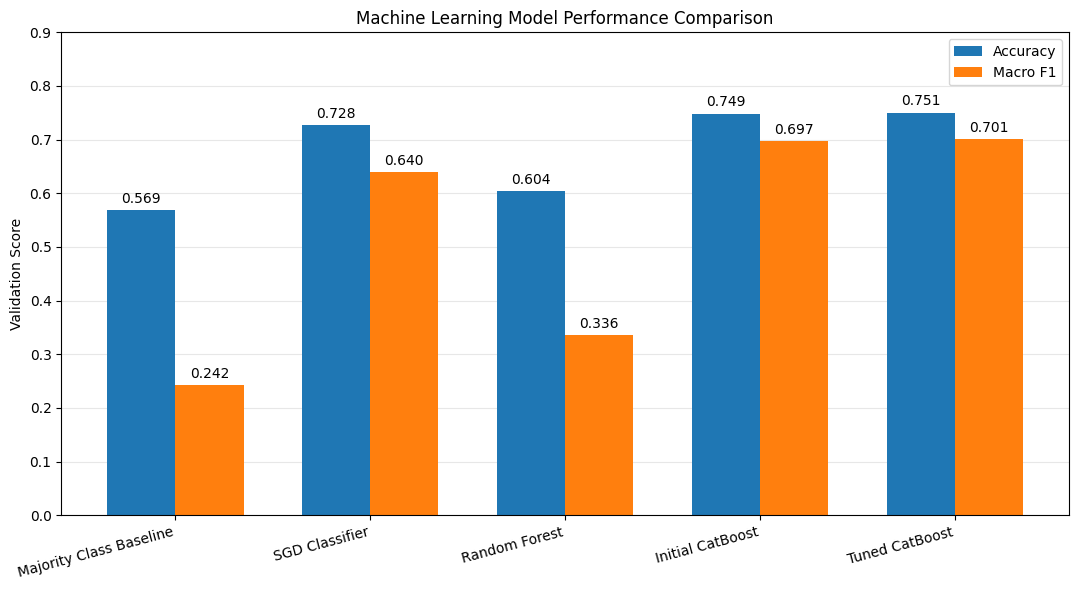

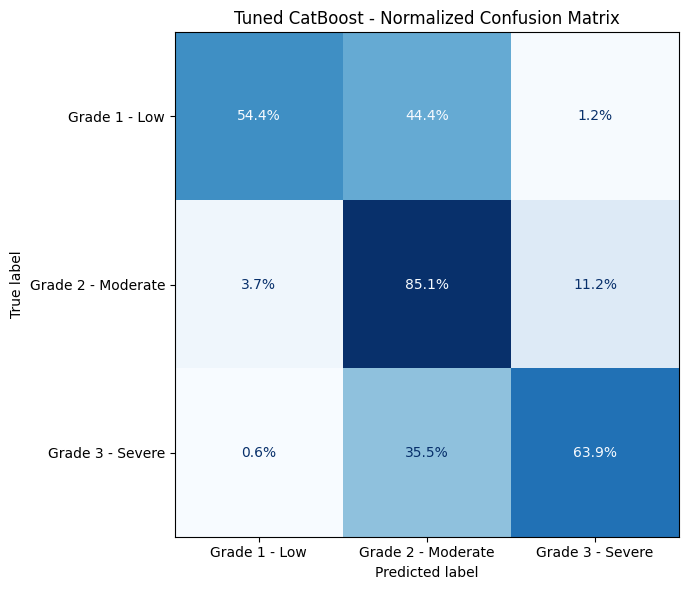


FINAL VISUALIZATION EXPORT SUMMARY
final_model_comparison.csv: Saved (0.30 KB)
model_comparison.png: Saved (182.56 KB)
confusion_matrix.png: Saved (108.89 KB)

All final evaluation visualizations saved!


In [66]:

# Cell 63 - Final Model Evaluation Visualizations
# No model training required

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

# Step 1: Set output folder
output_dir = Path("earthquake_project_outputs")
output_dir.mkdir(exist_ok=True)

# Step 2: Create final model comparison table
final_model_results = pd.concat([
    rf_comparison,
    pd.DataFrame([
        {
            "Model": "Initial CatBoost",
            "Accuracy": cb_accuracy,
            "Macro F1": cb_macro_f1
        },
        {
            "Model": "Tuned CatBoost",
            "Accuracy": cb_tuned_accuracy,
            "Macro F1": cb_tuned_macro_f1
        }
    ])
], ignore_index=True)

print("FINAL MODEL COMPARISON")
print("=" * 60)
display(final_model_results.round(4))

# Save comparison results
final_model_results.to_csv(
    output_dir / "final_model_comparison.csv",
    index=False
)

# Step 3: Plot model performance
fig, ax = plt.subplots(figsize=(11, 6))

x = np.arange(len(final_model_results))
width = 0.35

bars1 = ax.bar(
    x - width / 2,
    final_model_results["Accuracy"],
    width,
    label="Accuracy"
)

bars2 = ax.bar(
    x + width / 2,
    final_model_results["Macro F1"],
    width,
    label="Macro F1"
)

ax.set_title(
    "Machine Learning Model Performance Comparison"
)
ax.set_ylabel("Validation Score")
ax.set_ylim(0, 0.9)

ax.set_xticks(x)
ax.set_xticklabels(
    final_model_results["Model"],
    rotation=15,
    ha="right"
)

ax.legend()
ax.grid(axis="y", alpha=0.3)
ax.set_axisbelow(True)

ax.bar_label(bars1, fmt="%.3f", padding=3)
ax.bar_label(bars2, fmt="%.3f", padding=3)

plt.tight_layout()

fig.savefig(
    output_dir / "model_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

# Step 4: Normalized confusion matrix
fig, ax = plt.subplots(figsize=(8, 6))

ConfusionMatrixDisplay.from_predictions(
    y_val,
    cb_tuned_pred,
    labels=[1, 2, 3],
    display_labels=[
        "Grade 1 - Low",
        "Grade 2 - Moderate",
        "Grade 3 - Severe"
    ],
    normalize="true",
    values_format=".1%",
    cmap="Blues",
    colorbar=False,
    ax=ax
)

ax.set_title(
    "Tuned CatBoost - Normalized Confusion Matrix"
)

plt.tight_layout()

fig.savefig(
    output_dir / "confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

# Step 5: Verify exported results
print("\nFINAL VISUALIZATION EXPORT SUMMARY")
print("=" * 60)

for name in [
    "final_model_comparison.csv",
    "model_comparison.png",
    "confusion_matrix.png"
]:
    path = output_dir / name
    print(f"{name}: Saved ({path.stat().st_size / 1024:.2f} KB)")

print("\nAll final evaluation visualizations saved!")


In [67]:

# Cell 64 - Verify exports and test saved CatBoost model
# No model training required

from pathlib import Path
from catboost import CatBoostClassifier
import pandas as pd
import numpy as np
import json

# Step 1: Locate the project output folder
output_dir = Path("earthquake_project_outputs")

# Step 2: Verify all exported files
expected_files = [
    "catboost_tuned_model.cbm",
    "model_metadata.json",
    "geographic_cv_comparison.csv",
    "final_model_comparison.csv",
    "model_comparison.png",
    "confusion_matrix.png"
]

file_status = pd.DataFrame([
    {
        "File": filename,
        "Exists": (output_dir / filename).exists()
    }
    for filename in expected_files
])

print("PROJECT FILE VERIFICATION")
print("=" * 60)
display(file_status)

# Step 3: Load saved model
model_path = output_dir / "catboost_tuned_model.cbm"

loaded_model = CatBoostClassifier()
loaded_model.load_model(str(model_path))

# Step 4: Load metadata
metadata_path = output_dir / "model_metadata.json"

with open(metadata_path, "r", encoding="utf-8") as file:
    metadata = json.load(file)

print("\nSAVED MODEL INFORMATION")
print("=" * 60)

print("Model:", metadata["model"])
print("Expected features:", len(metadata["feature_names"]))
print("Categorical features:",
      len(metadata["categorical_features"]))

# Step 5: Select 5 sample validation buildings
sample_buildings = X_val_cb.iloc[:5].copy()

sample_buildings = sample_buildings[
    metadata["feature_names"]
]

# Step 6: Predict damage grades
sample_predictions = (
    loaded_model.predict(sample_buildings)
    .ravel()
    .astype(int)
)

# Step 7: Obtain prediction probabilities
sample_probabilities = loaded_model.predict_proba(
    sample_buildings
)

# Step 8: Prepare prediction results
prediction_results = pd.DataFrame({
    "Actual Grade": y_val.iloc[:5].to_numpy(),
    "Predicted Grade": sample_predictions,
    "Confidence": np.max(
        sample_probabilities,
        axis=1
    ).round(4)
})

prediction_results["Correct"] = (
    prediction_results["Actual Grade"] ==
    prediction_results["Predicted Grade"]
)

print("\nSAMPLE BUILDING PREDICTIONS")
print("=" * 60)

display(prediction_results)

# Step 9: Confirm saved model matches previous model
assert np.array_equal(
    sample_predictions,
    cb_tuned_pred[:5]
)

print("\nSaved model prediction verification: PASSED")

if file_status["Exists"].all():
    print("All project output files verified: PASSED")
else:
    print("Some output files are missing. Check Cell 63.")


PROJECT FILE VERIFICATION


,File,Exists
0,catboost_tuned_model.cbm,True
1,model_metadata.json,True
2,geographic_cv_comparison.csv,True
3,final_model_comparison.csv,True
4,model_comparison.png,True
5,confusion_matrix.png,True



SAVED MODEL INFORMATION
Model: CatBoostClassifier
Expected features: 38
Categorical features: 11

SAMPLE BUILDING PREDICTIONS


,Actual Grade,Predicted Grade,Confidence,Correct
0,3,2,0.5484,False
1,2,2,0.5403,True
2,2,1,0.6996,False
3,2,2,0.7269,True
4,3,3,0.8301,True



Saved model prediction verification: PASSED
All project output files verified: PASSED


In [68]:

# Cell 65 - GitHub Project Documentation
# No training required

from pathlib import Path
from importlib.metadata import version, PackageNotFoundError

project_dir = Path.cwd()

# Step 1: Create README
readme = """# Earthquake Damage Prediction

**Project Code:** PRCP-1015

## Project Overview

This project predicts building damage severity using
structural, construction, and geographic characteristics
from the Nepal earthquake building-damage dataset.

### Damage Grades

- Grade 1: Low damage
- Grade 2: Moderate damage
- Grade 3: Severe damage

## Dataset

- Total buildings: 260,601
- Input features: 38
- Target: damage_grade
- Missing values: None detected

## Methodology

1. Data inspection and validation
2. Exploratory Data Analysis (EDA)
3. Feature preprocessing
4. Stratified train-validation splitting
5. Baseline model development
6. CatBoost hyperparameter optimization
7. Feature importance analysis
8. Geographic generalization experiments
9. Model evaluation and export

## Machine Learning Models

| Model | Accuracy | Macro F1 |
|---|---:|---:|
| Majority Class Baseline | 0.5689 | 0.2417 |
| SGD Classifier | 0.7277 | 0.6396 |
| Random Forest | 0.6045 | 0.3359 |
| Initial CatBoost | 0.7487 | 0.6975 |
| Tuned CatBoost | **0.7505** | **0.7015** |

Results above use the original random validation split.

## Selected Model

CatBoost Classifier

- Iterations: 549
- Depth: 8
- Learning rate: 0.07
- Training records: 208,480
- Validation records: 52,121
- Validation accuracy: 75.05%
- Validation macro F1: 0.7015
- Grade 3 recall: 63.93%

## Visualizations

### Model Comparison

![Model Comparison](earthquake_project_outputs/model_comparison.png)

### Confusion Matrix

![Confusion Matrix](earthquake_project_outputs/confusion_matrix.png)

## Geographic Generalization

Additional experiments tested prediction on unseen
geographic regions.

Three-fold geographic cross-validation:

| Feature Set | Pooled Macro F1 | Grade 3 Recall |
|---|---:|---:|
| With geographic identifiers | 0.3389 | 0.0067 |
| Without geographic identifiers | 0.4421 | 0.2290 |

These experiments revealed that model performance
decreases substantially on geographically unseen regions.

Removing geographic identifiers improved macro F1 and
Grade 3 recall in all three geographic folds, although
performance remained insufficient for reliable
severe-damage screening.

## Limitations

- The original random split contains geographic regions
  represented in both training and validation.
- Geographic generalization is substantially weaker.
- Severe damage is frequently misclassified as moderate.
- Unusual age values such as 995 need further investigation.
- Hyperparameter selection and model comparison mean
  the random validation result is not an untouched test score.
- This model is a research prototype, not a validated
  safety-critical structural assessment system.

## Saved Model

The trained model is available at:

`earthquake_project_outputs/catboost_tuned_model.cbm`

Feature names and categorical metadata are stored in:

`earthquake_project_outputs/model_metadata.json`

## Setup

Install dependencies:

```bash
pip install -r requirements.txt
```

Open and run the project Jupyter Notebook using the
corresponding dataset CSV files.

Training cells are not required to load the saved model
for inference.

## Future Improvements

- Improve performance on unseen geographic regions.
- Explore class weighting and probability calibration.
- Evaluate across additional geographic partitions.
- Investigate age anomalies and feature engineering.
- Obtain an independent test dataset for final evaluation.

## Conclusion

The tuned CatBoost classifier achieved the best random
validation results among the tested configurations.

Geographic experiments revealed substantial limitations
in generalizing to new regions, demonstrating the
importance of robust validation in damage prediction.
"""

(project_dir / "README.md").write_text(
    readme, encoding="utf-8"
)

# Step 2: Generate requirements from installed packages
packages = [
    "catboost",
    "numpy",
    "pandas",
    "scikit-learn",
    "matplotlib",
    "seaborn",
    "ipykernel"
]

dependencies = []

for package in packages:
    try:
        dependencies.append(
            f"{package}=={version(package)}"
        )
    except PackageNotFoundError:
        print(f"Not installed, skipped: {package}")

(project_dir / "requirements.txt").write_text(
    "\n".join(dependencies) + "\n",
    encoding="utf-8"
)

# Step 3: Create Git ignore rules
gitignore = """.ipynb_checkpoints/
__pycache__/
catboost_info/
.venv/
venv/
*.pyc

# Raw datasets
train_values.csv
train_labels.csv
test_values.csv
test_labels.csv
data/
dataset/
"""

(project_dir / ".gitignore").write_text(
    gitignore, encoding="utf-8"
)

# Step 4: Verify files
print("GITHUB DOCUMENTATION FILES")
print("=" * 60)

for filename in [
    "README.md",
    "requirements.txt",
    ".gitignore"
]:
    file_path = project_dir / filename

    print(
        filename,
        "- Created:",
        file_path.exists()
    )

print("\nProject folder:")
print(project_dir)

print("\nGitHub documentation preparation: PASSED")


GITHUB DOCUMENTATION FILES
README.md - Created: True
requirements.txt - Created: True
.gitignore - Created: True

Project folder:
E:\datamites project\Hardest capstone 4\Earth quake\Earthquake Damage Prediction

GitHub documentation preparation: PASSED


In [69]:

# Cell 66 - Final GitHub readiness check
# No model training required

from pathlib import Path

project_dir = Path.cwd()
output_dir = project_dir / "earthquake_project_outputs"

# Check Jupyter notebooks
notebooks = list(project_dir.glob("*.ipynb"))

print("JUPYTER NOTEBOOKS")
print("=" * 60)

for notebook in notebooks:
    print(
        notebook.name,
        f"- {notebook.stat().st_size / (1024**2):.2f} MB"
    )

# Check required project files
required_files = [
    project_dir / "README.md",
    project_dir / "requirements.txt",
    project_dir / ".gitignore",
    output_dir / "catboost_tuned_model.cbm",
    output_dir / "model_metadata.json",
    output_dir / "geographic_cv_comparison.csv",
    output_dir / "final_model_comparison.csv",
    output_dir / "model_comparison.png",
    output_dir / "confusion_matrix.png"
]

print("\nREQUIRED FILES")
print("=" * 60)

for file in required_files:
    print(
        "PASS" if file.is_file() else "MISSING",
        "-",
        file.name
    )

# Check files for GitHub browser upload
print("\nLARGE FILE CHECK")
print("=" * 60)

upload_files = notebooks + [
    f for f in required_files if f.is_file()
]

for file in upload_files:
    size_mb = file.stat().st_size / (1024**2)

    if size_mb > 25:
        print(f"CHECK SIZE: {file.name} ({size_mb:.2f} MB)")

# Final verification
all_required = all(f.is_file() for f in required_files)

print("\nFINAL VERIFICATION")
print("=" * 60)
print("Notebook found:", len(notebooks) > 0)
print("Required files present:", all_required)
print(
    "GitHub preparation:",
    "PASSED" if notebooks and all_required else "CHECK FILES"
)


JUPYTER NOTEBOOKS
earthquakedamageprediction.ipynb.ipynb - 0.00 MB
Untitled.ipynb - 1.36 MB

REQUIRED FILES
PASS - README.md
PASS - requirements.txt
PASS - .gitignore
PASS - catboost_tuned_model.cbm
PASS - model_metadata.json
PASS - geographic_cv_comparison.csv
PASS - final_model_comparison.csv
PASS - model_comparison.png
PASS - confusion_matrix.png

LARGE FILE CHECK

FINAL VERIFICATION
Notebook found: True
Required files present: True
GitHub preparation: PASSED
